In [ ]:
# ============================================================
# CELL 1 — SARL-HHNAS: COMPLETE SETUP
# ============================================================

from google.colab import drive
drive.mount("/content/drive")

import os
import sys
import subprocess

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------
PROJECT_DIR = "/content/drive/MyDrive/SARL_HHNAS"

DRIVE_NATS = (
    "/content/drive/MyDrive/NATS_Bench/"
    "TSS_FAST/NATS-tss-v1_0-3ffb9-simple"
)

RESULT_DIR = os.path.join(PROJECT_DIR, "results", "nats_experiments")
FIG_DIR = os.path.join(RESULT_DIR, "figures")

os.makedirs(RESULT_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

# ------------------------------------------------------------
# Python project path
# ------------------------------------------------------------
os.chdir(PROJECT_DIR)

if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)

print("Project:", PROJECT_DIR)

# ------------------------------------------------------------
# Install NATS-Bench if necessary
# ------------------------------------------------------------
try:
    import nats_bench
except ImportError:
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "-q", "nats-bench"]
    )

# ------------------------------------------------------------
# Imports
# ------------------------------------------------------------
from benchmark.nats import NATSBenchTSS
from config import Config

# ------------------------------------------------------------
# Load benchmark
# ------------------------------------------------------------
bench = NATSBenchTSS(
    path=DRIVE_NATS,
    hp="200",
    fast_mode=True,
    verbose=False,
    trial_seed=False
)

print("NATS-Bench loaded.")
print("Architectures:", len(bench.api))

assert len(bench.api) == 15625

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------
cfg = Config(
    params_scale=10.0,
    flops_scale=10.0,
    warmup=8,
    batch_size=8
)

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
from search.core import SearchCore
from search.sarl import SARLHHNAS
from training import meta_train
import inspect

print("\nSARL run signature:")
print(inspect.signature(SARLHHNAS.run))

assert "query_test" in inspect.signature(SARLHHNAS.run).parameters
assert "query_test" in inspect.signature(SearchCore.finalize).parameters
assert "query_test=False" in inspect.getsource(meta_train).replace(" ", "")

print("\n✓ Test-leakage protection detected.")
print("✓ Results directory:", RESULT_DIR)
print("✓ Figures directory:", FIG_DIR)
print("\nSETUP COMPLETE.")

Mounted at /content/drive
Project: /content/drive/MyDrive/SARL_HHNAS
NATS-Bench loaded.
Architectures: 15625

SARL run signature:
(self, training=True, log_path=None, query_test=True)

✓ Test-leakage protection detected.
✓ Results directory: /content/drive/MyDrive/SARL_HHNAS/results/nats_experiments
✓ Figures directory: /content/drive/MyDrive/SARL_HHNAS/results/nats_experiments/figures

SETUP COMPLETE.


SARL-HHNAS NATS-BENCH PILOT EXPERIMENT
Datasets : ['cifar10', 'cifar100', 'ImageNet16-120']
Budgets  : [25, 50, 100]
Seeds    : [0, 1, 2]
Methods  : ['random', 'rea', 'reinforce', 'random-hh', 'greedy-hh', 'cf-hh', 'sarl']
Runs     : 189

[1/189] cifar10 | budget=25 | seed=0 | Random
Best Val=90.3380 | Test=93.0400 | AUC=90.2658 | Time=17.36s

[2/189] cifar10 | budget=25 | seed=0 | REA
Best Val=91.3240 | Test=93.9033 | AUC=90.8435 | Time=11.33s

[3/189] cifar10 | budget=25 | seed=0 | REINFORCE
Best Val=90.1380 | Test=93.2500 | AUC=89.8708 | Time=16.05s

[4/189] cifar10 | budget=25 | seed=0 | Random-HH
Best Val=90.4040 | Test=93.1450 | AUC=90.2421 | Time=14.64s

[5/189] cifar10 | budget=25 | seed=0 | Greedy-HH
Best Val=90.7120 | Test=93.6550 | AUC=90.5561 | Time=13.31s

[6/189] cifar10 | budget=25 | seed=0 | CF-HH
Best Val=91.4227 | Test=94.2933 | AUC=90.7170 | Time=8.36s

[7/189] cifar10 | budget=25 | seed=0 | SARL-Online
Best Val=90.3620 | Test=93.3950 | AUC=90.3025 | Time=12.98s

[8/

,dataset,budget,method,best_val_mean,best_val_std,test_mean,test_std,search_auc_mean,search_auc_std,params_mean,flops_mean,time_mean
0,ImageNet16-120,25,CF-HH,45.116667,0.534114,45.014815,0.805888,43.752148,1.624871,0.694216,24.23564,3.253091
1,ImageNet16-120,25,Greedy-HH,44.994444,0.358366,44.616667,0.233333,43.704815,1.583301,0.613203,21.28652,8.372383
2,ImageNet16-120,25,REA,45.988889,0.458964,45.931481,0.597689,44.620741,1.549362,0.793896,27.84012,2.952429
3,ImageNet16-120,25,REINFORCE,44.761111,0.413096,44.772222,0.694089,42.145704,1.908497,0.694216,24.23564,1.411425
4,ImageNet16-120,25,Random,45.192593,0.470662,45.340741,0.428367,44.393333,0.905387,0.909256,32.09996,0.388195
...,...,...,...,...,...,...,...,...,...,...,...,...
58,cifar100,100,REA,72.486667,1.158754,72.547778,1.425920,71.836533,1.052647,1.060649,150.65738,16.781942
59,cifar100,100,REINFORCE,71.487778,0.896910,71.602222,1.338413,70.109911,0.911952,0.864276,121.82154,7.854417
60,cifar100,100,Random,71.790000,0.979234,72.181111,1.544475,71.555322,0.798754,0.845609,119.20010,1.852437
61,cifar100,100,Random-HH,73.180000,0.392315,73.117778,0.383917,71.738022,0.424074,1.079316,153.27882,13.057048


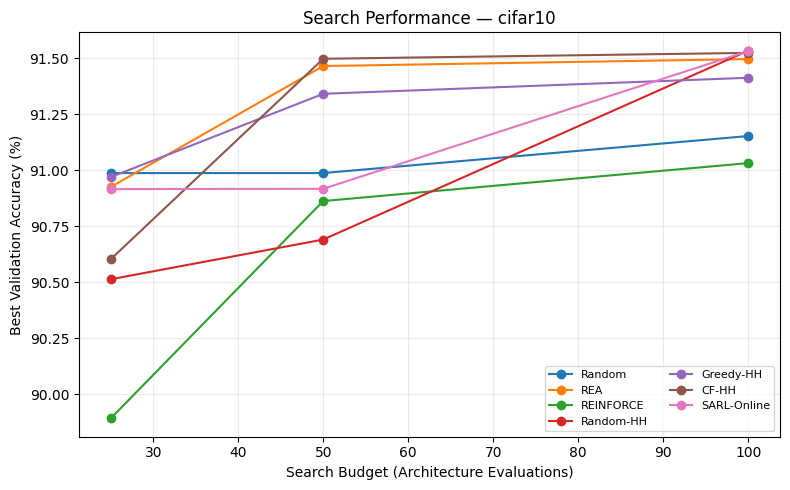

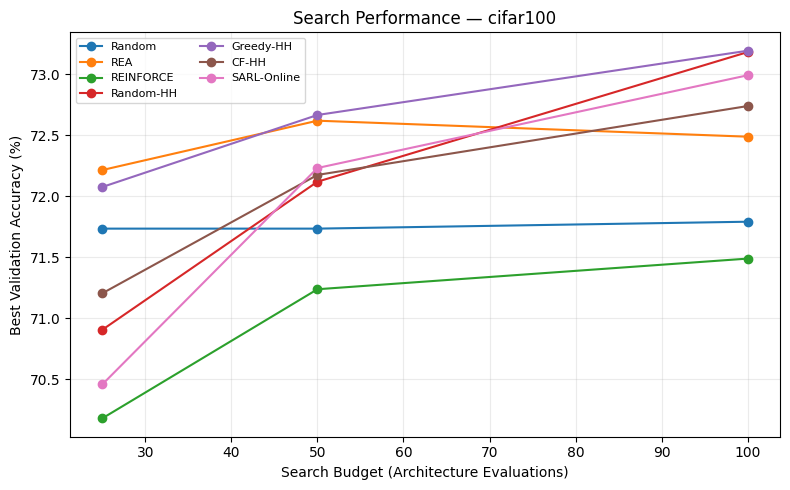

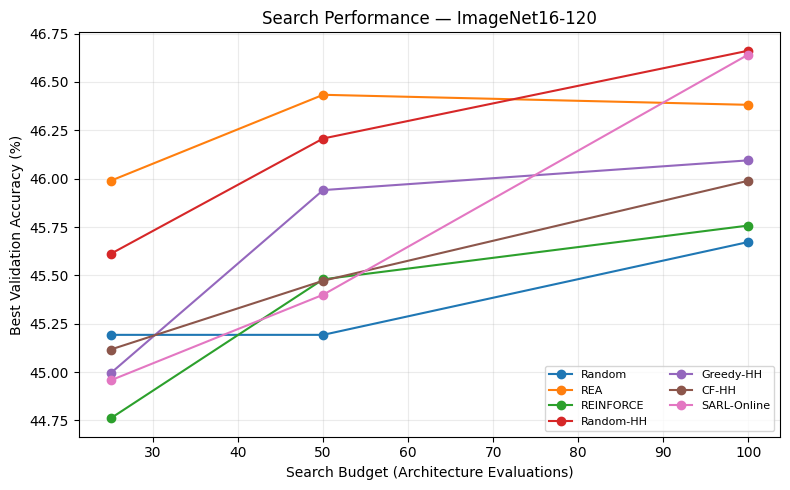

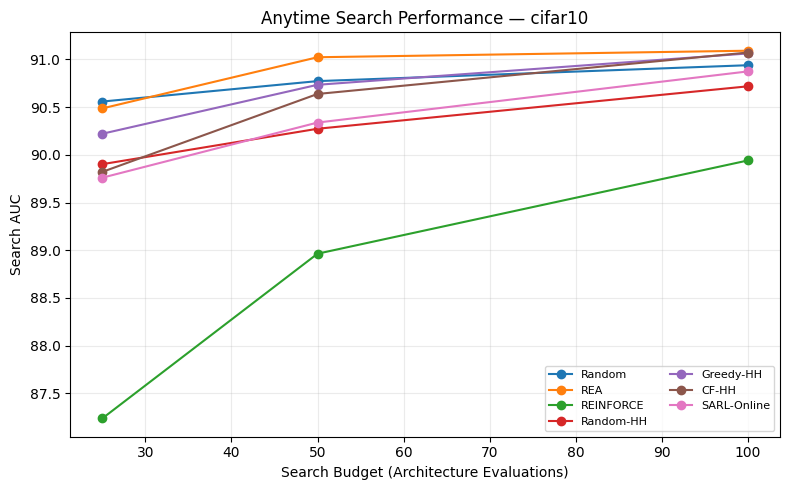

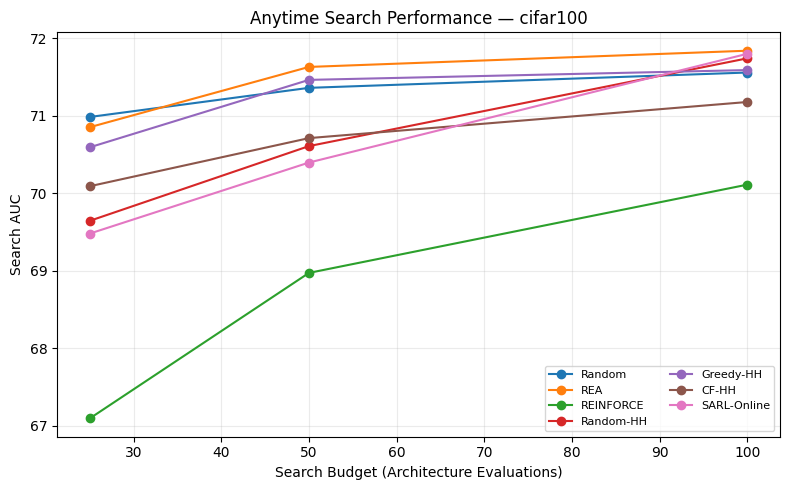

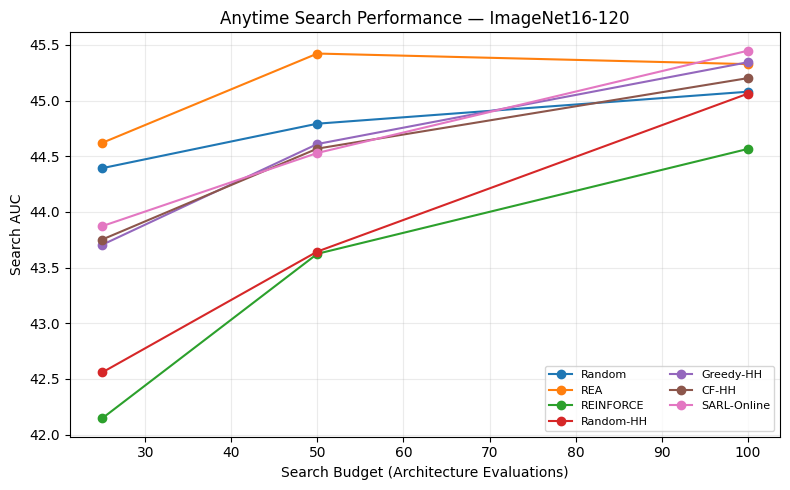

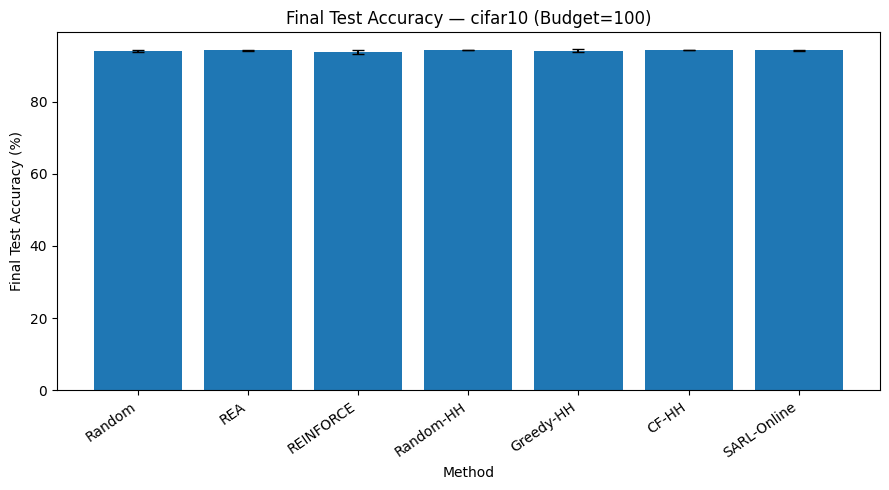

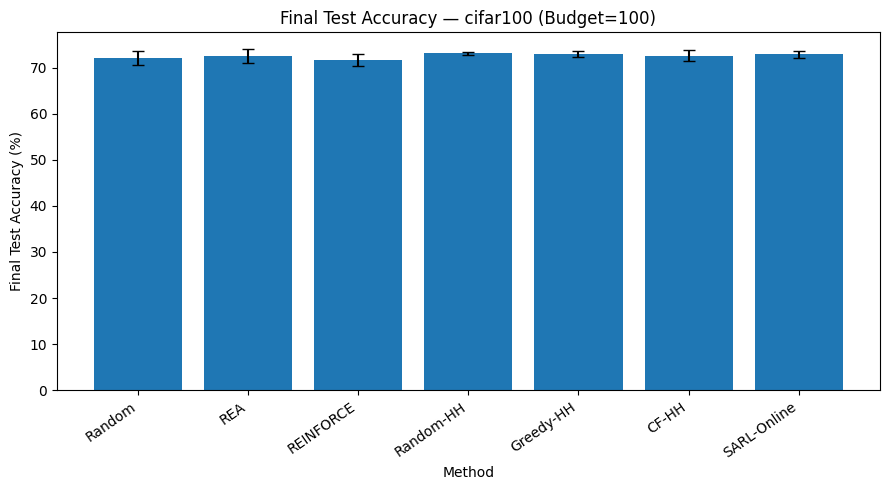

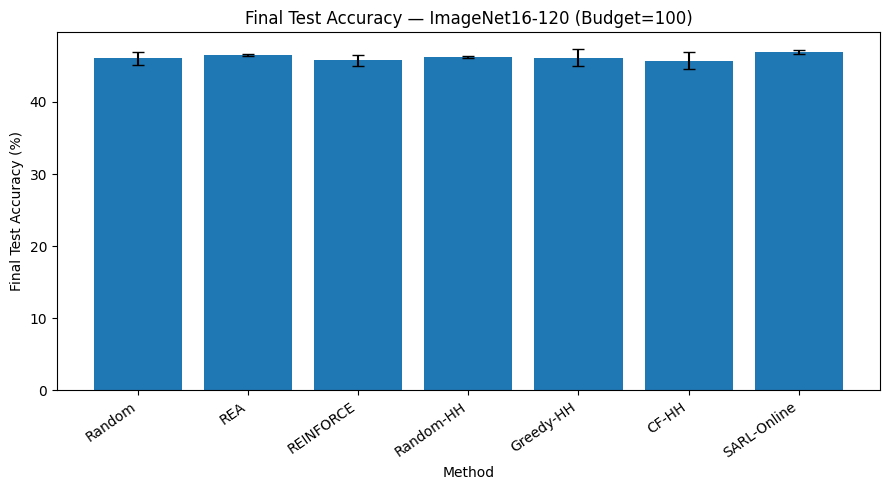

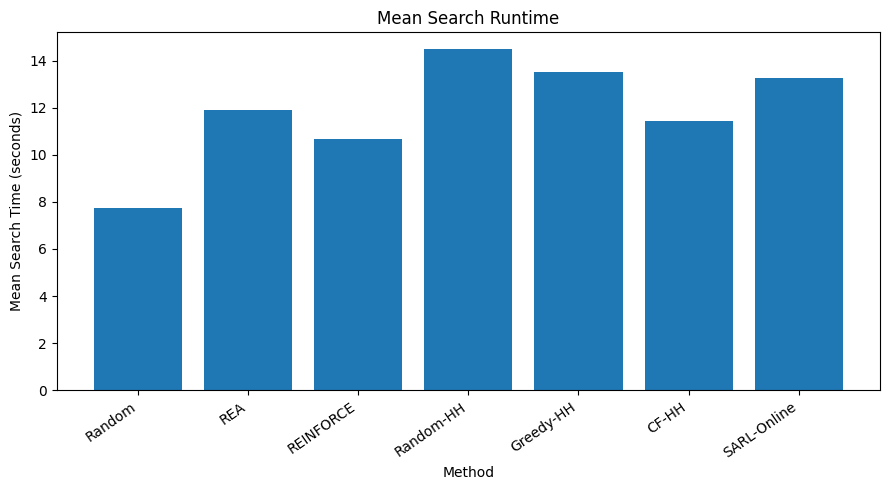


FILES GENERATED
Raw results : /content/drive/MyDrive/SARL_HHNAS/results/nats_experiments/pilot_all_results.csv
Summary     : /content/drive/MyDrive/SARL_HHNAS/results/nats_experiments/pilot_summary.csv
Figures     : /content/drive/MyDrive/SARL_HHNAS/results/nats_experiments/figures

IMPORTANT:
These are PILOT results. SARL currently means SARL-Online, not SARL-Meta.


In [ ]:
# ============================================================
# CELL 2 — RUN NATS-BENCH EXPERIMENTS + SAVE RESULTS + FIGURES
# ============================================================

import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from copy import deepcopy

from experiments import build_method
from evaluation import search_metrics


# ============================================================
# EXPERIMENT SETTINGS
# ============================================================

DATASETS = [
    "cifar10",
    "cifar100",
    "ImageNet16-120"
]

BUDGETS = [25, 50, 100]

SEEDS = [0, 1, 2]

METHODS = [
    "random",
    "rea",
    "reinforce",
    "random-hh",
    "greedy-hh",
    "cf-hh",
    "sarl"
]

DISPLAY_NAMES = {
    "random": "Random",
    "rea": "REA",
    "reinforce": "REINFORCE",
    "random-hh": "Random-HH",
    "greedy-hh": "Greedy-HH",
    "cf-hh": "CF-HH",
    "sarl": "SARL-Online"
}


# ============================================================
# RUN EXPERIMENTS
# ============================================================

all_rows = []

total_runs = (
    len(DATASETS) *
    len(BUDGETS) *
    len(SEEDS) *
    len(METHODS)
)

run_number = 0
start_all = time.time()

print("=" * 75)
print("SARL-HHNAS NATS-BENCH PILOT EXPERIMENT")
print("=" * 75)
print("Datasets :", DATASETS)
print("Budgets  :", BUDGETS)
print("Seeds    :", SEEDS)
print("Methods  :", METHODS)
print("Runs     :", total_runs)
print("=" * 75)


for dataset in DATASETS:

    for budget in BUDGETS:

        for seed in SEEDS:

            for method in METHODS:

                run_number += 1

                print(
                    f"\n[{run_number}/{total_runs}] "
                    f"{dataset} | budget={budget} | "
                    f"seed={seed} | {DISPLAY_NAMES[method]}"
                )

                c = deepcopy(cfg)

                c.dataset = dataset
                c.budget = budget
                c.seed = seed
                c.beta = 0.0

                # --------------------------------------------
                # Build method
                # --------------------------------------------
                model = build_method(
                    method,
                    bench,
                    c
                )

                # --------------------------------------------
                # Run search
                # --------------------------------------------
                t0 = time.time()

                if method == "sarl":

                    result = model.run(
                        training=True,
                        query_test=True
                    )

                else:

                    result = model.run()

                elapsed = time.time() - t0

                # --------------------------------------------
                # Metrics
                # --------------------------------------------
                metrics = search_metrics(result)

                row = {
                    "dataset": dataset,
                    "budget": budget,
                    "seed": seed,
                    "method": DISPLAY_NAMES[method],
                    "search_time_sec": elapsed,
                    **metrics
                }

                all_rows.append(row)

                print(
                    f"Best Val={metrics['best_val_acc']:.4f} | "
                    f"Test={metrics['test_acc']:.4f} | "
                    f"AUC={metrics['search_auc']:.4f} | "
                    f"Time={elapsed:.2f}s"
                )

                # --------------------------------------------
                # SAVE AFTER EVERY RUN
                # prevents losing results if Colab disconnects
                # --------------------------------------------
                pd.DataFrame(all_rows).to_csv(
                    os.path.join(
                        RESULT_DIR,
                        "pilot_all_results.csv"
                    ),
                    index=False
                )


# ============================================================
# FINAL DATAFRAME
# ============================================================

df = pd.DataFrame(all_rows)

RESULT_FILE = os.path.join(
    RESULT_DIR,
    "pilot_all_results.csv"
)

df.to_csv(
    RESULT_FILE,
    index=False
)

print("\n" + "=" * 75)
print("EXPERIMENT COMPLETED")
print("=" * 75)

print("Runs completed:", len(df))
print(
    "Total time:",
    round((time.time() - start_all) / 60, 2),
    "minutes"
)

print("Search queries:", bench.search_queries)
print("Test queries:", bench.test_queries)

print("\nSaved:")
print(RESULT_FILE)


# ============================================================
# SUMMARY TABLE
# ============================================================

summary = (
    df.groupby(
        ["dataset", "budget", "method"],
        as_index=False
    )
    .agg(
        best_val_mean=("best_val_acc", "mean"),
        best_val_std=("best_val_acc", "std"),

        test_mean=("test_acc", "mean"),
        test_std=("test_acc", "std"),

        search_auc_mean=("search_auc", "mean"),
        search_auc_std=("search_auc", "std"),

        params_mean=("params", "mean"),
        flops_mean=("flops", "mean"),

        time_mean=("search_time_sec", "mean")
    )
)

SUMMARY_FILE = os.path.join(
    RESULT_DIR,
    "pilot_summary.csv"
)

summary.to_csv(
    SUMMARY_FILE,
    index=False
)

print("\nSummary saved:")
print(SUMMARY_FILE)

display(summary)


# ============================================================
# FIGURE 1
# Mean final validation accuracy vs query budget
# ============================================================

for dataset in DATASETS:

    temp = summary[
        summary["dataset"] == dataset
    ]

    plt.figure(figsize=(8, 5))

    for method in DISPLAY_NAMES.values():

        x = temp[temp["method"] == method]

        if len(x) == 0:
            continue

        plt.plot(
            x["budget"],
            x["best_val_mean"],
            marker="o",
            label=method
        )

    plt.xlabel("Search Budget (Architecture Evaluations)")
    plt.ylabel("Best Validation Accuracy (%)")
    plt.title(
        f"Search Performance — {dataset}"
    )

    plt.grid(
        True,
        alpha=0.25
    )

    plt.legend(
        fontsize=8,
        ncol=2
    )

    plt.tight_layout()

    filename = os.path.join(
        FIG_DIR,
        f"{dataset}_validation_vs_budget.png"
    )

    plt.savefig(
        filename,
        dpi=600,
        bbox_inches="tight"
    )

    plt.show()


# ============================================================
# FIGURE 2
# Search AUC vs budget
# ============================================================

for dataset in DATASETS:

    temp = summary[
        summary["dataset"] == dataset
    ]

    plt.figure(figsize=(8, 5))

    for method in DISPLAY_NAMES.values():

        x = temp[temp["method"] == method]

        if len(x) == 0:
            continue

        plt.plot(
            x["budget"],
            x["search_auc_mean"],
            marker="o",
            label=method
        )

    plt.xlabel("Search Budget (Architecture Evaluations)")
    plt.ylabel("Search AUC")
    plt.title(
        f"Anytime Search Performance — {dataset}"
    )

    plt.grid(
        True,
        alpha=0.25
    )

    plt.legend(
        fontsize=8,
        ncol=2
    )

    plt.tight_layout()

    filename = os.path.join(
        FIG_DIR,
        f"{dataset}_search_auc.png"
    )

    plt.savefig(
        filename,
        dpi=600,
        bbox_inches="tight"
    )

    plt.show()


# ============================================================
# FIGURE 3
# Final test accuracy at largest budget
# ============================================================

MAX_BUDGET = max(BUDGETS)

for dataset in DATASETS:

    temp = df[
        (df["dataset"] == dataset) &
        (df["budget"] == MAX_BUDGET)
    ]

    plot_data = (
        temp.groupby("method")["test_acc"]
        .agg(["mean", "std"])
        .reindex(DISPLAY_NAMES.values())
        .dropna(how="all")
    )

    plt.figure(figsize=(9, 5))

    plt.bar(
        plot_data.index,
        plot_data["mean"],
        yerr=plot_data["std"],
        capsize=4
    )

    plt.ylabel("Final Test Accuracy (%)")
    plt.xlabel("Method")

    plt.title(
        f"Final Test Accuracy — {dataset} "
        f"(Budget={MAX_BUDGET})"
    )

    plt.xticks(
        rotation=35,
        ha="right"
    )

    plt.tight_layout()

    filename = os.path.join(
        FIG_DIR,
        f"{dataset}_test_accuracy.png"
    )

    plt.savefig(
        filename,
        dpi=600,
        bbox_inches="tight"
    )

    plt.show()


# ============================================================
# FIGURE 4
# Computational search time
# ============================================================

time_summary = (
    df.groupby("method")["search_time_sec"]
    .mean()
    .reindex(DISPLAY_NAMES.values())
    .dropna()
)

plt.figure(figsize=(9, 5))

plt.bar(
    time_summary.index,
    time_summary.values
)

plt.ylabel("Mean Search Time (seconds)")
plt.xlabel("Method")
plt.title("Mean Search Runtime")

plt.xticks(
    rotation=35,
    ha="right"
)

plt.tight_layout()

filename = os.path.join(
    FIG_DIR,
    "mean_search_time.png"
)

plt.savefig(
    filename,
    dpi=600,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FINAL CHECK
# ============================================================

print("\n" + "=" * 75)
print("FILES GENERATED")
print("=" * 75)

print("Raw results :", RESULT_FILE)
print("Summary     :", SUMMARY_FILE)
print("Figures     :", FIG_DIR)

print("\nIMPORTANT:")
print(
    "These are PILOT results. "
    "SARL currently means SARL-Online, not SARL-Meta."
)

In [ ]:
from pathlib import Path
import re

FILE = Path(
    "/content/drive/MyDrive/SARL_HHNAS/run_final_experiments.py"
)

text = FILE.read_text(encoding="utf-8")

new_function = '''def completed_keys(path):

    path = Path(path)

    if not path.exists():
        return set()

    df = pd.read_csv(
        path,
        keep_default_na=False
    )

    keys = set()

    for _, r in df.iterrows():

        source_dataset = str(
            r.get("source_dataset", "")
        ).strip()

        policy_seed = str(
            r.get("policy_seed", "")
        ).strip()

        # Normalize numeric policy seeds such as 1000.0 -> 1000
        if policy_seed:
            try:
                policy_seed = str(
                    int(float(policy_seed))
                )
            except ValueError:
                pass

        keys.add(
            (
                str(r["dataset"]).strip(),
                int(r["budget"]),
                int(r["search_seed"]),
                str(r["method"]).strip(),
                source_dataset,
                policy_seed
            )
        )

    return keys
'''

pattern = r'def completed_keys\(path\):.*?return keys'

new_text, count = re.subn(
    pattern,
    new_function.rstrip(),
    text,
    count=1,
    flags=re.DOTALL
)

if count != 1:
    raise RuntimeError(
        f"Could not safely replace completed_keys(). "
        f"Matches found: {count}"
    )

FILE.write_text(
    new_text,
    encoding="utf-8"
)

print("✓ completed_keys() updated successfully")
print("File:", FILE)

✓ completed_keys() updated successfully
File: /content/drive/MyDrive/SARL_HHNAS/run_final_experiments.py


In [ ]:
# ============================================================
# SARL-META TRANSFER SANITY TEST
# Small experiment before expensive final meta-training
# ============================================================

import os
import sys
import copy
import time

PROJECT_DIR = "/content/drive/MyDrive/SARL_HHNAS"
os.chdir(PROJECT_DIR)

if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)

from benchmark.nats import NATSBenchTSS
from config import Config
from training import meta_train, frozen_transfer, finetuned_transfer

NATS_DIR = (
    "/content/drive/MyDrive/NATS_Bench/"
    "TSS_FAST/NATS-tss-v1_0-3ffb9-simple"
)

# Fresh benchmark counters
bench_meta = NATSBenchTSS(
    path=NATS_DIR,
    hp="200",
    fast_mode=True,
    verbose=False,
    trial_seed=False
)

cfg_meta = Config(
    params_scale=10.0,
    flops_scale=10.0,
    warmup=8,
    batch_size=8
)

# ------------------------------------------------------------
# 1. META-TRAIN ON CIFAR-10
# Only 5 x 25 = 125 queries for sanity testing
# ------------------------------------------------------------

cfg_meta.dataset = "cifar10"
cfg_meta.seed = 100

print("=" * 70)
print("1. META-TRAINING ON CIFAR-10")
print("=" * 70)

agent, summaries = meta_train(
    bench_meta,
    cfg_meta,
    episodes=5,
    episode_budget=25
)

print("Episodes:", len(summaries))
print("Source summaries:", summaries)
print("Search queries:", bench_meta.search_queries)
print("Test queries:", bench_meta.test_queries)

assert bench_meta.search_queries == 125
assert bench_meta.test_queries == 0

print("PASS: source meta-training used zero test queries.")


# ------------------------------------------------------------
# Save counters before target search
# ------------------------------------------------------------

search_before = bench_meta.search_queries
test_before = bench_meta.test_queries


# ------------------------------------------------------------
# 2. FROZEN TRANSFER TO CIFAR-100
# ------------------------------------------------------------

target_cfg = copy.deepcopy(cfg_meta)

target_cfg.dataset = "cifar100"
target_cfg.seed = 0
target_cfg.budget = 50
target_cfg.beta = 0.0

print("\n" + "=" * 70)
print("2. FROZEN TRANSFER: CIFAR-10 -> CIFAR-100")
print("=" * 70)

t0 = time.time()

result = frozen_transfer(
    bench_meta,
    target_cfg,
    copy.deepcopy(agent)
)

elapsed = time.time() - t0

print("Best validation accuracy:", result["best_val_acc"])
print("Final test accuracy:", result["test_acc"])
print("Params:", result["params"])
print("FLOPs:", result["flops"])
print("Target search time:", elapsed)

target_search_queries = (
    bench_meta.search_queries - search_before
)

target_test_queries = (
    bench_meta.test_queries - test_before
)

print("\nTarget search queries:", target_search_queries)
print("Target test queries:", target_test_queries)

assert target_search_queries == 50
assert target_test_queries == 1

print("\nPASS: Frozen transfer performed 50 target validation queries.")
print("PASS: Test set was queried exactly once after target search.")
print("PASS: SARL-Meta transfer pipeline is leakage-safe.")

1. META-TRAINING ON CIFAR-10
Episodes: 5
Source summaries: [90.96933333089193, 91.05199998901367, 91.41800000122069, 91.50533331298828, 89.86799998046874]
Search queries: 125
Test queries: 0
PASS: source meta-training used zero test queries.

2. FROZEN TRANSFER: CIFAR-10 -> CIFAR-100
Best validation accuracy: 71.15999996337891
Final test accuracy: 71.15999997965496
Params: 1.079316
FLOPs: 153.27882
Target search time: 14.369373321533203

Target search queries: 50
Target test queries: 1

PASS: Frozen transfer performed 50 target validation queries.
PASS: Test set was queried exactly once after target search.
PASS: SARL-Meta transfer pipeline is leakage-safe.


In [ ]:
# ============================================================
# FINAL CODE AUDIT — print only files needed for final runner
# ============================================================

from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/SARL_HHNAS")

files = [
    "config.py",
    "experiments.py",
    "agents/dqn.py",
    "search/baselines.py",
    "heuristics/llhs.py",
    "benchmark/architecture.py",
]

for name in files:
    path = PROJECT / name

    print("\n\n" + "=" * 100)
    print(name)
    print("=" * 100)

    if path.exists():
        print(path.read_text(encoding="utf-8"))
    else:
        print("FILE NOT FOUND")



config.py
from dataclasses import dataclass

@dataclass
class Config:
    dataset: str = 'cifar10'
    budget: int = 100
    seed: int = 42
    beta: float = 0.0
    discovery_bonus: float = 0.05
    utility_alpha: float = 0.3
    history_window: int = 20
    stagnation_max: int = 20
    gamma: float = 0.95
    lr: float = 1e-3
    batch_size: int = 64
    replay_size: int = 10000
    hidden: int = 128
    epsilon_start: float = 1.0
    epsilon_end: float = 0.05
    epsilon_decay_steps: int = 5000
    target_update: int = 100
    grad_clip: float = 1.0
    warmup: int = 64
    t0: float = 0.20
    tmin: float = 0.01
    params_scale: float = 1.0
    flops_scale: float = 1.0
    state_mask: tuple = ()
    shuffle_state: bool = False



experiments.py
import csv, os
from copy import deepcopy
from search.sarl import SARLHHNAS
from search.baselines import HHBaseline
from search.direct_baselines import RandomSearch, RegularizedEvolution, ReinforceNAS
from evaluation import search_metrics


In [ ]:
from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/SARL_HHNAS")

files = [
    "config.py",
    "experiments.py",
    "agents/dqn.py",
    "search/baselines.py",
]

for name in files:
    path = PROJECT / name

    print("\n" + "=" * 100)
    print(name)
    print("=" * 100)

    if path.exists():
        print(path.read_text(encoding="utf-8"))
    else:
        print("FILE NOT FOUND:", path)


config.py
from dataclasses import dataclass

@dataclass
class Config:
    dataset: str = 'cifar10'
    budget: int = 100
    seed: int = 42
    beta: float = 0.0
    discovery_bonus: float = 0.05
    utility_alpha: float = 0.3
    history_window: int = 20
    stagnation_max: int = 20
    gamma: float = 0.95
    lr: float = 1e-3
    batch_size: int = 64
    replay_size: int = 10000
    hidden: int = 128
    epsilon_start: float = 1.0
    epsilon_end: float = 0.05
    epsilon_decay_steps: int = 5000
    target_update: int = 100
    grad_clip: float = 1.0
    warmup: int = 64
    t0: float = 0.20
    tmin: float = 0.01
    params_scale: float = 1.0
    flops_scale: float = 1.0
    state_mask: tuple = ()
    shuffle_state: bool = False


experiments.py
import csv, os
from copy import deepcopy
from search.sarl import SARLHHNAS
from search.baselines import HHBaseline
from search.direct_baselines import RandomSearch, RegularizedEvolution, ReinforceNAS
from evaluation import search_metrics

M

In [ ]:
from pathlib import Path

P = Path("/content/drive/MyDrive/SARL_HHNAS")

for name in ["config.py", "experiments.py", "agents/dqn.py"]:
    path = P / name

    print("\n" + "=" * 90)
    print(name)
    print("=" * 90)

    if path.exists():
        print(path.read_text(encoding="utf-8"))
    else:
        print("NOT FOUND")


config.py
from dataclasses import dataclass

@dataclass
class Config:
    dataset: str = 'cifar10'
    budget: int = 100
    seed: int = 42
    beta: float = 0.0
    discovery_bonus: float = 0.05
    utility_alpha: float = 0.3
    history_window: int = 20
    stagnation_max: int = 20
    gamma: float = 0.95
    lr: float = 1e-3
    batch_size: int = 64
    replay_size: int = 10000
    hidden: int = 128
    epsilon_start: float = 1.0
    epsilon_end: float = 0.05
    epsilon_decay_steps: int = 5000
    target_update: int = 100
    grad_clip: float = 1.0
    warmup: int = 64
    t0: float = 0.20
    tmin: float = 0.01
    params_scale: float = 1.0
    flops_scale: float = 1.0
    state_mask: tuple = ()
    shuffle_state: bool = False


experiments.py
import csv, os
from copy import deepcopy
from search.sarl import SARLHHNAS
from search.baselines import HHBaseline
from search.direct_baselines import RandomSearch, RegularizedEvolution, ReinforceNAS
from evaluation import search_metrics

M

In [ ]:
# ============================================================
# CELL 1
# Fix DDQN reproducibility and create final experiment runner
# ============================================================

from pathlib import Path
import os
import shutil

PROJECT = Path("/content/drive/MyDrive/SARL_HHNAS")
os.chdir(PROJECT)

# ============================================================
# A. FIX DDQN REPRODUCIBILITY
# ============================================================

DQN = PROJECT / "agents/dqn.py"

backup = PROJECT / "agents/dqn.py.pre_final_backup"
if not backup.exists():
    shutil.copy2(DQN, backup)

dqn_code = r'''import math, random
from collections import deque, namedtuple

import numpy as np
import torch
from torch import nn


Transition = namedtuple(
    'Transition',
    'state action reward next_state done'
)


class ReplayBuffer:
    def __init__(self, n, rng=None):
        self.data = deque(maxlen=n)
        self.rng = rng or random.Random()

    def push(self, *x):
        self.data.append(Transition(*x))

    def __len__(self):
        return len(self.data)

    def sample(self, n):
        return self.rng.sample(list(self.data), n)


class QNet(nn.Module):
    def __init__(self, state_dim=13, actions=6, hidden=128):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(state_dim, hidden),
            nn.ReLU(),
            nn.Linear(hidden, hidden),
            nn.ReLU(),
            nn.Linear(hidden, actions)
        )

    def forward(self, x):
        return self.net(x)


class DDQNAgent:
    def __init__(self, cfg, device=None):

        self.cfg = cfg
        self.device = device or (
            'cuda' if torch.cuda.is_available() else 'cpu'
        )

        # ----------------------------------------------------
        # Reproducibility
        # ----------------------------------------------------
        self.rng = random.Random(int(cfg.seed))

        np.random.seed(int(cfg.seed))
        torch.manual_seed(int(cfg.seed))

        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(int(cfg.seed))

        # ----------------------------------------------------
        # Networks
        # ----------------------------------------------------
        self.online = QNet(
            hidden=cfg.hidden
        ).to(self.device)

        self.target = QNet(
            hidden=cfg.hidden
        ).to(self.device)

        self.target.load_state_dict(
            self.online.state_dict()
        )

        self.target.eval()

        self.opt = torch.optim.Adam(
            self.online.parameters(),
            lr=cfg.lr
        )

        self.buffer = ReplayBuffer(
            cfg.replay_size,
            rng=self.rng
        )

        self.steps = 0

    def epsilon(self):

        return (
            self.cfg.epsilon_end
            +
            (
                self.cfg.epsilon_start
                -
                self.cfg.epsilon_end
            )
            *
            math.exp(
                -self.steps /
                max(
                    1,
                    self.cfg.epsilon_decay_steps
                )
            )
        )

    def act(self, state, training=True):

        eps = (
            self.epsilon()
            if training
            else 0.0
        )

        if (
            training
            and self.rng.random() < eps
        ):
            return self.rng.randrange(6), eps

        with torch.no_grad():

            x = torch.tensor(
                state,
                dtype=torch.float32,
                device=self.device
            ).unsqueeze(0)

            return (
                int(
                    self.online(x)
                    .argmax(1)
                    .item()
                ),
                eps
            )

    def learn(self):

        if len(self.buffer) < max(
            self.cfg.warmup,
            self.cfg.batch_size
        ):
            return None

        b = self.buffer.sample(
            self.cfg.batch_size
        )

        s = torch.tensor(
            np.array(
                [x.state for x in b]
            ),
            dtype=torch.float32,
            device=self.device
        )

        a = torch.tensor(
            [x.action for x in b],
            dtype=torch.long,
            device=self.device
        ).unsqueeze(1)

        r = torch.tensor(
            [x.reward for x in b],
            dtype=torch.float32,
            device=self.device
        )

        ns = torch.tensor(
            np.array(
                [x.next_state for x in b]
            ),
            dtype=torch.float32,
            device=self.device
        )

        d = torch.tensor(
            [x.done for x in b],
            dtype=torch.float32,
            device=self.device
        )

        q = self.online(s).gather(
            1, a
        ).squeeze(1)

        with torch.no_grad():

            na = self.online(ns).argmax(
                1,
                keepdim=True
            )

            nq = self.target(ns).gather(
                1, na
            ).squeeze(1)

            y = (
                r
                +
                self.cfg.gamma
                *
                nq
                *
                (1 - d)
            )

        loss = nn.functional.smooth_l1_loss(
            q,
            y
        )

        self.opt.zero_grad()

        loss.backward()

        nn.utils.clip_grad_norm_(
            self.online.parameters(),
            self.cfg.grad_clip
        )

        self.opt.step()

        self.steps += 1

        if (
            self.steps
            %
            self.cfg.target_update
            ==
            0
        ):
            self.target.load_state_dict(
                self.online.state_dict()
            )

        return float(loss.item())
'''

DQN.write_text(
    dqn_code,
    encoding="utf-8"
)

print("✓ DDQN reproducibility fixed.")


# ============================================================
# B. CREATE FINAL RUNNER
# ============================================================

RUNNER = PROJECT / "run_final_experiments.py"

runner_code = r'''
import os
import sys
import csv
import copy
import time
import random
from pathlib import Path

import numpy as np
import pandas as pd
import torch

from config import Config
from benchmark.nats import NATSBenchTSS
from experiments import build_method
from training import meta_train
from search.sarl import SARLHHNAS
from evaluation import search_metrics


# ============================================================
# PATHS
# ============================================================

PROJECT = Path(
    "/content/drive/MyDrive/SARL_HHNAS"
)

NATS_DIR = Path(
    "/content/drive/MyDrive/NATS_Bench/"
    "TSS_FAST/NATS-tss-v1_0-3ffb9-simple"
)

ROOT = PROJECT / "results" / "final"

RAW = ROOT / "raw"
CHECKPOINTS = ROOT / "checkpoints"
LOGS = ROOT / "logs"
SUMMARIES = ROOT / "summaries"
FIGURES = ROOT / "figures"

for p in [
    ROOT,
    RAW,
    CHECKPOINTS,
    LOGS,
    SUMMARIES,
    FIGURES
]:
    p.mkdir(
        parents=True,
        exist_ok=True
    )


# ============================================================
# FINAL EXPERIMENT SETTINGS
# ============================================================

DATASETS = [
    "cifar10",
    "cifar100",
    "ImageNet16-120"
]

BUDGETS = [
    100,
    250,
    500
]

# 10 independent search seeds.
# Increase to 30 later if required by final protocol.
SEARCH_SEEDS = list(range(10))

# Independent policy seeds.
POLICY_SEEDS = [
    1000,
    1001,
    1002
]

BASELINES = [
    "random",
    "rea",
    "reinforce",
    "random-hh",
    "greedy-hh",
    "cf-hh"
]

META_EPISODES = 100

META_EPISODE_BUDGET = 100

SOURCE_DATASET = "cifar10"


# ============================================================
# CONFIG
# ============================================================

base_cfg = Config(
    params_scale=10.0,
    flops_scale=10.0,
    warmup=64,
    batch_size=64
)


# ============================================================
# BENCHMARK
# ============================================================

bench = NATSBenchTSS(
    path=str(NATS_DIR),
    hp="200",
    fast_mode=True,
    verbose=False,
    trial_seed=False
)


# ============================================================
# REPRODUCIBILITY
# ============================================================

def seed_everything(seed):

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


# ============================================================
# SAFE APPEND
# ============================================================

def append_csv(path, row):

    path = Path(path)

    exists = path.exists()

    with open(
        path,
        "a",
        newline="",
        encoding="utf-8"
    ) as f:

        writer = csv.DictWriter(
            f,
            fieldnames=list(row.keys())
        )

        if not exists:
            writer.writeheader()

        writer.writerow(row)


# ============================================================
# COMPLETED RUN DETECTION
# ============================================================

def completed_keys(path):

    path = Path(path)

    if not path.exists():
        return set()

    df = pd.read_csv(path)

    keys = set()

    for _, r in df.iterrows():

        keys.add(
            (
                str(r["dataset"]),
                int(r["budget"]),
                int(r["search_seed"]),
                str(r["method"]),
                str(r.get(
                    "source_dataset",
                    ""
                )),
                str(r.get(
                    "policy_seed",
                    ""
                ))
            )
        )

    return keys


# ============================================================
# POLICY CHECKPOINT
# ============================================================

def save_agent(agent, path, metadata):

    payload = {
        "online":
            agent.online.state_dict(),

        "target":
            agent.target.state_dict(),

        "optimizer":
            agent.opt.state_dict(),

        "steps":
            agent.steps,

        "metadata":
            metadata
    }

    torch.save(
        payload,
        path
    )


def load_agent(agent, path):

    payload = torch.load(
        path,
        map_location=agent.device
    )

    agent.online.load_state_dict(
        payload["online"]
    )

    agent.target.load_state_dict(
        payload["target"]
    )

    agent.opt.load_state_dict(
        payload["optimizer"]
    )

    agent.steps = int(
        payload["steps"]
    )

    return agent


# ============================================================
# META TRAIN POLICIES
# ============================================================

def prepare_meta_policies():

    print("\n" + "=" * 78)
    print("META-TRAINING")
    print("=" * 78)

    paths = []

    for pseed in POLICY_SEEDS:

        checkpoint = (
            CHECKPOINTS /
            f"meta_{SOURCE_DATASET}_seed{pseed}.pt"
        )

        paths.append(
            (
                pseed,
                checkpoint
            )
        )

        if checkpoint.exists():

            print(
                "Checkpoint exists:",
                checkpoint.name
            )

            continue

        cfg = copy.deepcopy(
            base_cfg
        )

        cfg.dataset = SOURCE_DATASET
        cfg.seed = pseed
        cfg.beta = 0.0

        seed_everything(
            pseed
        )

        q0 = bench.search_queries
        t0 = bench.test_queries

        start = time.time()

        agent, summaries = meta_train(
            bench,
            cfg,
            episodes=META_EPISODES,
            episode_budget=META_EPISODE_BUDGET
        )

        elapsed = (
            time.time()
            -
            start
        )

        meta_queries = (
            bench.search_queries
            -
            q0
        )

        meta_test_queries = (
            bench.test_queries
            -
            t0
        )

        if meta_test_queries != 0:
            raise RuntimeError(
                "TEST LEAKAGE DURING META-TRAINING"
            )

        metadata = {
            "source_dataset":
                SOURCE_DATASET,

            "policy_seed":
                pseed,

            "episodes":
                META_EPISODES,

            "episode_budget":
                META_EPISODE_BUDGET,

            "meta_queries":
                meta_queries,

            "meta_time_sec":
                elapsed,

            "mean_episode_best":
                float(
                    np.mean(
                        summaries
                    )
                ),

            "last_episode_best":
                float(
                    summaries[-1]
                )
        }

        save_agent(
            agent,
            checkpoint,
            metadata
        )

        pd.DataFrame({
            "episode":
                np.arange(
                    1,
                    len(summaries) + 1
                ),

            "best_val":
                summaries
        }).to_csv(
            LOGS /
            f"meta_curve_seed{pseed}.csv",
            index=False
        )

        print(
            f"Saved policy {pseed} | "
            f"queries={meta_queries} | "
            f"time={elapsed:.2f}s"
        )

    return paths


# ============================================================
# RUN FINAL EXPERIMENTS
# ============================================================

def run_main_experiments(
    policy_paths
):

    output = (
        RAW /
        "main_results.csv"
    )

    done = completed_keys(
        output
    )

    # --------------------------------------------------------
    # DIRECT + HH BASELINES + SARL ONLINE
    # --------------------------------------------------------

    methods = (
        BASELINES
        +
        ["sarl-online"]
    )

    for dataset in DATASETS:

        for budget in BUDGETS:

            for search_seed in SEARCH_SEEDS:

                for method in methods:

                    key = (
                        dataset,
                        budget,
                        search_seed,
                        method,
                        "",
                        ""
                    )

                    if key in done:
                        continue

                    seed_everything(
                        search_seed
                    )

                    cfg = copy.deepcopy(
                        base_cfg
                    )

                    cfg.dataset = dataset
                    cfg.budget = budget
                    cfg.seed = search_seed
                    cfg.beta = 0.0

                    q0 = bench.search_queries
                    tq0 = bench.test_queries

                    start = time.time()

                    if method == "sarl-online":

                        obj = build_method(
                            "sarl",
                            bench,
                            cfg
                        )

                        result = obj.run(
                            training=True,
                            query_test=True
                        )

                    else:

                        obj = build_method(
                            method,
                            bench,
                            cfg
                        )

                        result = obj.run()

                    elapsed = (
                        time.time()
                        -
                        start
                    )

                    metrics = search_metrics(
                        result
                    )

                    row = {
                        "dataset":
                            dataset,

                        "budget":
                            budget,

                        "search_seed":
                            search_seed,

                        "method":
                            method,

                        "source_dataset":
                            "",

                        "policy_seed":
                            "",

                        "meta_queries":
                            0,

                        "search_queries":
                            bench.search_queries
                            -
                            q0,

                        "test_queries":
                            bench.test_queries
                            -
                            tq0,

                        "search_time_sec":
                            elapsed,

                        **metrics
                    }

                    append_csv(
                        output,
                        row
                    )

                    done.add(key)

                    print(
                        dataset,
                        budget,
                        search_seed,
                        method,
                        "val=",
                        round(
                            metrics[
                                "best_val_acc"
                            ],
                            4
                        )
                    )

    # --------------------------------------------------------
    # META POLICY:
    # FROZEN + FINE-TUNED
    # --------------------------------------------------------

    from agents.dqn import DDQNAgent

    for pseed, checkpoint in policy_paths:

        for dataset in DATASETS:

            for budget in BUDGETS:

                for search_seed in SEARCH_SEEDS:

                    for mode in [
                        "sarl-meta-frozen",
                        "sarl-meta-finetune"
                    ]:

                        key = (
                            dataset,
                            budget,
                            search_seed,
                            mode,
                            SOURCE_DATASET,
                            str(pseed)
                        )

                        if key in done:
                            continue

                        seed_everything(
                            search_seed
                        )

                        cfg = copy.deepcopy(
                            base_cfg
                        )

                        cfg.dataset = dataset
                        cfg.budget = budget
                        cfg.seed = search_seed
                        cfg.beta = 0.0

                        agent = DDQNAgent(
                            cfg
                        )

                        agent = load_agent(
                            agent,
                            checkpoint
                        )

                        q0 = bench.search_queries
                        tq0 = bench.test_queries

                        start = time.time()

                        search = SARLHHNAS(
                            bench,
                            cfg,
                            agent=agent
                        )

                        if mode == "sarl-meta-frozen":

                            result = search.run(
                                training=False,
                                query_test=True
                            )

                        else:

                            result = search.run(
                                training=True,
                                query_test=True
                            )

                        elapsed = (
                            time.time()
                            -
                            start
                        )

                        metrics = search_metrics(
                            result
                        )

                        row = {
                            "dataset":
                                dataset,

                            "budget":
                                budget,

                            "search_seed":
                                search_seed,

                            "method":
                                mode,

                            "source_dataset":
                                SOURCE_DATASET,

                            "policy_seed":
                                pseed,

                            "meta_queries":
                                (
                                    META_EPISODES
                                    *
                                    META_EPISODE_BUDGET
                                ),

                            "search_queries":
                                bench.search_queries
                                -
                                q0,

                            "test_queries":
                                bench.test_queries
                                -
                                tq0,

                            "search_time_sec":
                                elapsed,

                            **metrics
                        }

                        append_csv(
                            output,
                            row
                        )

                        done.add(key)

                        print(
                            dataset,
                            budget,
                            search_seed,
                            mode,
                            "policy=",
                            pseed,
                            "val=",
                            round(
                                metrics[
                                    "best_val_acc"
                                ],
                                4
                            )
                        )

    return output


# ============================================================
# SUMMARIES
# ============================================================

def make_summaries(
    result_file
):

    df = pd.read_csv(
        result_file
    )

    summary = (
        df.groupby(
            [
                "dataset",
                "budget",
                "method"
            ],
            as_index=False
        )
        .agg(
            n_runs=(
                "best_val_acc",
                "count"
            ),

            best_val_mean=(
                "best_val_acc",
                "mean"
            ),

            best_val_std=(
                "best_val_acc",
                "std"
            ),

            test_mean=(
                "test_acc",
                "mean"
            ),

            test_std=(
                "test_acc",
                "std"
            ),

            search_auc_mean=(
                "search_auc",
                "mean"
            ),

            search_auc_std=(
                "search_auc",
                "std"
            ),

            params_mean=(
                "params",
                "mean"
            ),

            flops_mean=(
                "flops",
                "mean"
            ),

            time_mean=(
                "search_time_sec",
                "mean"
            )
        )
    )

    summary.to_csv(
        SUMMARIES /
        "main_summary.csv",
        index=False
    )

    return summary


# ============================================================
# MAIN
# ============================================================

if __name__ == "__main__":

    print("=" * 78)
    print("SARL-HHNAS FINAL EXPERIMENT RUNNER")
    print("=" * 78)

    print(
        "Architectures:",
        len(bench.api)
    )

    print(
        "Datasets:",
        DATASETS
    )

    print(
        "Budgets:",
        BUDGETS
    )

    print(
        "Search seeds:",
        SEARCH_SEEDS
    )

    print(
        "Policy seeds:",
        POLICY_SEEDS
    )

    policies = (
        prepare_meta_policies()
    )

    results = (
        run_main_experiments(
            policies
        )
    )

    summary = (
        make_summaries(
            results
        )
    )

    print("\n" + "=" * 78)
    print("COMPLETED")
    print("=" * 78)

    print(
        "Results:",
        results
    )

    print(
        "Summary:",
        SUMMARIES /
        "main_summary.csv"
    )

    print(
        "Search queries:",
        bench.search_queries
    )

    print(
        "Test queries:",
        bench.test_queries
    )

    print("\nSummary:")
    print(summary.to_string(index=False))
'''

RUNNER.write_text(
    runner_code,
    encoding="utf-8"
)

print("✓ Created:", RUNNER)

# Syntax check
import py_compile

py_compile.compile(
    str(DQN),
    doraise=True
)

py_compile.compile(
    str(RUNNER),
    doraise=True
)

print("✓ Syntax checks passed.")
print("\nCell 1 complete.")

✓ DDQN reproducibility fixed.
✓ Created: /content/drive/MyDrive/SARL_HHNAS/run_final_experiments.py
✓ Syntax checks passed.

Cell 1 complete.


In [ ]:
import pandas as pd
from pathlib import Path

RESULTS = Path(
    "/content/drive/MyDrive/SARL_HHNAS/"
    "results/final/raw/main_results.csv"
)

df = pd.read_csv(
    RESULTS,
    keep_default_na=False
)

print("Total rows:", len(df))
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 10 rows:")
print(
    df[
        [
            "dataset",
            "budget",
            "search_seed",
            "method",
            "source_dataset",
            "policy_seed"
        ]
    ].head(10).to_string(index=False)
)

print("\nDuplicates by dataset/budget/seed/method:")
dup = df.duplicated(
    subset=[
        "dataset",
        "budget",
        "search_seed",
        "method",
        "source_dataset",
        "policy_seed"
    ],
    keep=False
)

print("Duplicate rows:", dup.sum())

print("\nCIFAR-10 budget 100 counts:")
x = df[
    (df["dataset"] == "cifar10") &
    (df["budget"] == 100)
]

print(
    x.groupby("method").size()
)

Total rows: 1170

Columns:
['dataset', 'budget', 'search_seed', 'method', 'source_dataset', 'policy_seed', 'meta_queries', 'search_queries', 'test_queries', 'search_time_sec', 'best_val_acc', 'test_acc', 'search_auc', 'params', 'flops', 'final_regret', 'evaluations_to_target', 'target_reached']

First 10 rows:
dataset  budget  search_seed      method source_dataset policy_seed
cifar10     100            0      random                           
cifar10     100            0         rea                           
cifar10     100            0   reinforce                           
cifar10     100            0   random-hh                           
cifar10     100            0   greedy-hh                           
cifar10     100            0       cf-hh                           
cifar10     100            0 sarl-online                           
cifar10     100            1      random                           
cifar10     100            1         rea                           
cifar10 

In [ ]:
from pathlib import Path
import pandas as pd
import shutil
import re
from datetime import datetime

PROJECT = Path("/content/drive/MyDrive/SARL_HHNAS")

RESULTS = (
    PROJECT /
    "results/final/raw/main_results.csv"
)

RUNNER = PROJECT / "run_final_experiments.py"


# ============================================================
# 1. BACK UP ORIGINAL CSV
# ============================================================

stamp = datetime.now().strftime("%Y%m%d_%H%M%S")

backup = RESULTS.with_name(
    f"main_results_before_cleanup_{stamp}.csv"
)

shutil.copy2(
    RESULTS,
    backup
)

print("Backup created:")
print(backup)


# ============================================================
# 2. LOAD RESULTS
# ============================================================

df = pd.read_csv(
    RESULTS,
    keep_default_na=False
)

print("\nRows before cleanup:", len(df))


# ============================================================
# 3. NORMALIZE KEY COLUMNS
# ============================================================

for col in [
    "dataset",
    "method",
    "source_dataset",
    "policy_seed"
]:
    df[col] = (
        df[col]
        .astype(str)
        .str.strip()
    )

df["budget"] = pd.to_numeric(
    df["budget"]
).astype(int)

df["search_seed"] = pd.to_numeric(
    df["search_seed"]
).astype(int)


# Normalize policy seed:
# 1000.0 -> 1000

def normalize_policy_seed(x):

    x = str(x).strip()

    if x == "":
        return ""

    try:
        return str(int(float(x)))
    except:
        return x


df["policy_seed"] = (
    df["policy_seed"]
    .apply(normalize_policy_seed)
)


# ============================================================
# 4. REMOVE DUPLICATES
#
# Keep the FIRST successfully saved run for each exact
# experimental configuration.
# ============================================================

KEYS = [
    "dataset",
    "budget",
    "search_seed",
    "method",
    "source_dataset",
    "policy_seed"
]

clean = (
    df.drop_duplicates(
        subset=KEYS,
        keep="first"
    )
    .reset_index(drop=True)
)

print(
    "Rows after cleanup:",
    len(clean)
)

print(
    "Duplicates removed:",
    len(df) - len(clean)
)


# ============================================================
# 5. SAVE CLEAN CSV
# ============================================================

clean.to_csv(
    RESULTS,
    index=False
)

print("\nClean CSV saved:")
print(RESULTS)


# ============================================================
# 6. REPLACE completed_keys() WITH ROBUST VERSION
# ============================================================

text = RUNNER.read_text(
    encoding="utf-8"
)

new_function = '''def completed_keys(path):

    path = Path(path)

    if not path.exists():
        return set()

    df = pd.read_csv(
        path,
        keep_default_na=False
    )

    keys = set()

    for _, r in df.iterrows():

        dataset = str(
            r["dataset"]
        ).strip()

        budget = int(
            r["budget"]
        )

        search_seed = int(
            r["search_seed"]
        )

        method = str(
            r["method"]
        ).strip()

        source_dataset = str(
            r.get("source_dataset", "")
        ).strip()

        policy_seed = str(
            r.get("policy_seed", "")
        ).strip()

        if policy_seed:
            try:
                policy_seed = str(
                    int(float(policy_seed))
                )
            except ValueError:
                pass

        keys.add(
            (
                dataset,
                budget,
                search_seed,
                method,
                source_dataset,
                policy_seed
            )
        )

    return keys
'''

pattern = (
    r'def completed_keys\(path\):'
    r'.*?'
    r'(?=\n# =+)'
)

new_text, count = re.subn(
    pattern,
    new_function.rstrip() + "\n",
    text,
    count=1,
    flags=re.DOTALL
)

if count != 1:
    raise RuntimeError(
        "Could not replace completed_keys(). "
        f"Matches found: {count}"
    )

RUNNER.write_text(
    new_text,
    encoding="utf-8"
)

print("\n✓ completed_keys() repaired.")


# ============================================================
# 7. VERIFY CLEAN DATA
# ============================================================

check = pd.read_csv(
    RESULTS,
    keep_default_na=False
)

duplicates = check.duplicated(
    subset=KEYS,
    keep=False
)

print(
    "\nRemaining duplicate rows:",
    duplicates.sum()
)

print("\nRuns by dataset/budget:")

print(
    check.groupby(
        ["dataset", "budget"]
    ).size()
)


print("\nCIFAR-10 / budget 100:")

x = check[
    (check["dataset"] == "cifar10")
    &
    (check["budget"] == 100)
]

print(
    x.groupby("method").size()
)


print("\nCIFAR-10 / budget 250:")

x250 = check[
    (check["dataset"] == "cifar10")
    &
    (check["budget"] == 250)
]

print(
    x250.groupby("method").size()
)


print("\n========================================")
print("REPAIR COMPLETE")
print("========================================")

Backup created:
/content/drive/MyDrive/SARL_HHNAS/results/final/raw/main_results_before_cleanup_20261018_190745.csv

Rows before cleanup: 1170
Rows after cleanup: 1170
Duplicates removed: 0

Clean CSV saved:
/content/drive/MyDrive/SARL_HHNAS/results/final/raw/main_results.csv

✓ completed_keys() repaired.

Remaining duplicate rows: 0

Runs by dataset/budget:
dataset         budget
ImageNet16-120  100       130
                250       130
                500       130
cifar10         100       130
                250       130
                500       130
cifar100        100       130
                250       130
                500       130
dtype: int64

CIFAR-10 / budget 100:
method
cf-hh                 10
greedy-hh             10
random                10
random-hh             10
rea                   10
reinforce             10
sarl-meta-finetune    30
sarl-meta-frozen      30
sarl-online           10
dtype: int64

CIFAR-10 / budget 250:
method
cf-hh                 10
greedy-h

In [ ]:
# ============================================================
# CELL 2 — RUN FINAL EXPERIMENTS
# ============================================================

%cd /content/drive/MyDrive/SARL_HHNAS

!python run_final_experiments.py

/content
SARL-HHNAS FINAL EXPERIMENT RUNNER
Architectures: 15625
Datasets: ['cifar10', 'cifar100', 'ImageNet16-120']
Budgets: [100, 250, 500]
Search seeds: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Policy seeds: [1000, 1001, 1002]

META-TRAINING
Checkpoint exists: meta_cifar10_seed1000.pt
Checkpoint exists: meta_cifar10_seed1001.pt
Checkpoint exists: meta_cifar10_seed1002.pt

COMPLETED
Results: /content/drive/MyDrive/SARL_HHNAS/results/final/raw/main_results.csv
Summary: /content/drive/MyDrive/SARL_HHNAS/results/final/summaries/main_summary.csv
Search queries: 0
Test queries: 0

Summary:
       dataset  budget             method  n_runs  best_val_mean  best_val_std  test_mean  test_std  search_auc_mean  search_auc_std  params_mean  flops_mean  time_mean
ImageNet16-120     100              cf-hh      10      46.177222      0.703096  45.830555  0.750209        45.093700        0.555987     0.835672   29.380216  11.550519
ImageNet16-120     100          greedy-hh      10      46.173889      0.657175

In [ ]:
from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/SARL_HHNAS")
RUNNER = PROJECT / "run_rq2_rq3.py"

code = r'''
from pathlib import Path
from copy import deepcopy
import time
import pandas as pd

from config import Config
from benchmark.nats import NATSBench
from search.sarl import SARLHHNAS
from search.baselines import HHBaseline
from evaluation import search_metrics


# ============================================================
# PATHS
# ============================================================

PROJECT = Path("/content/drive/MyDrive/SARL_HHNAS")

NATS_DIR = Path(
    "/content/drive/MyDrive/NATS_Bench/"
    "TSS_FAST/NATS-tss-v1_0-3ffb9-simple"
)

OUT = PROJECT / "results" / "final"

RQ2_RAW = OUT / "raw" / "rq2_state_ablation.csv"
RQ2_SUM = OUT / "summaries" / "rq2_state_ablation_summary.csv"

RQ3_RAW = OUT / "raw" / "rq3_cost_aware.csv"
RQ3_SUM = OUT / "summaries" / "rq3_cost_aware_summary.csv"

RQ2_RAW.parent.mkdir(parents=True, exist_ok=True)
RQ2_SUM.parent.mkdir(parents=True, exist_ok=True)


# ============================================================
# COMMON SETTINGS
# ============================================================

DATASET = "cifar100"
BUDGET = 100
SEEDS = range(10)

BASE_CFG = Config(
    dataset=DATASET,
    budget=BUDGET,
    params_scale=10.0,
    flops_scale=10.0,
    warmup=64,
    batch_size=64
)


# ============================================================
# HELPERS
# ============================================================

def append_row(path, row):
    df = pd.DataFrame([row])

    if path.exists():
        df.to_csv(
            path,
            mode="a",
            header=False,
            index=False
        )
    else:
        df.to_csv(
            path,
            index=False
        )


def completed(path, columns):

    if not path.exists():
        return set()

    df = pd.read_csv(
        path,
        keep_default_na=False
    )

    keys = set()

    for _, r in df.iterrows():
        key = []

        for col in columns:

            value = r[col]

            if col in ("seed", "budget"):
                value = int(value)
            elif col == "beta":
                value = float(value)
            else:
                value = str(value).strip()

            key.append(value)

        keys.add(tuple(key))

    return keys


# ============================================================
# BENCHMARK
# ============================================================

print("Loading NATS-Bench...")

bench = NATSBench(
    str(NATS_DIR),
    fast_mode=True
)

print("NATS-Bench loaded.")
print()


# ============================================================
# RQ2
# STATE ABLATION
# ============================================================

print("=" * 72)
print("RQ2: STATE ABLATION")
print("=" * 72)


# State:
#
# 0  p_t
# 1  delta p_t
# 2  delta best
# 3  stagnation
# 4  diversity
# 5  remaining budget
# 6  complexity
# 7:13 LLH utilities

STATE_VARIANTS = {

    "full":
        (),

    "no-stagnation":
        (3,),

    "no-diversity":
        (4,),

    "no-budget":
        (5,),

    "no-complexity":
        (6,),

    "no-llh-utilities":
        (7, 8, 9, 10, 11, 12),

    # Keep only the three performance/progress signals.
    "minimal":
        (3, 4, 5, 6, 7, 8, 9, 10, 11, 12),
}


done = completed(
    RQ2_RAW,
    ["variant", "seed", "budget"]
)


for variant, mask in STATE_VARIANTS.items():

    for seed in SEEDS:

        key = (
            variant,
            seed,
            BUDGET
        )

        if key in done:
            continue

        cfg = deepcopy(BASE_CFG)

        cfg.seed = seed
        cfg.beta = 0.0
        cfg.state_mask = mask
        cfg.shuffle_state = False

        q0 = bench.search_queries
        t0q = bench.test_queries

        start = time.perf_counter()

        result = SARLHHNAS(
            bench,
            cfg
        ).run(
            training=True
        )

        elapsed = (
            time.perf_counter() - start
        )

        metrics = search_metrics(result)

        row = {
            "variant": variant,
            "dataset": DATASET,
            "budget": BUDGET,
            "seed": seed,
            "best_val_acc":
                metrics["best_val_acc"],
            "test_acc":
                metrics["test_acc"],
            "search_auc":
                metrics["search_auc"],
            "params":
                metrics["params"],
            "flops":
                metrics["flops"],
            "search_queries":
                bench.search_queries - q0,
            "test_queries":
                bench.test_queries - t0q,
            "time_sec":
                elapsed
        }

        append_row(
            RQ2_RAW,
            row
        )

        done.add(key)

        print(
            "RQ2",
            variant,
            "seed", seed,
            "| val",
            f'{metrics["best_val_acc"]:.4f}',
            "| AUC",
            f'{metrics["search_auc"]:.4f}'
        )


# ------------------------------------------------------------
# Negative control: shuffled state
# ------------------------------------------------------------

variant = "state-negative-control"

for seed in SEEDS:

    key = (
        variant,
        seed,
        BUDGET
    )

    if key in done:
        continue

    cfg = deepcopy(BASE_CFG)

    cfg.seed = seed
    cfg.beta = 0.0
    cfg.state_mask = ()
    cfg.shuffle_state = True

    q0 = bench.search_queries
    t0q = bench.test_queries

    start = time.perf_counter()

    result = SARLHHNAS(
        bench,
        cfg
    ).run(
        training=True
    )

    elapsed = (
        time.perf_counter() - start
    )

    metrics = search_metrics(result)

    row = {
        "variant":
            variant,
        "dataset":
            DATASET,
        "budget":
            BUDGET,
        "seed":
            seed,
        "best_val_acc":
            metrics["best_val_acc"],
        "test_acc":
            metrics["test_acc"],
        "search_auc":
            metrics["search_auc"],
        "params":
            metrics["params"],
        "flops":
            metrics["flops"],
        "search_queries":
            bench.search_queries - q0,
        "test_queries":
            bench.test_queries - t0q,
        "time_sec":
            elapsed
    }

    append_row(
        RQ2_RAW,
        row
    )

    done.add(key)

    print(
        "RQ2",
        variant,
        "seed", seed,
        "| val",
        f'{metrics["best_val_acc"]:.4f}',
        "| AUC",
        f'{metrics["search_auc"]:.4f}'
    )


# ============================================================
# RQ2 SUMMARY
# ============================================================

rq2 = pd.read_csv(RQ2_RAW)

rq2_summary = (
    rq2
    .groupby("variant")
    .agg(
        n_runs=("seed", "count"),

        best_val_mean=(
            "best_val_acc",
            "mean"
        ),
        best_val_std=(
            "best_val_acc",
            "std"
        ),

        test_mean=(
            "test_acc",
            "mean"
        ),
        test_std=(
            "test_acc",
            "std"
        ),

        search_auc_mean=(
            "search_auc",
            "mean"
        ),
        search_auc_std=(
            "search_auc",
            "std"
        ),

        time_mean=(
            "time_sec",
            "mean"
        )
    )
    .reset_index()
)

rq2_summary.to_csv(
    RQ2_SUM,
    index=False
)

print()
print("RQ2 SUMMARY")
print(rq2_summary.to_string(index=False))


# ============================================================
# RQ3
# COST-AWARE SEARCH
# ============================================================

print()
print("=" * 72)
print("RQ3: COST-AWARE SEARCH")
print("=" * 72)


# Accuracy-complexity trade-off strengths.
#
# beta = 0.00 is already represented by RQ1.
# Positive beta values explicitly penalize complexity.

BETAS = [
    0.01,
    0.05,
    0.10
]

METHODS = [
    "random-hh",
    "greedy-hh",
    "cf-hh",
    "sarl"
]


done3 = completed(
    RQ3_RAW,
    [
        "method",
        "beta",
        "seed",
        "budget"
    ]
)


for beta in BETAS:

    for method in METHODS:

        for seed in SEEDS:

            key = (
                method,
                float(beta),
                seed,
                BUDGET
            )

            if key in done3:
                continue

            cfg = deepcopy(BASE_CFG)

            cfg.seed = seed
            cfg.beta = beta
            cfg.state_mask = ()
            cfg.shuffle_state = False

            if method == "random-hh":

                obj = HHBaseline(
                    bench,
                    cfg,
                    mode="random"
                )

            elif method == "greedy-hh":

                obj = HHBaseline(
                    bench,
                    cfg,
                    mode="greedy"
                )

            elif method == "cf-hh":

                obj = HHBaseline(
                    bench,
                    cfg,
                    mode="choice"
                )

            elif method == "sarl":

                obj = SARLHHNAS(
                    bench,
                    cfg
                )

            else:
                raise ValueError(method)

            q0 = bench.search_queries
            t0q = bench.test_queries

            start = time.perf_counter()

            if method == "sarl":
                result = obj.run(
                    training=True
                )
            else:
                result = obj.run()

            elapsed = (
                time.perf_counter() - start
            )

            metrics = search_metrics(result)

            row = {
                "method":
                    method,
                "dataset":
                    DATASET,
                "budget":
                    BUDGET,
                "beta":
                    beta,
                "seed":
                    seed,

                "best_val_acc":
                    metrics["best_val_acc"],

                "test_acc":
                    metrics["test_acc"],

                "search_auc":
                    metrics["search_auc"],

                "params":
                    metrics["params"],

                "flops":
                    metrics["flops"],

                "search_queries":
                    bench.search_queries - q0,

                "test_queries":
                    bench.test_queries - t0q,

                "time_sec":
                    elapsed
            }

            append_row(
                RQ3_RAW,
                row
            )

            done3.add(key)

            print(
                "RQ3",
                "beta", beta,
                method,
                "seed", seed,
                "| val",
                f'{metrics["best_val_acc"]:.4f}',
                "| params",
                f'{metrics["params"]:.4f}',
                "| FLOPs",
                f'{metrics["flops"]:.4f}'
            )


# ============================================================
# RQ3 SUMMARY
# ============================================================

rq3 = pd.read_csv(RQ3_RAW)

rq3_summary = (
    rq3
    .groupby(
        [
            "beta",
            "method"
        ]
    )
    .agg(
        n_runs=(
            "seed",
            "count"
        ),

        best_val_mean=(
            "best_val_acc",
            "mean"
        ),
        best_val_std=(
            "best_val_acc",
            "std"
        ),

        test_mean=(
            "test_acc",
            "mean"
        ),
        test_std=(
            "test_acc",
            "std"
        ),

        params_mean=(
            "params",
            "mean"
        ),
        params_std=(
            "params",
            "std"
        ),

        flops_mean=(
            "flops",
            "mean"
        ),
        flops_std=(
            "flops",
            "std"
        ),

        search_auc_mean=(
            "search_auc",
            "mean"
        ),
        search_auc_std=(
            "search_auc",
            "std"
        ),

        time_mean=(
            "time_sec",
            "mean"
        )
    )
    .reset_index()
)

rq3_summary.to_csv(
    RQ3_SUM,
    index=False
)

print()
print("RQ3 SUMMARY")
print(rq3_summary.to_string(index=False))


print()
print("=" * 72)
print("RQ2 + RQ3 COMPLETED")
print("=" * 72)

print("RQ2 raw:")
print(RQ2_RAW)

print("RQ2 summary:")
print(RQ2_SUM)

print("RQ3 raw:")
print(RQ3_RAW)

print("RQ3 summary:")
print(RQ3_SUM)
'''

RUNNER.write_text(
    code,
    encoding="utf-8"
)

print("Created:")
print(RUNNER)

Created:
/content/drive/MyDrive/SARL_HHNAS/run_rq2_rq3.py


In [ ]:
%cd /content/drive/MyDrive/SARL_HHNAS

!python -m py_compile run_rq2_rq3.py

print("✓ Syntax OK")

/content
✓ Syntax OK


In [ ]:
%cd /content/drive/MyDrive/SARL_HHNAS

from pathlib import Path

print("=" * 70)
print("CONFIG")
print("=" * 70)

text = Path("config.py").read_text(encoding="utf-8")

for i, line in enumerate(text.splitlines(), 1):
    if "state_mask" in line or "shuffle_state" in line:
        print(i, line)


print("\n" + "=" * 70)
print("SEARCH CORE: state()")
print("=" * 70)

text = Path("search/core.py").read_text(encoding="utf-8")
lines = text.splitlines()

for i, line in enumerate(lines):
    if "def state(" in line:
        start = max(0, i)
        end = min(len(lines), i + 60)

        for j in range(start, end):
            print(f"{j+1:4d}: {lines[j]}")
        break


print("\n" + "=" * 70)
print("SARL: STATE USAGE")
print("=" * 70)

text = Path("search/sarl.py").read_text(encoding="utf-8")
lines = text.splitlines()

for i, line in enumerate(lines, 1):
    if (
        "state(" in line
        or "agent.act" in line
        or ".act(" in line
        or "next_state" in line
    ):
        print(f"{i:4d}: {line}")

/content
CONFIG
28     state_mask: tuple = ()
29     shuffle_state: bool = False

SEARCH CORE: state()
  40:     def state(self,current,cm,best,bm,prev_perf,stagnation,evals):
  41:         p=cm['val_acc']/100.; dp=np.clip(p-prev_perf,-1,1); db=np.clip(p-bm['val_acc']/100.,-1,1)
  42:         g=min(1.,stagnation/max(1,self.c.stagnation_max)); d=self.diversity(current); rem=max(0.,1-evals/self.c.budget)
  43:         comp=self.complexity(cm)
  44:         s=np.asarray([p,dp,db,g,d,rem,comp,*np.clip(self.utilities,-1,1)],dtype=np.float32)
  45:         # RQ2 feature ablation: indices in state_mask are zeroed without changing DQN shape.
  46:         for idx in getattr(self.c,'state_mask',()):
  47:             if 0 <= int(idx) < len(s): s[int(idx)]=0.0
  48:         # State-shuffle control: deterministic permutation per search object.
  49:         if getattr(self.c,'shuffle_state',False):
  50:             # Negative control: destroy stable feature semantics across observations.
  51:  

In [ ]:
%cd /content/drive/MyDrive/SARL_HHNAS

import pandas as pd
from pathlib import Path

p = Path("results/final/raw/rq2_state_ablation.csv")
df = pd.read_csv(p)

print("RQ2 rows:", len(df))
print()
print(df.groupby("variant").agg(
    runs=("seed", "count"),
    val=("best_val_acc", "mean"),
    test=("test_acc", "mean"),
    auc=("search_auc", "mean")
))

/content
RQ2 rows: 80

                        runs        val       test        auc
variant                                                      
full                      10  73.171000  73.108333  71.508593
minimal                   10  73.171000  73.108333  71.508593
no-budget                 10  73.171000  73.108333  71.508593
no-complexity             10  73.171000  73.108333  71.508593
no-diversity              10  73.171000  73.108333  71.508593
no-llh-utilities          10  73.171000  73.108333  71.508593
no-stagnation             10  73.171000  73.108333  71.508593
state-negative-control    10  73.381667  73.313000  71.898277


In [ ]:
%cd /content/drive/MyDrive/SARL_HHNAS

from pathlib import Path

ROOT = Path("results/final")

print("=" * 80)
print("FILES RELATED TO TRAJECTORIES / LOGS")
print("=" * 80)

for p in sorted(ROOT.rglob("*")):
    if p.is_file():
        name = p.name.lower()

        if any(k in name for k in [
            "log",
            "curve",
            "trajectory",
            "history",
            "trace"
        ]):
            print(p)

print("\n" + "=" * 80)
print("LOG DIRECTORY")
print("=" * 80)

log_dir = ROOT / "logs"

if log_dir.exists():
    for p in sorted(log_dir.iterdir()):
        print(p.name)
else:
    print("No logs directory found.")

/content
FILES RELATED TO TRAJECTORIES / LOGS
results/final/logs/meta_curve_seed1000.csv
results/final/logs/meta_curve_seed1001.csv
results/final/logs/meta_curve_seed1002.csv

LOG DIRECTORY
meta_curve_seed1000.csv
meta_curve_seed1001.csv
meta_curve_seed1002.csv


In [ ]:
import pandas as pd

p = "results/final/raw/main_results.csv"

df = pd.read_csv(p)

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst rows:")
display(df.head())

Shape: (1170, 18)

Columns:
['dataset', 'budget', 'search_seed', 'method', 'source_dataset', 'policy_seed', 'meta_queries', 'search_queries', 'test_queries', 'search_time_sec', 'best_val_acc', 'test_acc', 'search_auc', 'params', 'flops', 'final_regret', 'evaluations_to_target', 'target_reached']

First rows:


,dataset,budget,search_seed,method,source_dataset,policy_seed,meta_queries,search_queries,test_queries,search_time_sec,best_val_acc,test_acc,search_auc,params,flops,final_regret,evaluations_to_target,target_reached
0,cifar10,100,0,random,NaN,NaN,0,100,1,2.474453,90.834,93.880000,90.498500,0.802426,113.95137,NaN,NaN,NaN
1,cifar10,100,0,rea,NaN,NaN,0,100,1,1.614614,91.328,94.125000,90.736780,0.858426,121.81569,NaN,NaN,NaN
2,cifar10,100,0,reinforce,NaN,NaN,0,100,1,2.691527,91.448,94.296667,90.941680,0.858426,121.81569,NaN,NaN,NaN
3,cifar10,100,0,random-hh,NaN,NaN,0,100,1,2.869532,91.440,94.343333,90.543053,0.858426,121.81569,NaN,NaN,NaN
4,cifar10,100,0,greedy-hh,NaN,NaN,0,100,1,2.054365,91.496,94.373333,91.205120,1.073466,153.27297,NaN,NaN,NaN


In [ ]:
%cd /content/drive/MyDrive/SARL_HHNAS

from pathlib import Path

code = r'''
import os
import csv
import time
import pandas as pd
from copy import deepcopy
from pathlib import Path

from config import Config
from benchmark.nats import NATSBenchTSS
from experiments import build_method


# ============================================================
# SETTINGS
# ============================================================

PROJECT = Path("/content/drive/MyDrive/SARL_HHNAS")

NATS_PATH = (
    "/content/drive/MyDrive/NATS_Bench/"
    "TSS_FAST/NATS-tss-v1_0-3ffb9-simple"
)

OUT = PROJECT / "results" / "final" / "convergence"
OUT.mkdir(parents=True, exist_ok=True)

RAW_FILE = OUT / "convergence_raw.csv"


DATASETS = [
    "cifar10",
    "cifar100",
    "ImageNet16-120"
]

METHODS = [
    "random",
    "rea",
    "reinforce",
    "random-hh",
    "greedy-hh",
    "cf-hh",
    "sarl"
]

SEEDS = range(10)

BUDGET = 500


# ============================================================
# BENCHMARK
# ============================================================

print("Loading NATS-Bench...")

bench = NATSBenchTSS(
    NATS_PATH,
    hp="200",
    fast_mode=True,
    verbose=False,
    trial_seed=False
)

print("NATS-Bench loaded.")
print()


# ============================================================
# BASE CONFIG
# Same settings as final experiments
# ============================================================

base_cfg = Config(
    budget=BUDGET,
    params_scale=10.0,
    flops_scale=10.0,
    warmup=64,
    batch_size=64
)


# ============================================================
# RESUME SUPPORT
# ============================================================

def completed_runs():

    if not RAW_FILE.exists():
        return set()

    df = pd.read_csv(RAW_FILE)

    if len(df) == 0:
        return set()

    # A run is complete only when evaluation BUDGET exists.
    last = (
        df.groupby(
            ["dataset", "method", "seed"]
        )["evaluation"]
        .max()
    )

    return {
        (str(ds), str(method), int(seed))
        for (ds, method, seed), ev in last.items()
        if int(ev) >= BUDGET
    }


done = completed_runs()

print("Already completed runs:", len(done))
print()


# ============================================================
# SAVE ONE RUN
# ============================================================

def save_trajectory(
    dataset,
    method,
    seed,
    result
):

    rows = result["rows"]

    records = []

    for r in rows:

        records.append({
            "dataset": dataset,
            "method": method,
            "seed": seed,
            "budget": BUDGET,
            "evaluation": int(r["evaluation"]),
            "best_val": float(r["best_val"])
        })

    df = pd.DataFrame(records)

    write_header = not RAW_FILE.exists()

    df.to_csv(
        RAW_FILE,
        mode="a",
        header=write_header,
        index=False
    )


# ============================================================
# RUN
# ============================================================

total = (
    len(DATASETS)
    * len(METHODS)
    * len(list(SEEDS))
)

counter = len(done)


for dataset in DATASETS:

    print()
    print("=" * 72)
    print("DATASET:", dataset)
    print("=" * 72)

    for method in METHODS:

        for seed in SEEDS:

            key = (
                dataset,
                method,
                seed
            )

            if key in done:

                print(
                    "[SKIP]",
                    dataset,
                    method,
                    "seed",
                    seed
                )

                continue

            cfg = deepcopy(base_cfg)

            cfg.dataset = dataset
            cfg.budget = BUDGET
            cfg.seed = seed
            cfg.beta = 0.0

            obj = build_method(
                method,
                bench,
                cfg
            )

            start = time.perf_counter()

            if method == "sarl":

                result = obj.run(
                    training=True
                )

            else:

                result = obj.run()

            elapsed = (
                time.perf_counter()
                - start
            )

            save_trajectory(
                dataset,
                method,
                seed,
                result
            )

            counter += 1

            print(
                f"[{counter}/{total}]",
                dataset,
                method,
                f"seed={seed}",
                f"best={result['best_val_acc']:.4f}",
                f"time={elapsed:.2f}s"
            )


print()
print("=" * 72)
print("CONVERGENCE EXPERIMENT COMPLETED")
print("=" * 72)

print("Saved:")
print(RAW_FILE)
'''

Path("run_convergence.py").write_text(
    code,
    encoding="utf-8"
)

print("Created run_convergence.py")

/content
Created run_convergence.py


In [ ]:
%cd /content/drive/MyDrive/SARL_HHNAS

!python -m py_compile run_convergence.py

print("Syntax OK")

/content
Syntax OK


In [ ]:
%cd /content/drive/MyDrive/SARL_HHNAS

!python run_convergence.py

/content
Loading NATS-Bench...
NATS-Bench loaded.

Already completed runs: 210


DATASET: cifar10
[SKIP] cifar10 random seed 0
[SKIP] cifar10 random seed 1
[SKIP] cifar10 random seed 2
[SKIP] cifar10 random seed 3
[SKIP] cifar10 random seed 4
[SKIP] cifar10 random seed 5
[SKIP] cifar10 random seed 6
[SKIP] cifar10 random seed 7
[SKIP] cifar10 random seed 8
[SKIP] cifar10 random seed 9
[SKIP] cifar10 rea seed 0
[SKIP] cifar10 rea seed 1
[SKIP] cifar10 rea seed 2
[SKIP] cifar10 rea seed 3
[SKIP] cifar10 rea seed 4
[SKIP] cifar10 rea seed 5
[SKIP] cifar10 rea seed 6
[SKIP] cifar10 rea seed 7
[SKIP] cifar10 rea seed 8
[SKIP] cifar10 rea seed 9
[SKIP] cifar10 reinforce seed 0
[SKIP] cifar10 reinforce seed 1
[SKIP] cifar10 reinforce seed 2
[SKIP] cifar10 reinforce seed 3
[SKIP] cifar10 reinforce seed 4
[SKIP] cifar10 reinforce seed 5
[SKIP] cifar10 reinforce seed 6
[SKIP] cifar10 reinforce seed 7
[SKIP] cifar10 reinforce seed 8
[SKIP] cifar10 reinforce seed 9
[SKIP] cifar10 random-hh seed 0


In [ ]:
%cd /content/drive/MyDrive/SARL_HHNAS

import pandas as pd
from pathlib import Path

p = Path("results/final/convergence/convergence_raw.csv")
df = pd.read_csv(p)

print("Total rows:", len(df))

check = (
    df.groupby(["dataset", "method", "seed"])
      .agg(
          max_evaluation=("evaluation", "max"),
          n_points=("evaluation", "nunique")
      )
      .reset_index()
)

print("\nCompleted runs:")
print(
    check[check["max_evaluation"] >= 500]
    .groupby(["dataset", "method"])
    .size()
    .unstack(fill_value=0)
)

print("\nAll runs currently present:")
print(
    check.groupby(["dataset", "method"])
    .size()
    .unstack(fill_value=0)
)

print("\nIncomplete runs:")
display(
    check[check["max_evaluation"] < 500]
    .sort_values(["dataset", "method", "seed"])
)

/content
Total rows: 105000

Completed runs:
method          cf-hh  greedy-hh  random  random-hh  rea  reinforce  sarl
dataset                                                                  
ImageNet16-120     10         10      10         10   10         10    10
cifar10            10         10      10         10   10         10    10
cifar100           10         10      10         10   10         10    10

All runs currently present:
method          cf-hh  greedy-hh  random  random-hh  rea  reinforce  sarl
dataset                                                                  
ImageNet16-120     10         10      10         10   10         10    10
cifar10            10         10      10         10   10         10    10
cifar100           10         10      10         10   10         10    10

Incomplete runs:


,dataset,method,seed,max_evaluation,n_points


In [ ]:
%cd /content/drive/MyDrive/SARL_HHNAS

!python run_convergence.py

/content
Loading NATS-Bench...
NATS-Bench loaded.

Already completed runs: 210


DATASET: cifar10
[SKIP] cifar10 random seed 0
[SKIP] cifar10 random seed 1
[SKIP] cifar10 random seed 2
[SKIP] cifar10 random seed 3
[SKIP] cifar10 random seed 4
[SKIP] cifar10 random seed 5
[SKIP] cifar10 random seed 6
[SKIP] cifar10 random seed 7
[SKIP] cifar10 random seed 8
[SKIP] cifar10 random seed 9
[SKIP] cifar10 rea seed 0
[SKIP] cifar10 rea seed 1
[SKIP] cifar10 rea seed 2
[SKIP] cifar10 rea seed 3
[SKIP] cifar10 rea seed 4
[SKIP] cifar10 rea seed 5
[SKIP] cifar10 rea seed 6
[SKIP] cifar10 rea seed 7
[SKIP] cifar10 rea seed 8
[SKIP] cifar10 rea seed 9
[SKIP] cifar10 reinforce seed 0
[SKIP] cifar10 reinforce seed 1
[SKIP] cifar10 reinforce seed 2
[SKIP] cifar10 reinforce seed 3
[SKIP] cifar10 reinforce seed 4
[SKIP] cifar10 reinforce seed 5
[SKIP] cifar10 reinforce seed 6
[SKIP] cifar10 reinforce seed 7
[SKIP] cifar10 reinforce seed 8
[SKIP] cifar10 reinforce seed 9
[SKIP] cifar10 random-hh seed 0


In [ ]:
import pandas as pd

df = pd.read_csv(
    "/content/drive/MyDrive/SARL_HHNAS/"
    "results/final/convergence/convergence_raw.csv"
)

status = (
    df.groupby(["dataset", "method", "seed"])["evaluation"]
      .max()
      .reset_index()
)

complete = (
    status[status["evaluation"] == 500]
    .groupby(["dataset", "method"])
    .size()
    .unstack(fill_value=0)
)

display(complete)

expected_runs = 3 * 7 * 10
completed_runs = (status["evaluation"] == 500).sum()

print(f"\nCompleted: {completed_runs}/{expected_runs}")

assert completed_runs == expected_runs, (
    "Do not draw final figures yet: convergence experiment is incomplete."
)

print("\n✓ All 210 convergence runs are complete.")

method,cf-hh,greedy-hh,random,random-hh,rea,reinforce,sarl
dataset,,,,,,,
ImageNet16-120,10,10,10,10,10,10,10
cifar10,10,10,10,10,10,10,10
cifar100,10,10,10,10,10,10,10



Completed: 210/210

✓ All 210 convergence runs are complete.


/content
Rows: 105000
Datasets: ['cifar10' 'cifar100' 'ImageNet16-120']
Methods: ['random' 'rea' 'reinforce' 'random-hh' 'greedy-hh' 'cf-hh' 'sarl']
Seeds: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]


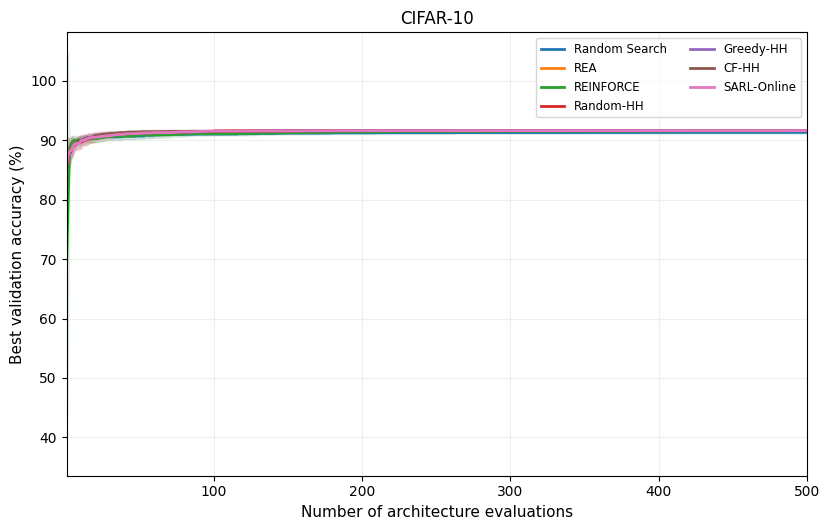

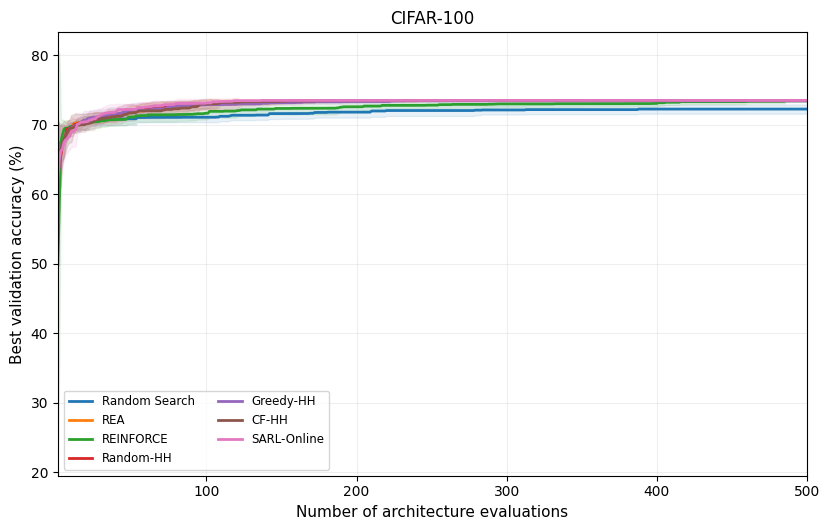

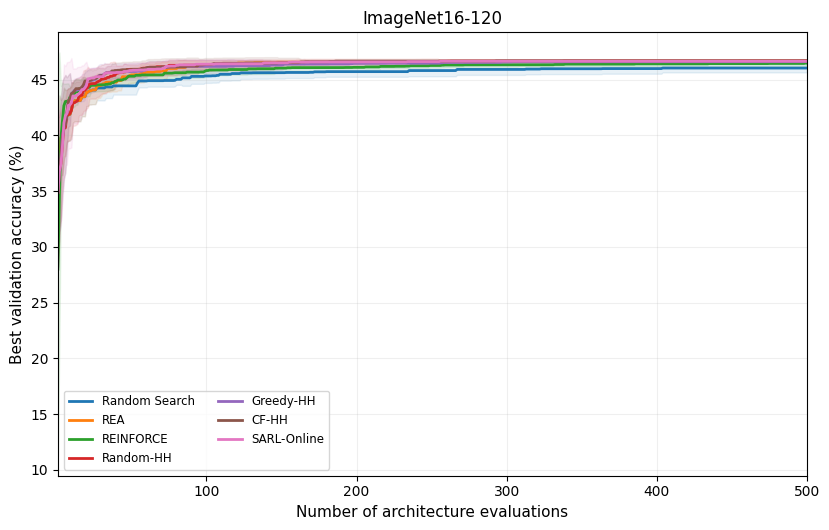

Figures saved in:
/content/drive/MyDrive/SARL_HHNAS/results/final/convergence/figures


In [ ]:
%cd /content/drive/MyDrive/SARL_HHNAS

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path


# ============================================================
# PATHS
# ============================================================

ROOT = Path(
    "/content/drive/MyDrive/SARL_HHNAS/"
    "results/final/convergence"
)

RAW = ROOT / "convergence_raw.csv"

FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# LOAD
# ============================================================

df = pd.read_csv(RAW)

print("Rows:", len(df))
print("Datasets:", df["dataset"].unique())
print("Methods:", df["method"].unique())
print("Seeds:", sorted(df["seed"].unique()))


# ============================================================
# DISPLAY NAMES
# ============================================================

METHOD_NAMES = {
    "random": "Random Search",
    "rea": "REA",
    "reinforce": "REINFORCE",
    "random-hh": "Random-HH",
    "greedy-hh": "Greedy-HH",
    "cf-hh": "CF-HH",
    "sarl": "SARL-Online"
}

DATASET_NAMES = {
    "cifar10": "CIFAR-10",
    "cifar100": "CIFAR-100",
    "ImageNet16-120": "ImageNet16-120"
}


# ============================================================
# IMPORTANT:
# Reindex every seed to evaluations 1..500 and forward-fill
# the incumbent best value.
# ============================================================

all_curves = []

for (
    dataset,
    method,
    seed
), g in df.groupby(
    ["dataset", "method", "seed"]
):

    g = (
        g[["evaluation", "best_val"]]
        .drop_duplicates(
            "evaluation",
            keep="last"
        )
        .sort_values("evaluation")
        .set_index("evaluation")
    )

    full_index = pd.Index(
        range(1, 501),
        name="evaluation"
    )

    g = g.reindex(full_index)

    # best-so-far remains valid until next recorded point
    g["best_val"] = (
        g["best_val"]
        .ffill()
        .bfill()
    )

    g = g.reset_index()

    g["dataset"] = dataset
    g["method"] = method
    g["seed"] = seed

    all_curves.append(g)


curve_df = pd.concat(
    all_curves,
    ignore_index=True
)


# ============================================================
# MEAN + SD
# ============================================================

summary = (
    curve_df
    .groupby(
        [
            "dataset",
            "method",
            "evaluation"
        ]
    )["best_val"]
    .agg(
        mean="mean",
        std="std",
        n="count"
    )
    .reset_index()
)

summary.to_csv(
    ROOT / "convergence_summary.csv",
    index=False
)


# ============================================================
# DRAW ONE FIGURE PER DATASET
# ============================================================

method_order = [
    "random",
    "rea",
    "reinforce",
    "random-hh",
    "greedy-hh",
    "cf-hh",
    "sarl"
]


for dataset in [
    "cifar10",
    "cifar100",
    "ImageNet16-120"
]:

    fig, ax = plt.subplots(
        figsize=(8.4, 5.4)
    )

    for method in method_order:

        x = summary[
            (summary["dataset"] == dataset)
            &
            (summary["method"] == method)
        ].sort_values("evaluation")

        if x.empty:
            continue

        ev = x["evaluation"].to_numpy()
        mean = x["mean"].to_numpy()
        std = x["std"].fillna(0).to_numpy()

        line, = ax.plot(
            ev,
            mean,
            linewidth=2.0,
            label=METHOD_NAMES[method]
        )

        ax.fill_between(
            ev,
            mean - std,
            mean + std,
            alpha=0.10,
            color=line.get_color()
        )

    ax.set_xlabel(
        "Number of architecture evaluations",
        fontsize=11
    )

    ax.set_ylabel(
        "Best validation accuracy (%)",
        fontsize=11
    )

    ax.set_title(
        DATASET_NAMES[dataset],
        fontsize=12
    )

    ax.set_xlim(
        1,
        500
    )

    ax.grid(
        True,
        alpha=0.20
    )

    ax.legend(
        fontsize=8.5,
        ncol=2,
        frameon=True
    )

    fig.tight_layout()

    stem = (
        "convergence_"
        + dataset
        .replace("-", "_")
        .lower()
    )

    fig.savefig(
        FIG_DIR / f"{stem}.png",
        dpi=600,
        bbox_inches="tight"
    )

    fig.savefig(
        FIG_DIR / f"{stem}.pdf",
        bbox_inches="tight"
    )

    plt.show()

    plt.close(fig)


print("Figures saved in:")
print(FIG_DIR)

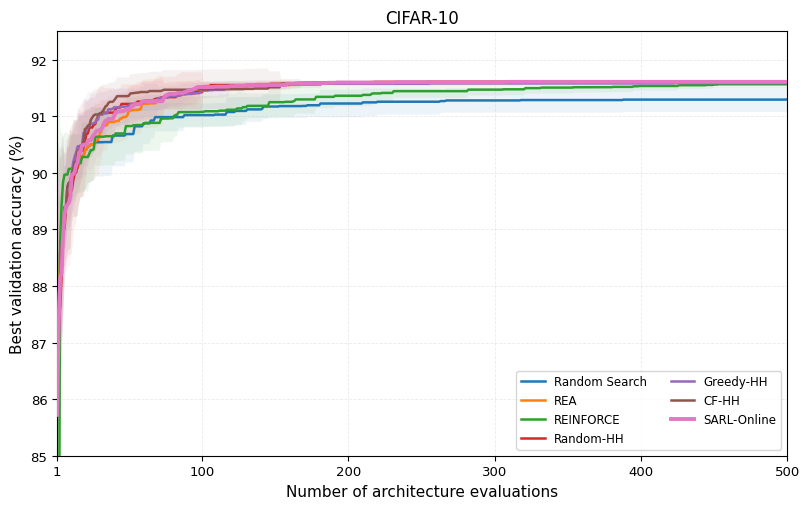

Saved: /content/drive/MyDrive/SARL_HHNAS/results/final/convergence/figures_final/convergence_cifar10.png
Saved: /content/drive/MyDrive/SARL_HHNAS/results/final/convergence/figures_final/convergence_cifar10.pdf


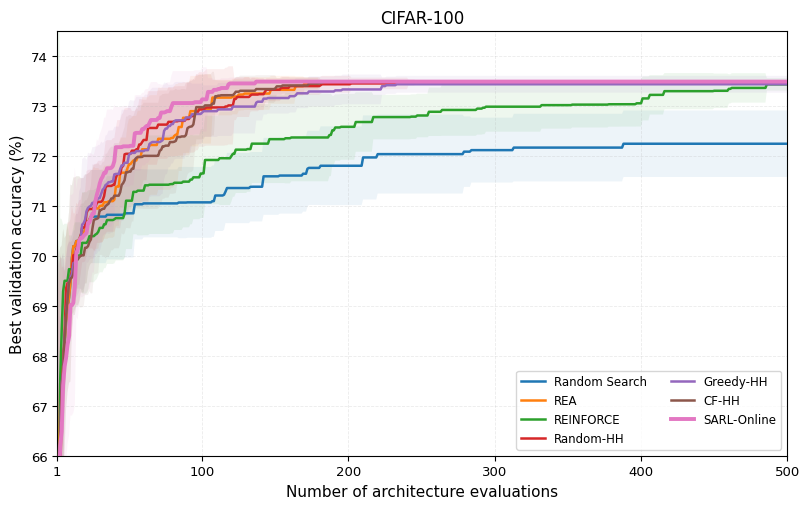

Saved: /content/drive/MyDrive/SARL_HHNAS/results/final/convergence/figures_final/convergence_cifar100.png
Saved: /content/drive/MyDrive/SARL_HHNAS/results/final/convergence/figures_final/convergence_cifar100.pdf


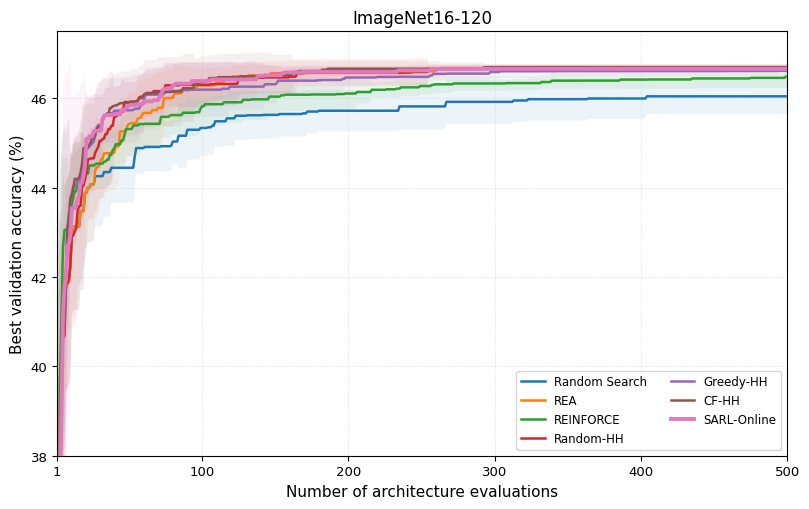

Saved: /content/drive/MyDrive/SARL_HHNAS/results/final/convergence/figures_final/convergence_imagenet16_120.png
Saved: /content/drive/MyDrive/SARL_HHNAS/results/final/convergence/figures_final/convergence_imagenet16_120.pdf


In [ ]:
# ============================================================
# PUBLICATION-QUALITY CONVERGENCE FIGURES
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path(
    "/content/drive/MyDrive/SARL_HHNAS/"
    "results/final/convergence"
)

SUMMARY = ROOT / "convergence_summary.csv"
FIG_DIR = ROOT / "figures_final"
FIG_DIR.mkdir(parents=True, exist_ok=True)

summary = pd.read_csv(SUMMARY)

METHOD_NAMES = {
    "random": "Random Search",
    "rea": "REA",
    "reinforce": "REINFORCE",
    "random-hh": "Random-HH",
    "greedy-hh": "Greedy-HH",
    "cf-hh": "CF-HH",
    "sarl": "SARL-Online"
}

METHOD_ORDER = [
    "random",
    "rea",
    "reinforce",
    "random-hh",
    "greedy-hh",
    "cf-hh",
    "sarl"
]

DATASETS = {
    "cifar10": {
        "title": "CIFAR-10",
        "ylim": (85, 92.5)
    },
    "cifar100": {
        "title": "CIFAR-100",
        "ylim": (66, 74.5)
    },
    "ImageNet16-120": {
        "title": "ImageNet16-120",
        "ylim": (38, 47.5)
    }
}


for dataset, settings in DATASETS.items():

    data = summary[
        summary["dataset"] == dataset
    ].copy()

    if data.empty:
        print("NO DATA:", dataset)
        continue

    fig, ax = plt.subplots(figsize=(8.2, 5.2))

    for method in METHOD_ORDER:

        x = data[
            data["method"] == method
        ].sort_values("evaluation")

        if x.empty:
            print(
                "Missing:",
                dataset,
                method
            )
            continue

        evaluation = x["evaluation"].to_numpy()
        mean = x["mean"].to_numpy()
        std = x["std"].fillna(0).to_numpy()

        # Prevent uncertainty interval exceeding valid accuracy range
        lower = np.clip(mean - std, 0, 100)
        upper = np.clip(mean + std, 0, 100)

        # Slightly emphasize proposed method
        linewidth = 2.8 if method == "sarl" else 1.8
        zorder = 10 if method == "sarl" else 3

        line, = ax.plot(
            evaluation,
            mean,
            linewidth=linewidth,
            label=METHOD_NAMES[method],
            zorder=zorder
        )

        ax.fill_between(
            evaluation,
            lower,
            upper,
            alpha=0.08,
            color=line.get_color(),
            linewidth=0
        )

    ax.set_xlim(1, 500)
    ax.set_ylim(*settings["ylim"])

    ax.set_xticks(
        [1, 100, 200, 300, 400, 500]
    )

    ax.set_xlabel(
        "Number of architecture evaluations",
        fontsize=11
    )

    ax.set_ylabel(
        "Best validation accuracy (%)",
        fontsize=11
    )

    ax.set_title(
        settings["title"],
        fontsize=12
    )

    ax.grid(
        True,
        linestyle="--",
        linewidth=0.6,
        alpha=0.25
    )

    ax.legend(
        loc="lower right",
        ncol=2,
        fontsize=8.5,
        frameon=True
    )

    ax.tick_params(
        axis="both",
        labelsize=9.5
    )

    fig.tight_layout()

    safe_name = (
        dataset
        .replace("-", "_")
        .lower()
    )

    png = FIG_DIR / f"convergence_{safe_name}.png"
    pdf = FIG_DIR / f"convergence_{safe_name}.pdf"

    fig.savefig(
        png,
        dpi=600,
        bbox_inches="tight"
    )

    fig.savefig(
        pdf,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print("Saved:", png)
    print("Saved:", pdf)

In [ ]:
%cd /content/drive/MyDrive/SARL_HHNAS

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/SARL_HHNAS")

MAIN = ROOT / "results/final/raw/main_results.csv"
RQ2  = ROOT / "results/final/raw/rq2_state_ablation.csv"
RQ3  = ROOT / "results/final/raw/rq3_cost_aware.csv"

META_DIR = ROOT / "results/final/logs"

FIG_DIR = ROOT / "results/final/figures_publication"
FIG_DIR.mkdir(parents=True, exist_ok=True)

main = pd.read_csv(MAIN)
rq2 = pd.read_csv(RQ2)
rq3 = pd.read_csv(RQ3)

print("Main:", main.shape)
print("RQ2 :", rq2.shape)
print("RQ3 :", rq3.shape)

print("\nMain columns:")
print(main.columns.tolist())

print("\nFigures will be saved to:")
print(FIG_DIR)

/content
Main: (1170, 18)
RQ2 : (80, 12)
RQ3 : (120, 13)

Main columns:
['dataset', 'budget', 'search_seed', 'method', 'source_dataset', 'policy_seed', 'meta_queries', 'search_queries', 'test_queries', 'search_time_sec', 'best_val_acc', 'test_acc', 'search_auc', 'params', 'flops', 'final_regret', 'evaluations_to_target', 'target_reached']

Figures will be saved to:
/content/drive/MyDrive/SARL_HHNAS/results/final/figures_publication


Missing: cifar10 sarl


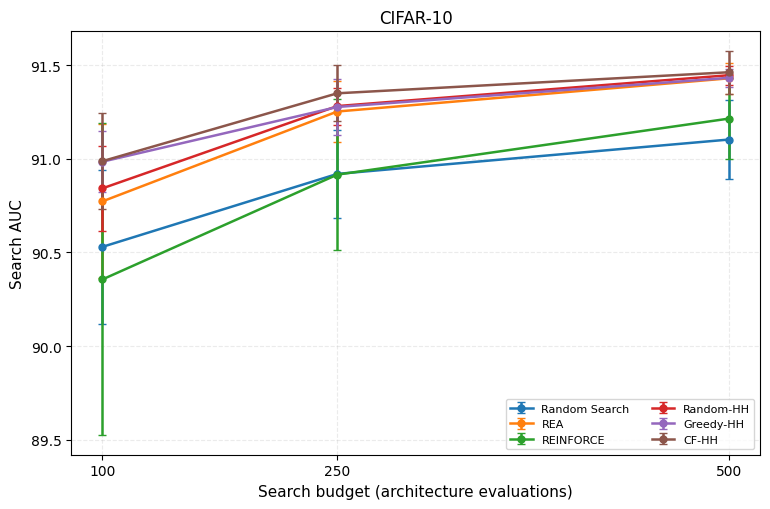

Missing: cifar100 sarl


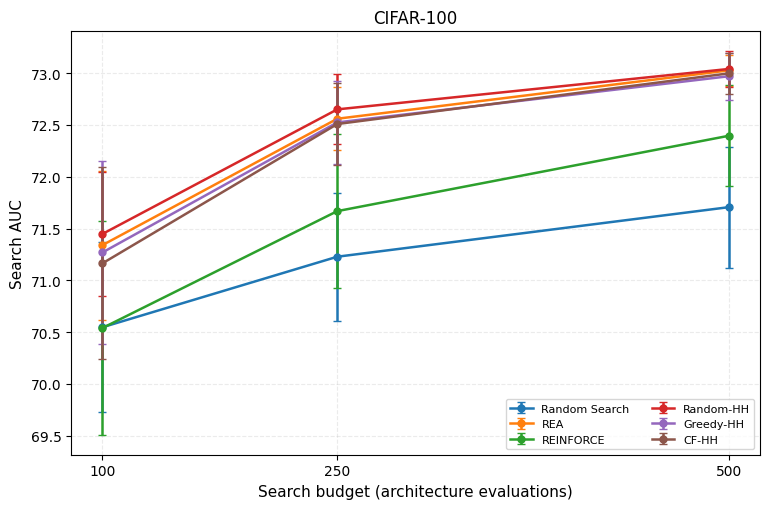

Missing: ImageNet16-120 sarl


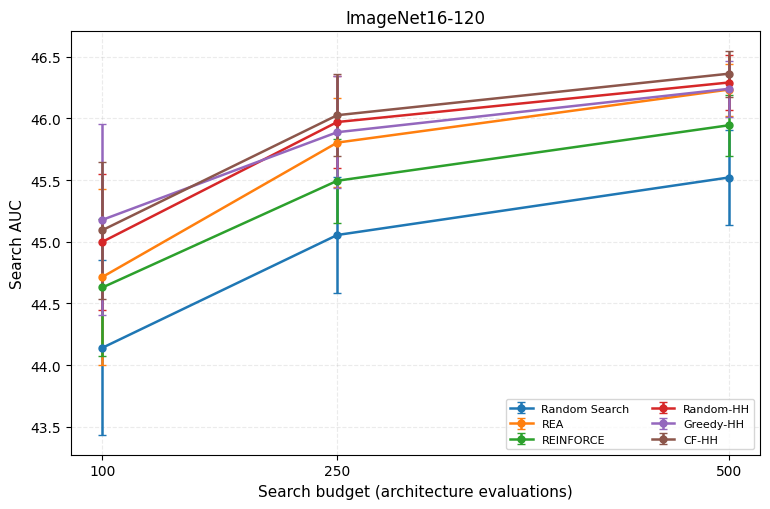

In [ ]:
METHOD_NAMES = {
    "random": "Random Search",
    "rea": "REA",
    "reinforce": "REINFORCE",
    "random-hh": "Random-HH",
    "greedy-hh": "Greedy-HH",
    "cf-hh": "CF-HH",
    "sarl": "SARL-Online",
    "sarl-online": "SARL-Online",
}

METHOD_ORDER = [
    "random",
    "rea",
    "reinforce",
    "random-hh",
    "greedy-hh",
    "cf-hh",
    "sarl"
]

DATASET_NAMES = {
    "cifar10": "CIFAR-10",
    "cifar100": "CIFAR-100",
    "ImageNet16-120": "ImageNet16-120"
}


# Handle possible naming difference
if "search_auc" not in main.columns:
    raise ValueError(
        "main_results.csv does not contain search_auc."
    )


for dataset, title in DATASET_NAMES.items():

    d = main[
        (main["dataset"] == dataset) &
        (main["method"].isin(METHOD_ORDER))
    ].copy()

    summary_auc = (
        d.groupby(["method", "budget"])["search_auc"]
        .agg(["mean", "std"])
        .reset_index()
    )

    fig, ax = plt.subplots(figsize=(7.8, 5.2))

    for method in METHOD_ORDER:

        x = summary_auc[
            summary_auc["method"] == method
        ].sort_values("budget")

        if x.empty:
            print("Missing:", dataset, method)
            continue

        lw = 2.8 if method == "sarl" else 1.8

        ax.errorbar(
            x["budget"],
            x["mean"],
            yerr=x["std"],
            marker="o",
            markersize=5,
            linewidth=lw,
            capsize=3,
            label=METHOD_NAMES[method]
        )

    ax.set_xlabel(
        "Search budget (architecture evaluations)",
        fontsize=11
    )

    ax.set_ylabel(
        "Search AUC",
        fontsize=11
    )

    ax.set_xticks([100, 250, 500])

    ax.set_title(
        title,
        fontsize=12
    )

    ax.grid(
        True,
        linestyle="--",
        alpha=0.25
    )

    ax.legend(
        fontsize=8,
        ncol=2,
        frameon=True
    )

    fig.tight_layout()

    stem = (
        "fig_search_auc_budget_"
        + dataset.replace("-", "_").lower()
    )

    fig.savefig(
        FIG_DIR / f"{stem}.png",
        dpi=600,
        bbox_inches="tight"
    )

    fig.savefig(
        FIG_DIR / f"{stem}.pdf",
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

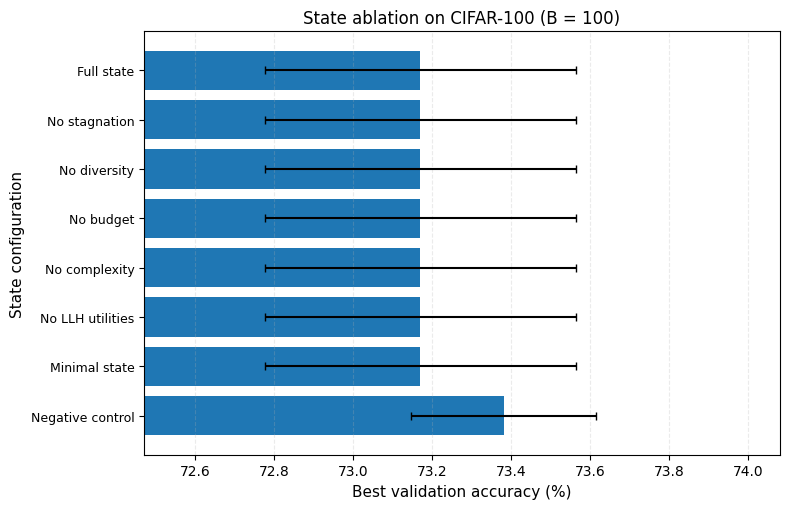

In [ ]:
RQ2_NAMES = {
    "full": "Full state",
    "no-stagnation": "No stagnation",
    "no-diversity": "No diversity",
    "no-budget": "No budget",
    "no-complexity": "No complexity",
    "no-llh-utilities": "No LLH utilities",
    "minimal": "Minimal state",
    "state-negative-control": "Negative control"
}

RQ2_ORDER = [
    "full",
    "no-stagnation",
    "no-diversity",
    "no-budget",
    "no-complexity",
    "no-llh-utilities",
    "minimal",
    "state-negative-control"
]


summary_rq2 = (
    rq2.groupby("variant")
       .agg(
           mean=("best_val_acc", "mean"),
           std=("best_val_acc", "std")
       )
       .reindex(RQ2_ORDER)
       .reset_index()
)

summary_rq2["label"] = (
    summary_rq2["variant"].map(RQ2_NAMES)
)


fig, ax = plt.subplots(figsize=(8.0, 5.2))

y = np.arange(len(summary_rq2))

ax.barh(
    y,
    summary_rq2["mean"],
    xerr=summary_rq2["std"],
    capsize=3
)

ax.set_yticks(y)
ax.set_yticklabels(
    summary_rq2["label"],
    fontsize=9
)

ax.invert_yaxis()

ax.set_xlabel(
    "Best validation accuracy (%)",
    fontsize=11
)

ax.set_ylabel(
    "State configuration",
    fontsize=11
)

ax.set_title(
    "State ablation on CIFAR-100 (B = 100)",
    fontsize=12
)

# Zoom to meaningful range
xmin = summary_rq2["mean"].min() - 0.7
xmax = summary_rq2["mean"].max() + 0.7

ax.set_xlim(xmin, xmax)

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.25
)

fig.tight_layout()

fig.savefig(
    FIG_DIR / "fig_state_ablation.png",
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    FIG_DIR / "fig_state_ablation.pdf",
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

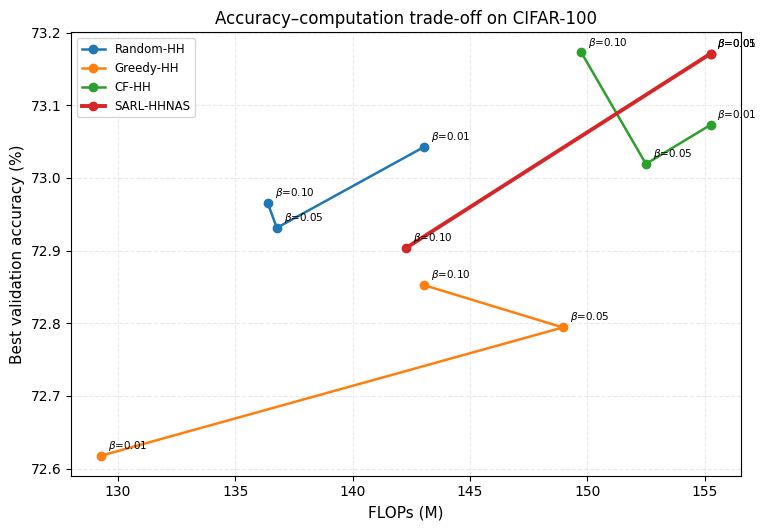

In [ ]:
RQ3_METHOD_NAMES = {
    "random-hh": "Random-HH",
    "greedy-hh": "Greedy-HH",
    "cf-hh": "CF-HH",
    "sarl": "SARL-HHNAS"
}


rq3_mean = (
    rq3.groupby(["method", "beta"])
       .agg(
           val_mean=("best_val_acc", "mean"),
           val_std=("best_val_acc", "std"),
           flops_mean=("flops", "mean"),
           flops_std=("flops", "std"),
           params_mean=("params", "mean"),
           params_std=("params", "std")
       )
       .reset_index()
)


fig, ax = plt.subplots(figsize=(7.8, 5.4))

for method in [
    "random-hh",
    "greedy-hh",
    "cf-hh",
    "sarl"
]:

    x = rq3_mean[
        rq3_mean["method"] == method
    ].sort_values("beta")

    if x.empty:
        continue

    lw = 2.8 if method == "sarl" else 1.8

    line, = ax.plot(
        x["flops_mean"],
        x["val_mean"],
        marker="o",
        markersize=6,
        linewidth=lw,
        label=RQ3_METHOD_NAMES[method]
    )

    # Label beta values
    for _, row in x.iterrows():

        ax.annotate(
            rf"$\beta$={row['beta']:.2f}",
            (
                row["flops_mean"],
                row["val_mean"]
            ),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=7.5
        )


ax.set_xlabel(
    "FLOPs (M)",
    fontsize=11
)

ax.set_ylabel(
    "Best validation accuracy (%)",
    fontsize=11
)

ax.set_title(
    "Accuracy–computation trade-off on CIFAR-100",
    fontsize=12
)

ax.grid(
    True,
    linestyle="--",
    alpha=0.25
)

ax.legend(
    fontsize=8.5,
    frameon=True
)

fig.tight_layout()

fig.savefig(
    FIG_DIR / "fig_accuracy_flops_tradeoff.png",
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    FIG_DIR / "fig_accuracy_flops_tradeoff.pdf",
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

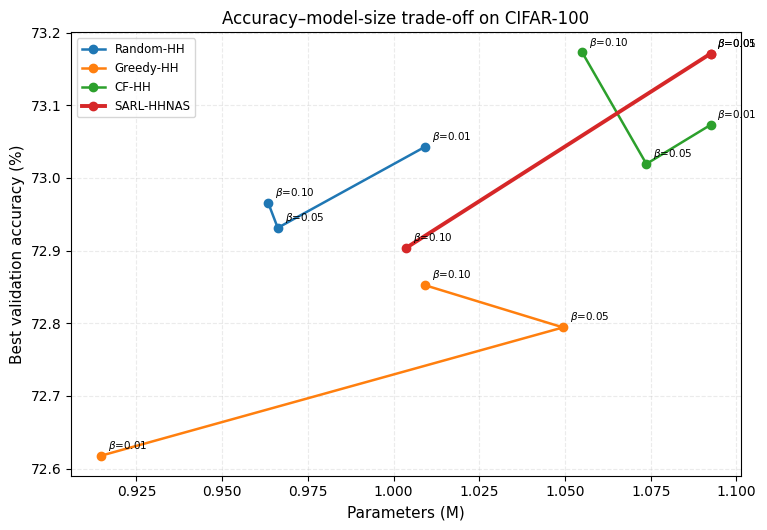

In [ ]:
fig, ax = plt.subplots(figsize=(7.8, 5.4))

for method in [
    "random-hh",
    "greedy-hh",
    "cf-hh",
    "sarl"
]:

    x = rq3_mean[
        rq3_mean["method"] == method
    ].sort_values("beta")

    if x.empty:
        continue

    lw = 2.8 if method == "sarl" else 1.8

    ax.plot(
        x["params_mean"],
        x["val_mean"],
        marker="o",
        markersize=6,
        linewidth=lw,
        label=RQ3_METHOD_NAMES[method]
    )

    for _, row in x.iterrows():

        ax.annotate(
            rf"$\beta$={row['beta']:.2f}",
            (
                row["params_mean"],
                row["val_mean"]
            ),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=7.5
        )


ax.set_xlabel(
    "Parameters (M)",
    fontsize=11
)

ax.set_ylabel(
    "Best validation accuracy (%)",
    fontsize=11
)

ax.set_title(
    "Accuracy–model-size trade-off on CIFAR-100",
    fontsize=12
)

ax.grid(
    True,
    linestyle="--",
    alpha=0.25
)

ax.legend(
    fontsize=8.5,
    frameon=True
)

fig.tight_layout()

fig.savefig(
    FIG_DIR / "fig_accuracy_params_tradeoff.png",
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    FIG_DIR / "fig_accuracy_params_tradeoff.pdf",
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

In [ ]:
print("Available SARL-related methods:")

print(
    sorted([
        x for x in main["method"].unique()
        if "sarl" in str(x).lower()
    ])
)

Available SARL-related methods:
['sarl-meta-finetune', 'sarl-meta-frozen', 'sarl-online']


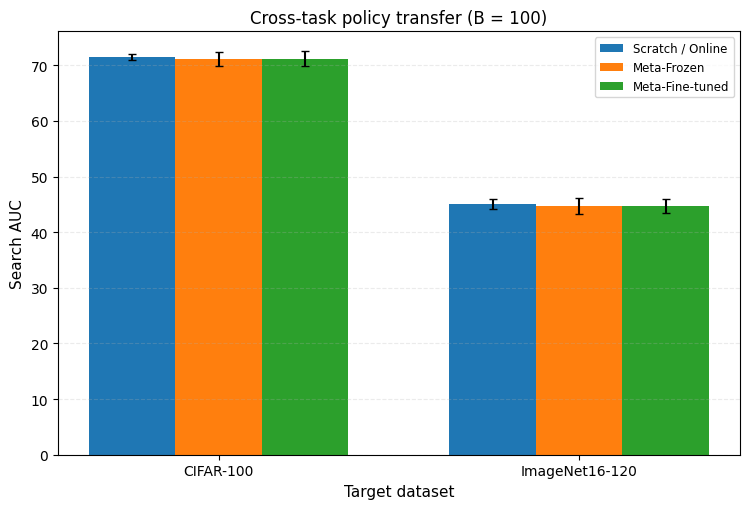

In [ ]:
# Detect scratch label
if "sarl-online" in main["method"].unique():
    scratch_name = "sarl-online"
elif "sarl" in main["method"].unique():
    scratch_name = "sarl"
else:
    raise ValueError("Cannot find SARL scratch/online results.")


TRANSFER_NAMES = {
    scratch_name: "Scratch / Online",
    "sarl-meta-frozen": "Meta-Frozen",
    "sarl-meta-finetune": "Meta-Fine-tuned"
}

transfer_methods = list(TRANSFER_NAMES.keys())


# Use B=100 to match current RQ5 table
transfer = main[
    (main["budget"] == 100) &
    (main["dataset"].isin([
        "cifar100",
        "ImageNet16-120"
    ])) &
    (main["method"].isin(transfer_methods))
].copy()


transfer_summary = (
    transfer.groupby(
        ["dataset", "method"]
    )["search_auc"]
    .agg(["mean", "std"])
    .reset_index()
)


datasets = [
    "cifar100",
    "ImageNet16-120"
]

x = np.arange(len(datasets))
width = 0.24

fig, ax = plt.subplots(figsize=(7.6, 5.2))


for i, method in enumerate(transfer_methods):

    means = []
    stds = []

    for dataset in datasets:

        r = transfer_summary[
            (transfer_summary["dataset"] == dataset) &
            (transfer_summary["method"] == method)
        ]

        if len(r):
            means.append(float(r["mean"].iloc[0]))
            stds.append(float(r["std"].iloc[0]))
        else:
            means.append(np.nan)
            stds.append(np.nan)

    offset = (
        i - (len(transfer_methods) - 1) / 2
    ) * width

    ax.bar(
        x + offset,
        means,
        width,
        yerr=stds,
        capsize=3,
        label=TRANSFER_NAMES[method]
    )


ax.set_xticks(x)

ax.set_xticklabels([
    "CIFAR-100",
    "ImageNet16-120"
])

ax.set_ylabel(
    "Search AUC",
    fontsize=11
)

ax.set_xlabel(
    "Target dataset",
    fontsize=11
)

ax.set_title(
    "Cross-task policy transfer (B = 100)",
    fontsize=12
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

ax.legend(
    fontsize=8.5,
    frameon=True
)

fig.tight_layout()

fig.savefig(
    FIG_DIR / "fig_policy_transfer.png",
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    FIG_DIR / "fig_policy_transfer.pdf",
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

Policy reuse and transfer summary (B = 100):


,dataset,method,mean,std,n_runs
0,ImageNet16-120,sarl-meta-finetune,44.677863,1.243661,30
1,ImageNet16-120,sarl-meta-frozen,44.659770,1.407920,30
2,ImageNet16-120,sarl-online,45.068583,0.841046,10
3,cifar10,sarl-meta-finetune,90.828147,0.490836,30
4,cifar10,sarl-meta-frozen,90.674202,0.511803,30
5,cifar10,sarl-online,90.920213,0.343075,10
6,cifar100,sarl-meta-finetune,71.147773,1.327223,30
7,cifar100,sarl-meta-frozen,71.187580,1.268976,30
8,cifar100,sarl-online,71.508593,0.576943,10


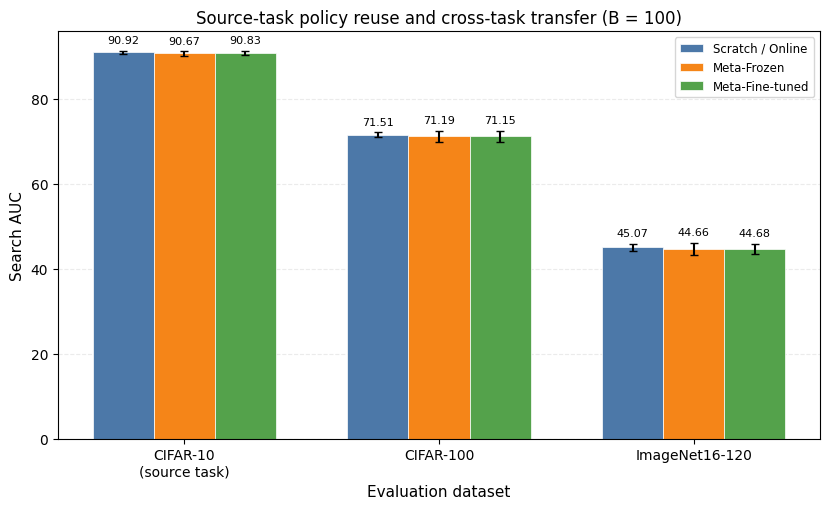

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Uses the existing main DataFrame and FIG_DIR.
FIG_DIR = Path(FIG_DIR)
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Detect the online configuration.
available_methods = main["method"].unique()

if "sarl-online" in available_methods:
    scratch_name = "sarl-online"
elif "sarl" in available_methods:
    scratch_name = "sarl"
else:
    raise ValueError("Cannot find SARL scratch/online results.")

TRANSFER_NAMES = {
    scratch_name: "Scratch / Online",
    "sarl-meta-frozen": "Meta-Frozen",
    "sarl-meta-finetune": "Meta-Fine-tuned"
}

transfer_methods = list(TRANSFER_NAMES)

datasets = [
    "cifar10",
    "cifar100",
    "ImageNet16-120"
]

dataset_labels = [
    "CIFAR-10\n(source task)",
    "CIFAR-100",
    "ImageNet16-120"
]

# Select results at B = 100.
transfer = main.loc[
    (main["budget"] == 100) &
    (main["dataset"].isin(datasets)) &
    (main["method"].isin(transfer_methods))
].copy()

transfer_summary = (
    transfer.groupby(["dataset", "method"])["search_auc"]
    .agg(mean="mean", std="std", n_runs="count")
    .reset_index()
)

# Check that every requested group is available.
for dataset in datasets:
    for method in transfer_methods:
        group = transfer_summary[
            (transfer_summary["dataset"] == dataset) &
            (transfer_summary["method"] == method)
        ]

        if group.empty:
            raise ValueError(
                f"Missing results: dataset={dataset}, "
                f"method={method}, budget=100"
            )

print("Policy reuse and transfer summary (B = 100):")
display(transfer_summary)

x = np.arange(len(datasets))
width = 0.24
colors = ["#4C78A8", "#F58518", "#54A24B"]

fig, ax = plt.subplots(figsize=(8.4, 5.2))

for i, method in enumerate(transfer_methods):

    rows = (
        transfer_summary[
            transfer_summary["method"] == method
        ]
        .set_index("dataset")
        .reindex(datasets)
    )

    means = rows["mean"].to_numpy()
    stds = rows["std"].fillna(0).to_numpy()

    offset = (
        i - (len(transfer_methods) - 1) / 2
    ) * width

    bars = ax.bar(
        x + offset,
        means,
        width=width,
        yerr=stds,
        capsize=3,
        color=colors[i],
        label=TRANSFER_NAMES[method],
        edgecolor="white",
        linewidth=0.5
    )

    ax.bar_label(
        bars,
        labels=[f"{value:.2f}" for value in means],
        padding=4,
        fontsize=8
    )

ax.set_xticks(x)
ax.set_xticklabels(dataset_labels, fontsize=10)

ax.set_ylabel("Search AUC", fontsize=11)
ax.set_xlabel("Evaluation dataset", fontsize=11)

ax.set_title(
    "Source-task policy reuse and cross-task transfer (B = 100)",
    fontsize=12
)

ax.set_axisbelow(True)
ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

ax.legend(
    fontsize=8.5,
    frameon=True
)

fig.tight_layout()

fig.savefig(
    FIG_DIR / "fig_policy_transfer.png",
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    FIG_DIR / "fig_policy_transfer.pdf",
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

In [ ]:
meta_files = sorted(
    META_DIR.glob("meta_curve_seed*.csv")
)

print("Files:", len(meta_files))

for p in meta_files:
    x = pd.read_csv(p)

    print("\n", p.name)
    print("shape:", x.shape)
    print("columns:", x.columns.tolist())
    display(x.head())

Files: 3

 meta_curve_seed1000.csv
shape: (100, 2)
columns: ['episode', 'best_val']


,episode,best_val
0,1,91.606667
1,2,91.360000
2,3,91.416000
3,4,91.606667
4,5,91.606667



 meta_curve_seed1001.csv
shape: (100, 2)
columns: ['episode', 'best_val']


,episode,best_val
0,1,91.366000
1,2,91.061333
2,3,91.606667
3,4,91.266000
4,5,91.516000



 meta_curve_seed1002.csv
shape: (100, 2)
columns: ['episode', 'best_val']


,episode,best_val
0,1,91.606667
1,2,91.606667
2,3,91.128000
3,4,91.296000
4,5,90.670667


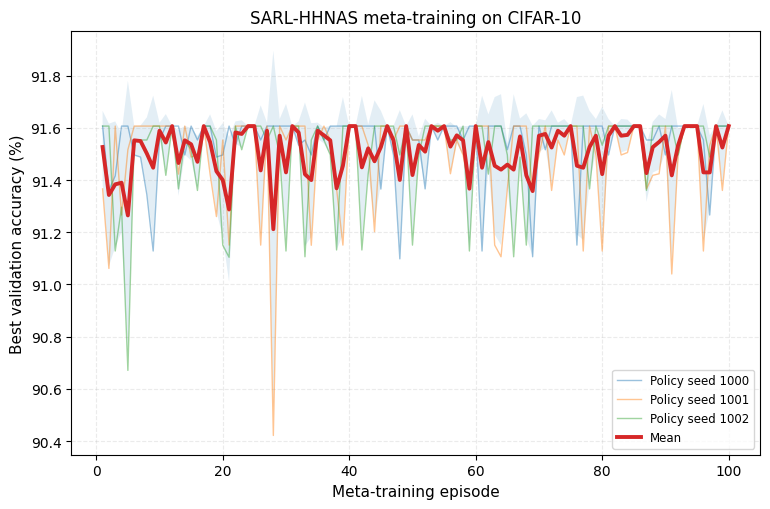

In [ ]:
meta_frames = []

for p in meta_files:

    x = pd.read_csv(p)

    # Detect episode column
    episode_candidates = [
        c for c in x.columns
        if c.lower() in [
            "episode",
            "episodes",
            "episode_id"
        ]
    ]

    if not episode_candidates:
        raise ValueError(
            f"No episode column found in {p.name}: "
            f"{x.columns.tolist()}"
        )

    episode_col = episode_candidates[0]

    # Detect validation-performance column
    metric_candidates = [
        c for c in x.columns
        if c.lower() in [
            "best_val",
            "best_val_acc",
            "validation_accuracy",
            "val_acc"
        ]
    ]

    if not metric_candidates:
        raise ValueError(
            f"No validation metric found in {p.name}: "
            f"{x.columns.tolist()}"
        )

    metric_col = metric_candidates[0]

    seed = int(
        p.stem
        .replace("meta_curve_seed", "")
    )

    temp = pd.DataFrame({
        "episode": x[episode_col],
        "value": x[metric_col],
        "policy_seed": seed
    })

    meta_frames.append(temp)


meta = pd.concat(
    meta_frames,
    ignore_index=True
)


meta_summary = (
    meta.groupby("episode")["value"]
        .agg(["mean", "std"])
        .reset_index()
)


fig, ax = plt.subplots(figsize=(7.8, 5.2))

for seed, x in meta.groupby("policy_seed"):

    x = x.sort_values("episode")

    ax.plot(
        x["episode"],
        x["value"],
        linewidth=1.0,
        alpha=0.45,
        label=f"Policy seed {seed}"
    )


x = meta_summary["episode"].to_numpy()
mean = meta_summary["mean"].to_numpy()
std = meta_summary["std"].fillna(0).to_numpy()

ax.plot(
    x,
    mean,
    linewidth=2.8,
    label="Mean"
)

ax.fill_between(
    x,
    mean - std,
    mean + std,
    alpha=0.12
)

ax.set_xlabel(
    "Meta-training episode",
    fontsize=11
)

ax.set_ylabel(
    "Best validation accuracy (%)",
    fontsize=11
)

ax.set_title(
    "SARL-HHNAS meta-training on CIFAR-10",
    fontsize=12
)

ax.grid(
    True,
    linestyle="--",
    alpha=0.25
)

ax.legend(
    fontsize=8.5
)

fig.tight_layout()

fig.savefig(
    FIG_DIR / "fig_meta_training.png",
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    FIG_DIR / "fig_meta_training.pdf",
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

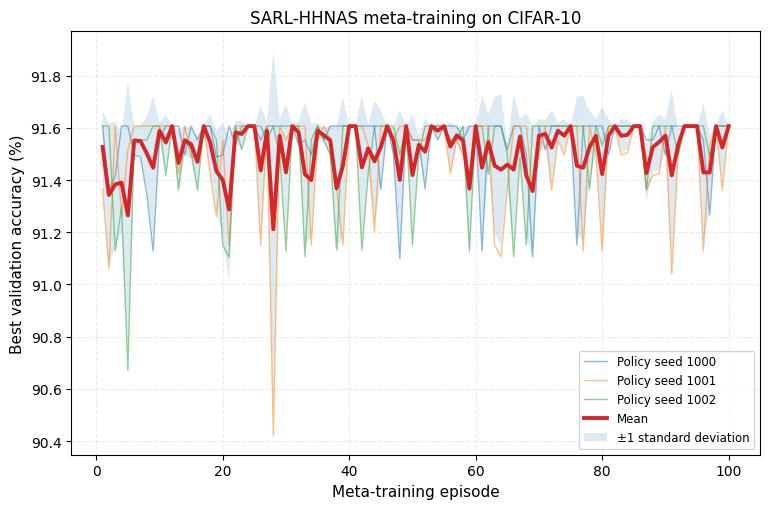

[SKIP] CIFAR-100: missing episode logs for policy seeds [1002].
[SKIP] ImageNet16-120: missing episode logs for policy seeds [1000, 1001, 1002].
Final recorded episode for each policy:


,dataset,episode,value,policy_seed
0,cifar10,100,91.606667,1000
1,cifar10,100,91.606667,1001
2,cifar10,100,91.606667,1002


In [ ]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_DIR = Path("/content/drive/MyDrive/SARL_HHNAS")
FIG_DIR = Path(FIG_DIR)
FIG_DIR.mkdir(parents=True, exist_ok=True)

POLICY_SEEDS = [1000, 1001, 1002]

# Keep the existing CIFAR-10 files.
# Update the other folders if their training logs are saved elsewhere.
META_FILES = {
    "cifar10": [Path(p) for p in meta_files],

    "cifar100": sorted(
        (
            PROJECT_DIR /
            "results/additional_meta_training/cifar100"
        ).glob("meta_curve_seed*.csv")
    ),

    "ImageNet16-120": sorted(
        (
            PROJECT_DIR /
            "results/additional_meta_training/ImageNet16-120"
        ).glob("meta_curve_seed*.csv")
    )
}

DATASET_NAMES = {
    "cifar10": "CIFAR-10",
    "cifar100": "CIFAR-100",
    "ImageNet16-120": "ImageNet16-120"
}

#COLORS = {
  #  1000: "#4C78A8",
 #   1001: "#F58518",
 #   1002: "#54A24B"
#}

all_meta_frames = []
all_summary_frames = []

for dataset, files in META_FILES.items():

    meta_frames = []
    found_seeds = set()

    for p in files:

        match = re.fullmatch(
            r"meta_curve_seed(\d+)",
            p.stem
        )

        if match is None:
            continue

        seed = int(match.group(1))

        if seed not in POLICY_SEEDS:
            continue

        if seed in found_seeds:
            raise ValueError(
                f"Duplicate policy seed {seed} for {dataset}."
            )

        data = pd.read_csv(p)

        columns = {
            str(c).strip().lower(): c
            for c in data.columns
        }

        episode_col = next(
            (
                columns[name]
                for name in [
                    "episode",
                    "episodes",
                    "episode_id"
                ]
                if name in columns
            ),
            None
        )

        metric_col = next(
            (
                columns[name]
                for name in [
                    "best_val",
                    "best_val_acc",
                    "validation_accuracy",
                    "val_acc"
                ]
                if name in columns
            ),
            None
        )

        if episode_col is None or metric_col is None:
            raise ValueError(
                f"Missing episode or validation column in {p}.\n"
                f"Available columns: {data.columns.tolist()}"
            )

        temp = pd.DataFrame({
            "dataset": dataset,
            "episode": pd.to_numeric(
                data[episode_col],
                errors="raise"
            ),
            "value": pd.to_numeric(
                data[metric_col],
                errors="raise"
            ),
            "policy_seed": seed
        })

        if temp.empty or temp.isna().any().any():
            raise ValueError(f"Empty or incomplete data in {p}.")

        if temp["episode"].duplicated().any():
            raise ValueError(f"Duplicate episodes in {p}.")

        meta_frames.append(temp)
        found_seeds.add(seed)

    missing_seeds = set(POLICY_SEEDS) - found_seeds

    if missing_seeds:
        print(
            f"[SKIP] {DATASET_NAMES[dataset]}: "
            f"missing episode logs for policy seeds "
            f"{sorted(missing_seeds)}."
        )
        continue

    meta = (
        pd.concat(meta_frames, ignore_index=True)
        .sort_values(["policy_seed", "episode"])
    )

    # Require matching episode numbers across the three policies.
    episode_sets = [
        set(group["episode"])
        for _, group in meta.groupby("policy_seed")
    ]

    if any(
        episodes != episode_sets[0]
        for episodes in episode_sets[1:]
    ):
        raise ValueError(
            f"Episode numbers differ across policy seeds "
            f"for {dataset}."
        )

    meta_summary = (
        meta.groupby("episode")["value"]
        .agg(mean="mean", std="std")
        .reset_index()
    )

    meta_summary.insert(0, "dataset", dataset)

    all_meta_frames.append(meta)
    all_summary_frames.append(meta_summary)

    fig, ax = plt.subplots(figsize=(7.8, 5.2))

    for seed, group in meta.groupby("policy_seed"):

        group = group.sort_values("episode")

        ax.plot(
            group["episode"],
            group["value"],
            #color=COLORS[seed],
            linewidth=1.0,
            alpha=0.5,
            label=f"Policy seed {seed}"
        )

    episodes = meta_summary["episode"].to_numpy()
    mean = meta_summary["mean"].to_numpy()
    std = meta_summary["std"].to_numpy()

    ax.plot(
        episodes,
        mean,
        #color="#222222",
        linewidth=2.8,
        label="Mean"
    )

    ax.fill_between(
        episodes,
        mean - std,
        mean + std,
        #color="#777777",
        alpha=0.15,
        label="±1 standard deviation"
    )

    ax.set_xlabel("Meta-training episode", fontsize=11)
    ax.set_ylabel("Best validation accuracy (%)", fontsize=11)

    ax.set_title(
        f"SARL-HHNAS meta-training on "
        f"{DATASET_NAMES[dataset]}",
        fontsize=12
    )

    ax.grid(
        True,
        linestyle="--",
        alpha=0.25
    )

    ax.legend(fontsize=8.5)
    fig.tight_layout()

    filename = f"fig_meta_training_{dataset.lower().replace('-', '_')}"

    fig.savefig(
        FIG_DIR / f"{filename}.png",
        dpi=600,
        bbox_inches="tight"
    )

    fig.savefig(
        FIG_DIR / f"{filename}.pdf",
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

# Save only datasets with all three policy logs.
if all_meta_frames:

    meta_all = pd.concat(
        all_meta_frames,
        ignore_index=True
    )

    meta_summary_all = pd.concat(
        all_summary_frames,
        ignore_index=True
    )

    meta_all.to_csv(
        FIG_DIR / "meta_training_all_datasets_raw.csv",
        index=False
    )

    meta_summary_all.to_csv(
        FIG_DIR / "meta_training_all_datasets_summary.csv",
        index=False
    )

    print("Final recorded episode for each policy:")

    final_episodes = (
        meta_all
        .sort_values("episode")
        .groupby(["dataset", "policy_seed"])
        .tail(1)
        .sort_values(["dataset", "policy_seed"])
    )

    display(final_episodes.reset_index(drop=True))

else:
    print("No dataset has all three required policy logs.")

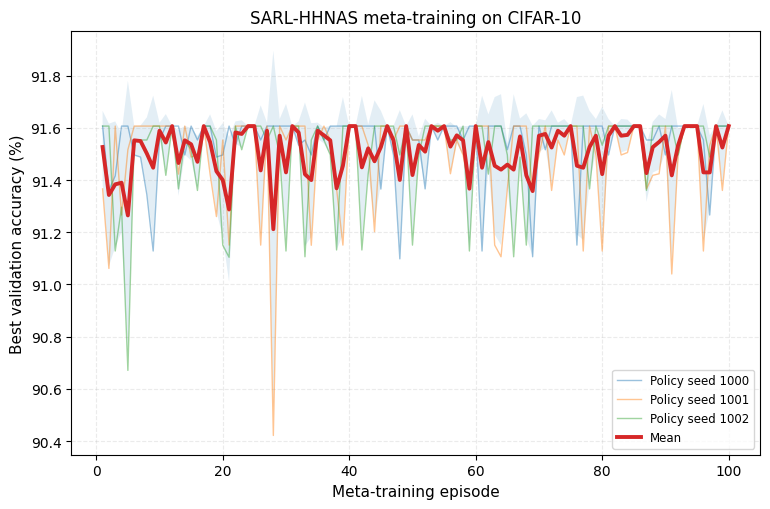

META-TRAINING RESULTS SAVED

Raw trajectories:
/content/drive/MyDrive/SARL_HHNAS/results/final/meta_training/meta_training_raw.csv

Episode summary:
/content/drive/MyDrive/SARL_HHNAS/results/final/meta_training/meta_training_summary.csv

Final episode summary:
/content/drive/MyDrive/SARL_HHNAS/results/final/meta_training/meta_training_final_episode.csv

Final episode = 100


,dataset,episode,value,policy_seed
99,cifar10,100,91.606667,1000
199,cifar10,100,91.606667,1001
299,cifar10,100,91.606667,1002



Final summary:


,episode,mean,std,minimum,maximum,n_policy_seeds
0,100,91.606667,0.0,91.606667,91.606667,3


In [ ]:
# ============================================================
# SAVE META-TRAINING NUMERICAL RESULTS
# ============================================================

META_RESULT_DIR = (
    ROOT / "results/final/meta_training"
)

META_RESULT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# 1. Save raw results:
#    episode | value | policy_seed
# ------------------------------------------------------------

raw_file = (
    META_RESULT_DIR /
    "meta_training_raw.csv"
)

meta.sort_values(
    ["policy_seed", "episode"]
).to_csv(
    raw_file,
    index=False
)


# ------------------------------------------------------------
# 2. Save summary:
#    episode | mean | std | min | max | n
# ------------------------------------------------------------

meta_summary_full = (
    meta.groupby("episode")["value"]
        .agg(
            mean="mean",
            std="std",
            minimum="min",
            maximum="max",
            n="count"
        )
        .reset_index()
)

summary_file = (
    META_RESULT_DIR /
    "meta_training_summary.csv"
)

meta_summary_full.to_csv(
    summary_file,
    index=False
)


# ------------------------------------------------------------
# 3. Save final episode results separately
# ------------------------------------------------------------

last_episode = meta["episode"].max()

final_values = (
    meta[
        meta["episode"] == last_episode
    ]
    .sort_values("policy_seed")
)

final_summary = pd.DataFrame([{
    "episode": last_episode,
    "mean": final_values["value"].mean(),
    "std": final_values["value"].std(),
    "minimum": final_values["value"].min(),
    "maximum": final_values["value"].max(),
    "n_policy_seeds": len(final_values)
}])

final_file = (
    META_RESULT_DIR /
    "meta_training_final_episode.csv"
)

final_summary.to_csv(
    final_file,
    index=False
)


# ============================================================
# PLOT
# ============================================================

fig, ax = plt.subplots(
    figsize=(7.8, 5.2)
)

for seed, d in meta.groupby("policy_seed"):

    d = d.sort_values("episode")

    ax.plot(
        d["episode"],
        d["value"],
        linewidth=1.0,
        alpha=0.45,
        label=f"Policy seed {seed}"
    )


x_plot = meta_summary_full[
    "episode"
].to_numpy()

mean_plot = meta_summary_full[
    "mean"
].to_numpy()

std_plot = (
    meta_summary_full["std"]
    .fillna(0)
    .to_numpy()
)


ax.plot(
    x_plot,
    mean_plot,
    linewidth=2.8,
    label="Mean"
)

ax.fill_between(
    x_plot,
    mean_plot - std_plot,
    mean_plot + std_plot,
    alpha=0.12
)


ax.set_xlabel(
    "Meta-training episode",
    fontsize=11
)

ax.set_ylabel(
    "Best validation accuracy (%)",
    fontsize=11
)

ax.set_title(
    "SARL-HHNAS meta-training on CIFAR-10",
    fontsize=12
)

ax.grid(
    True,
    linestyle="--",
    alpha=0.25
)

ax.legend(
    fontsize=8.5
)

fig.tight_layout()


# ------------------------------------------------------------
# Save publication figures
# ------------------------------------------------------------

fig.savefig(
    FIG_DIR / "fig_meta_training.png",
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    FIG_DIR / "fig_meta_training.pdf",
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ============================================================
# PRINT SAVED RESULTS
# ============================================================

print("=" * 70)
print("META-TRAINING RESULTS SAVED")
print("=" * 70)

print("\nRaw trajectories:")
print(raw_file)

print("\nEpisode summary:")
print(summary_file)

print("\nFinal episode summary:")
print(final_file)

print("\nFinal episode =", last_episode)

display(final_values)

print("\nFinal summary:")
display(final_summary)

In [ ]:
CONV = (
    ROOT /
    "results/final/convergence/convergence_raw.csv"
)

conv = pd.read_csv(CONV)

print("Convergence columns:")
print(conv.columns.tolist())

possible = [
    c for c in conv.columns
    if any(
        k in c.lower()
        for k in ["llh", "action", "heuristic"]
    )
]

print("\nPossible LLH/action columns:")
print(possible)

Convergence columns:
['dataset', 'method', 'seed', 'budget', 'evaluation', 'best_val']

Possible LLH/action columns:
[]


In [ ]:
%cd /content/drive/MyDrive/SARL_HHNAS

from pathlib import Path

code = r'''
import time
import pandas as pd
from copy import deepcopy
from pathlib import Path

from config import Config
from benchmark.nats import NATSBenchTSS
from search.sarl import SARLHHNAS


PROJECT = Path("/content/drive/MyDrive/SARL_HHNAS")

NATS_PATH = (
    "/content/drive/MyDrive/NATS_Bench/"
    "TSS_FAST/NATS-tss-v1_0-3ffb9-simple"
)

OUT = PROJECT / "results/final/llh_behavior"
OUT.mkdir(parents=True, exist_ok=True)

RAW = OUT / "sarl_llh_behavior.csv"

DATASETS = [
    "cifar10",
    "cifar100",
    "ImageNet16-120"
]

SEEDS = range(10)
BUDGET = 500


# ============================================================
# Benchmark
# ============================================================

print("Loading NATS-Bench...")

bench = NATSBenchTSS(
    NATS_PATH,
    hp="200",
    fast_mode=True,
    verbose=False,
    trial_seed=False
)

print("NATS-Bench loaded.")


# ============================================================
# Resume
# ============================================================

def completed_runs():

    if not RAW.exists():
        return set()

    df = pd.read_csv(RAW)

    if df.empty:
        return set()

    # A complete SARL trajectory should reach BUDGET.
    last = (
        df.groupby(["dataset", "seed"])["evaluation"]
          .max()
    )

    return {
        (str(ds), int(seed))
        for (ds, seed), ev in last.items()
        if int(ev) >= BUDGET
    }


done = completed_runs()

print("Completed runs:", len(done), "/ 30")


# ============================================================
# Run SARL
# ============================================================

base_cfg = Config(
    budget=BUDGET,
    beta=0.0,
    params_scale=10.0,
    flops_scale=10.0,
    warmup=64,
    batch_size=64
)


for dataset in DATASETS:

    for seed in SEEDS:

        key = (dataset, seed)

        if key in done:
            print("[SKIP]", dataset, seed)
            continue

        cfg = deepcopy(base_cfg)

        cfg.dataset = dataset
        cfg.seed = seed

        model = SARLHHNAS(
            bench,
            cfg
        )

        start = time.perf_counter()

        result = model.run(
            training=True
        )

        elapsed = time.perf_counter() - start

        records = []

        for row in result["rows"]:

            # INIT has no selected LLH.
            if row.get("llh") == "INIT":
                continue

            records.append({
                "dataset": dataset,
                "seed": seed,
                "budget": BUDGET,
                "evaluation": int(row["evaluation"]),
                "llh": row.get("llh"),
                "best_val": float(row["best_val"]),
                "current_val": float(row["current_val"])
            })

        run_df = pd.DataFrame(records)

        if run_df.empty:
            raise RuntimeError(
                f"No LLH records found for {dataset}, seed={seed}. "
                "Inspect result['rows'] before continuing."
            )

        # Append one completed run.
        run_df.to_csv(
            RAW,
            mode="a",
            header=not RAW.exists(),
            index=False
        )

        done.add(key)

        print(
            f"[{len(done)}/30]",
            dataset,
            f"seed={seed}",
            f"best={result['best_val_acc']:.4f}",
            f"time={elapsed:.2f}s"
        )


print()
print("=" * 70)
print("LLH BEHAVIOR EXPERIMENT COMPLETED")
print("=" * 70)
print(RAW)
'''

Path("run_llh_behavior.py").write_text(
    code,
    encoding="utf-8"
)

!python -m py_compile run_llh_behavior.py

print("✓ run_llh_behavior.py created")
print("✓ Syntax OK")

/content
✓ run_llh_behavior.py created
✓ Syntax OK


In [ ]:
%cd /content/drive/MyDrive/SARL_HHNAS

!python run_llh_behavior.py

/content
Loading NATS-Bench...
NATS-Bench loaded.
Completed runs: 30 / 30
[SKIP] cifar10 0
[SKIP] cifar10 1
[SKIP] cifar10 2
[SKIP] cifar10 3
[SKIP] cifar10 4
[SKIP] cifar10 5
[SKIP] cifar10 6
[SKIP] cifar10 7
[SKIP] cifar10 8
[SKIP] cifar10 9
[SKIP] cifar100 0
[SKIP] cifar100 1
[SKIP] cifar100 2
[SKIP] cifar100 3
[SKIP] cifar100 4
[SKIP] cifar100 5
[SKIP] cifar100 6
[SKIP] cifar100 7
[SKIP] cifar100 8
[SKIP] cifar100 9
[SKIP] ImageNet16-120 0
[SKIP] ImageNet16-120 1
[SKIP] ImageNet16-120 2
[SKIP] ImageNet16-120 3
[SKIP] ImageNet16-120 4
[SKIP] ImageNet16-120 5
[SKIP] ImageNet16-120 6
[SKIP] ImageNet16-120 7
[SKIP] ImageNet16-120 8
[SKIP] ImageNet16-120 9

LLH BEHAVIOR EXPERIMENT COMPLETED
/content/drive/MyDrive/SARL_HHNAS/results/final/llh_behavior/sarl_llh_behavior.csv


In [ ]:
import pandas as pd
from pathlib import Path

P = Path(
    "/content/drive/MyDrive/SARL_HHNAS/"
    "results/final/llh_behavior/sarl_llh_behavior.csv"
)

llh = pd.read_csv(P)

print("Shape:", llh.shape)

print("\nDatasets:")
print(llh["dataset"].value_counts())

print("\nLLHs:")
print(llh["llh"].value_counts())

print("\nRuns:")
runs = (
    llh.groupby(["dataset", "seed"])
       .agg(
           first_eval=("evaluation", "min"),
           last_eval=("evaluation", "max"),
           selections=("evaluation", "count")
       )
       .reset_index()
)

display(runs)

print("\nRuns per dataset:")
print(
    runs.groupby("dataset")
        .size()
)

assert len(runs) == 30, "Expected 30 runs."

assert (
    runs["last_eval"] == 500
).all(), "Some runs did not reach B=500."

print("\n✓ All 30 runs complete.")

Shape: (14970, 7)

Datasets:
dataset
cifar10           4990
cifar100          4990
ImageNet16-120    4990
Name: count, dtype: int64

LLHs:
llh
H1_single     2753
H5_triple     2533
H2_double     2463
H4_guided     2455
H6_restart    2391
H3_swap       2375
Name: count, dtype: int64

Runs:


,dataset,seed,first_eval,last_eval,selections
0,ImageNet16-120,0,2,500,499
1,ImageNet16-120,1,2,500,499
2,ImageNet16-120,2,2,500,499
3,ImageNet16-120,3,2,500,499
4,ImageNet16-120,4,2,500,499
5,ImageNet16-120,5,2,500,499
6,ImageNet16-120,6,2,500,499
7,ImageNet16-120,7,2,500,499
8,ImageNet16-120,8,2,500,499
9,ImageNet16-120,9,2,500,499



Runs per dataset:
dataset
ImageNet16-120    10
cifar10           10
cifar100          10
dtype: int64

✓ All 30 runs complete.


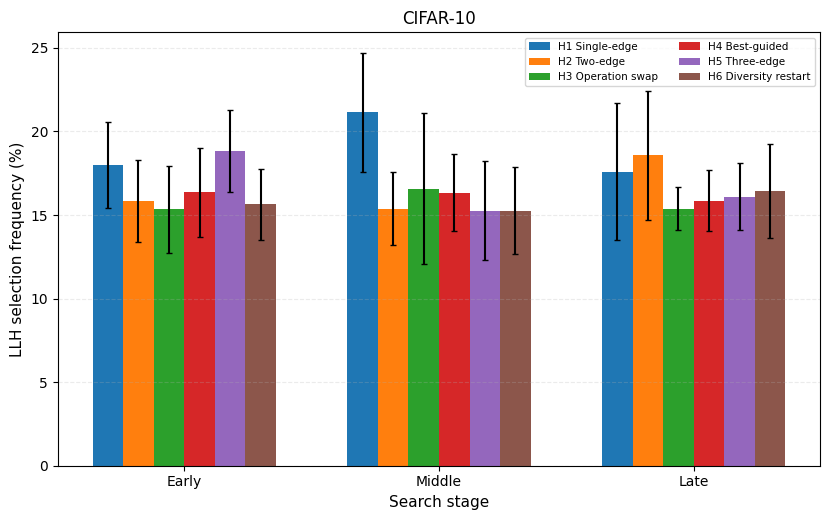

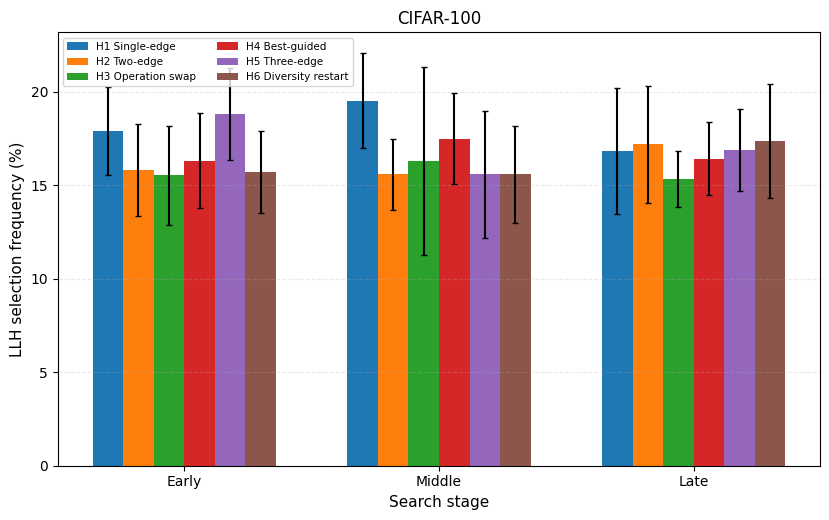

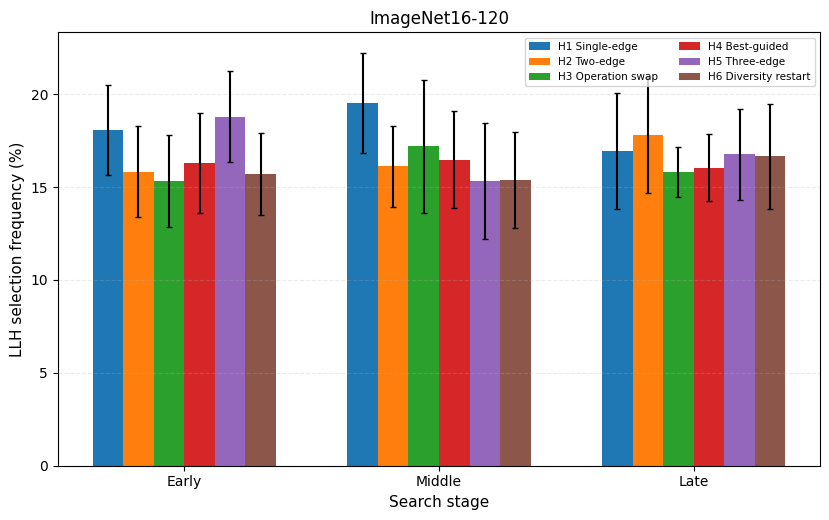

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

FIG_DIR = Path(
    "/content/drive/MyDrive/SARL_HHNAS/"
    "results/final/figures_publication"
)

FIG_DIR.mkdir(
    parents=True,
    exist_ok=True
)

LLH_NAMES = {
    "H1_single": "H1 Single-edge",
    "H2_double": "H2 Two-edge",
    "H3_swap": "H3 Operation swap",
    "H4_guided": "H4 Best-guided",
    "H5_triple": "H5 Three-edge",
    "H6_restart": "H6 Diversity restart"
}

LLH_ORDER = [
    "H1_single",
    "H2_double",
    "H3_swap",
    "H4_guided",
    "H5_triple",
    "H6_restart"
]

DATASET_NAMES = {
    "cifar10": "CIFAR-10",
    "cifar100": "CIFAR-100",
    "ImageNet16-120": "ImageNet16-120"
}


# Normalized search progress
llh["progress"] = (
    llh["evaluation"] / llh["budget"]
)

llh["stage"] = pd.cut(
    llh["progress"],
    bins=[0, 1/3, 2/3, 1.0],
    labels=[
        "Early",
        "Middle",
        "Late"
    ],
    include_lowest=True
)


# First calculate proportions PER RUN.
# This avoids treating all individual selections as independent runs.
per_run = (
    llh.groupby(
        [
            "dataset",
            "seed",
            "stage",
            "llh"
        ],
        observed=True
    )
    .size()
    .rename("count")
    .reset_index()
)


# Complete missing LLH combinations with zero
index = pd.MultiIndex.from_product(
    [
        llh["dataset"].unique(),
        sorted(llh["seed"].unique()),
        ["Early", "Middle", "Late"],
        LLH_ORDER
    ],
    names=[
        "dataset",
        "seed",
        "stage",
        "llh"
    ]
)

per_run = (
    per_run.set_index(
        ["dataset", "seed", "stage", "llh"]
    )
    .reindex(index, fill_value=0)
    .reset_index()
)


totals = (
    per_run.groupby(
        ["dataset", "seed", "stage"]
    )["count"]
    .transform("sum")
)

per_run["proportion"] = np.where(
    totals > 0,
    per_run["count"] / totals,
    0
)


selection_summary = (
    per_run.groupby(
        ["dataset", "stage", "llh"],
        observed=True
    )["proportion"]
    .agg(
        mean="mean",
        std="std"
    )
    .reset_index()
)

selection_summary.to_csv(
    FIG_DIR / "llh_stage_summary.csv",
    index=False
)


# ============================================================
# One figure per dataset
# ============================================================

STAGES = [
    "Early",
    "Middle",
    "Late"
]

for dataset, title in DATASET_NAMES.items():

    d = selection_summary[
        selection_summary["dataset"] == dataset
    ].copy()

    fig, ax = plt.subplots(
        figsize=(8.4, 5.3)
    )

    x = np.arange(len(STAGES))

    width = 0.12

    for i, heuristic in enumerate(LLH_ORDER):

        means = []
        stds = []

        for stage in STAGES:

            r = d[
                (d["stage"] == stage) &
                (d["llh"] == heuristic)
            ]

            means.append(
                float(r["mean"].iloc[0])
                if len(r) else 0
            )

            stds.append(
                float(r["std"].iloc[0])
                if len(r) else 0
            )

        offset = (
            i - (len(LLH_ORDER)-1)/2
        ) * width

        ax.bar(
            x + offset,
            np.asarray(means) * 100,
            width,
            yerr=np.asarray(stds) * 100,
            capsize=2,
            label=LLH_NAMES[heuristic]
        )

    ax.set_xticks(x)
    ax.set_xticklabels(STAGES)

    ax.set_xlabel(
        "Search stage",
        fontsize=11
    )

    ax.set_ylabel(
        "LLH selection frequency (%)",
        fontsize=11
    )

    ax.set_title(
        title,
        fontsize=12
    )

    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.25
    )

    ax.legend(
        fontsize=7.5,
        ncol=2,
        frameon=True
    )

    fig.tight_layout()

    stem = (
        "fig_llh_selection_"
        + dataset.replace("-", "_").lower()
    )

    fig.savefig(
        FIG_DIR / f"{stem}.png",
        dpi=600,
        bbox_inches="tight"
    )

    fig.savefig(
        FIG_DIR / f"{stem}.pdf",
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

/tmp/ipykernel_3946/523959803.py:58: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  counts.groupby(


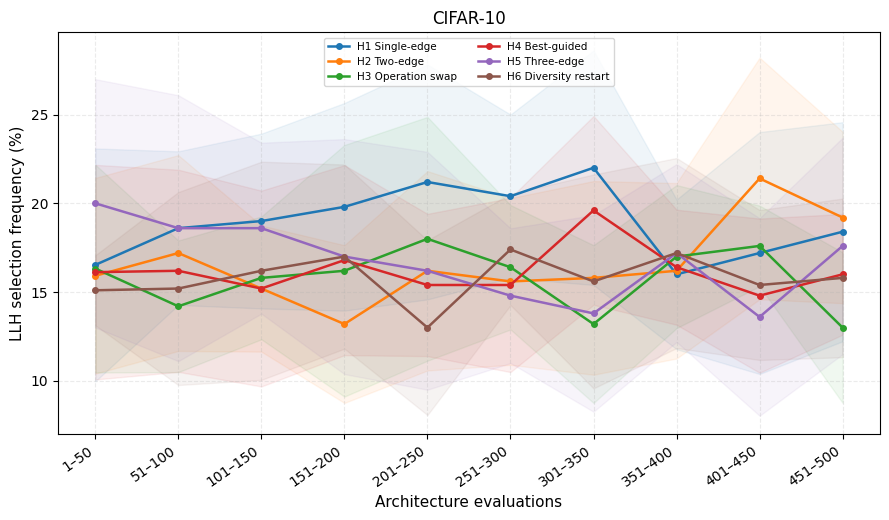

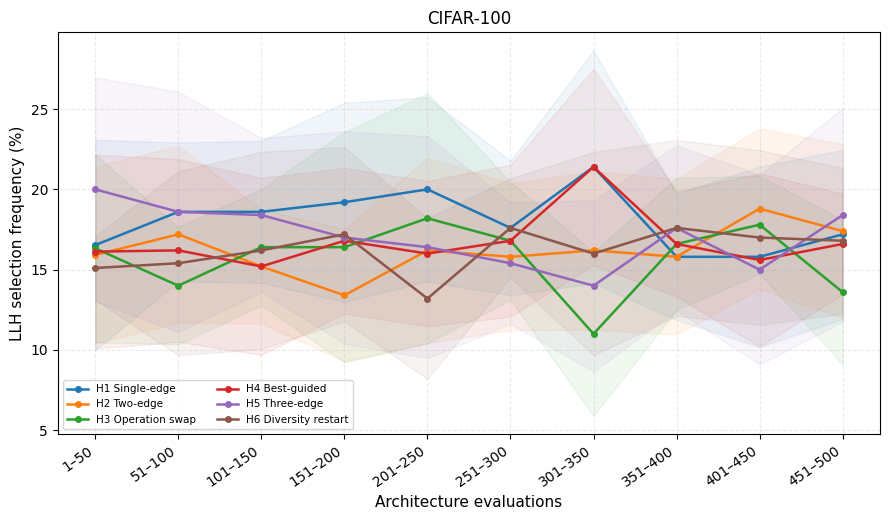

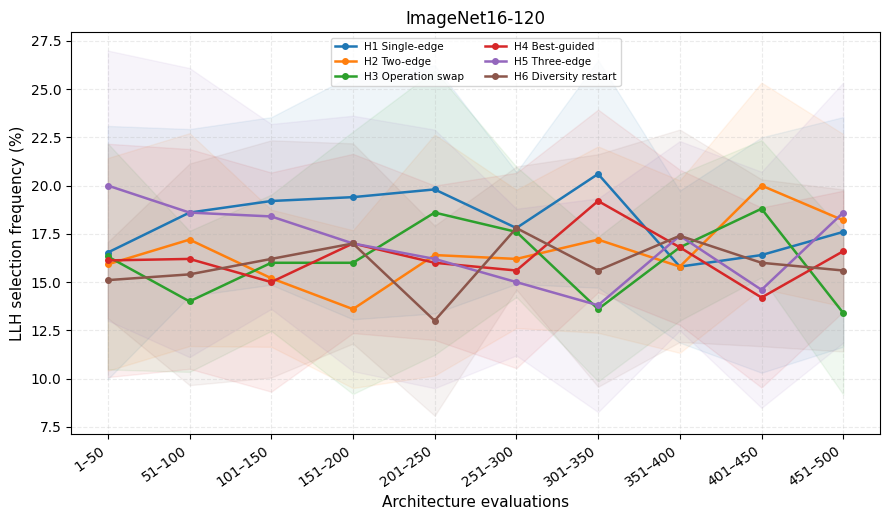

In [ ]:
# ============================================================
# 10 search intervals
# ============================================================

llh["interval"] = pd.cut(
    llh["evaluation"],
    bins=[
        0, 50, 100, 150, 200,
        250, 300, 350, 400, 450, 500
    ],
    labels=[
        "1–50",
        "51–100",
        "101–150",
        "151–200",
        "201–250",
        "251–300",
        "301–350",
        "351–400",
        "401–450",
        "451–500"
    ],
    include_lowest=True
)

INTERVALS = [
    "1–50",
    "51–100",
    "101–150",
    "151–200",
    "201–250",
    "251–300",
    "301–350",
    "351–400",
    "401–450",
    "451–500"
]


counts = (
    llh.groupby(
        [
            "dataset",
            "seed",
            "interval",
            "llh"
        ],
        observed=True
    )
    .size()
    .rename("count")
    .reset_index()
)


# Calculate proportions inside each run and interval
totals = (
    counts.groupby(
        [
            "dataset",
            "seed",
            "interval"
        ]
    )["count"]
    .transform("sum")
)

counts["proportion"] = (
    counts["count"] / totals
)


dynamic = (
    counts.groupby(
        [
            "dataset",
            "interval",
            "llh"
        ],
        observed=True
    )["proportion"]
    .agg(
        mean="mean",
        std="std"
    )
    .reset_index()
)


for dataset, title in DATASET_NAMES.items():

    fig, ax = plt.subplots(
        figsize=(9.0, 5.3)
    )

    for heuristic in LLH_ORDER:

        x = dynamic[
            (dynamic["dataset"] == dataset) &
            (dynamic["llh"] == heuristic)
        ].copy()

        x["interval"] = pd.Categorical(
            x["interval"],
            categories=INTERVALS,
            ordered=True
        )

        x = x.sort_values("interval")

        if x.empty:
            continue

        xx = np.arange(len(x))

        mean = (
            x["mean"].to_numpy() * 100
        )

        std = (
            x["std"]
            .fillna(0)
            .to_numpy() * 100
        )

        line, = ax.plot(
            xx,
            mean,
            marker="o",
            markersize=4,
            linewidth=1.8,
            label=LLH_NAMES[heuristic]
        )

        ax.fill_between(
            xx,
            np.clip(mean - std, 0, 100),
            np.clip(mean + std, 0, 100),
            alpha=0.07,
            color=line.get_color()
        )

    ax.set_xticks(
        np.arange(len(INTERVALS))
    )

    ax.set_xticklabels(
        INTERVALS,
        rotation=35,
        ha="right"
    )

    ax.set_xlabel(
        "Architecture evaluations",
        fontsize=11
    )

    ax.set_ylabel(
        "LLH selection frequency (%)",
        fontsize=11
    )

    ax.set_title(
        title,
        fontsize=12
    )

    ax.grid(
        True,
        linestyle="--",
        alpha=0.25
    )

    ax.legend(
        fontsize=7.5,
        ncol=2
    )

    fig.tight_layout()

    stem = (
        "fig_llh_dynamics_"
        + dataset.replace("-", "_").lower()
    )

    fig.savefig(
        FIG_DIR / f"{stem}.png",
        dpi=600,
        bbox_inches="tight"
    )

    fig.savefig(
        FIG_DIR / f"{stem}.pdf",
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

Reading: /content/drive/MyDrive/SARL_HHNAS/results/final/llh_behavior/sarl_llh_behavior.csv
Shape: (14970, 7)
Columns: ['dataset', 'seed', 'budget', 'evaluation', 'llh', 'best_val', 'current_val']
   dataset  seed  budget  evaluation        llh  best_val  current_val
0  cifar10     0     500           2  H4_guided    89.852       89.852
1  cifar10     0     500           3  H5_triple    90.128       90.128
2  cifar10     0     500           4    H3_swap    90.128       90.128
3  cifar10     0     500           5    H3_swap    90.362       90.362
4  cifar10     0     500           6  H2_double    90.362       90.362

Datasets:
dataset
cifar10           4990
cifar100          4990
ImageNet16-120    4990
Name: count, dtype: int64

LLHs:
llh
H1_single     2753
H5_triple     2533
H2_double     2463
H4_guided     2455
H6_restart    2391
H3_swap       2375
Name: count, dtype: int64

Evaluation range:
2 to 500


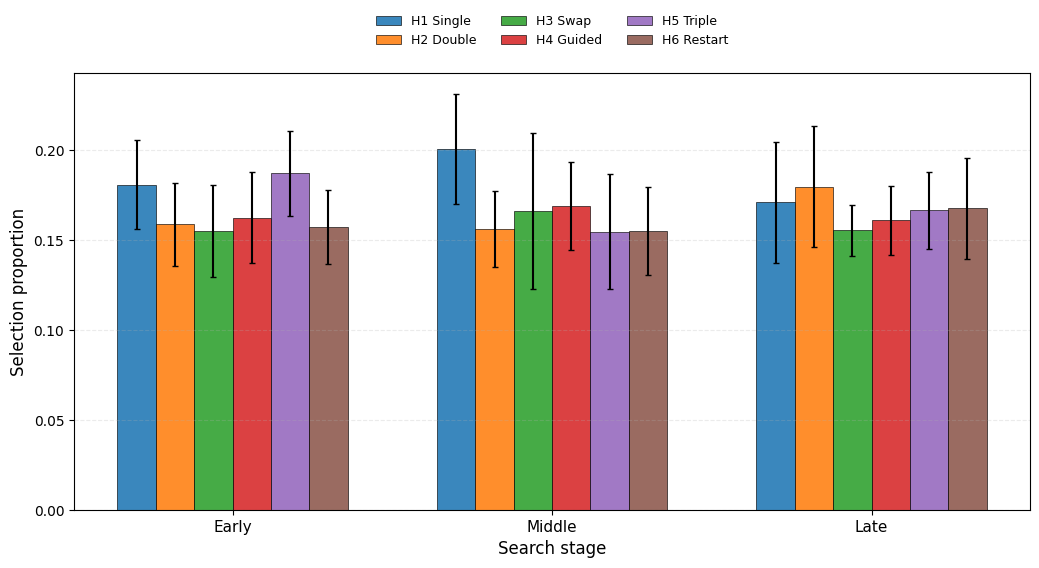


Saved:
/content/drive/MyDrive/SARL_HHNAS/figures/fig_llh_stage_frequency.png
/content/drive/MyDrive/SARL_HHNAS/figures/fig_llh_stage_frequency.pdf


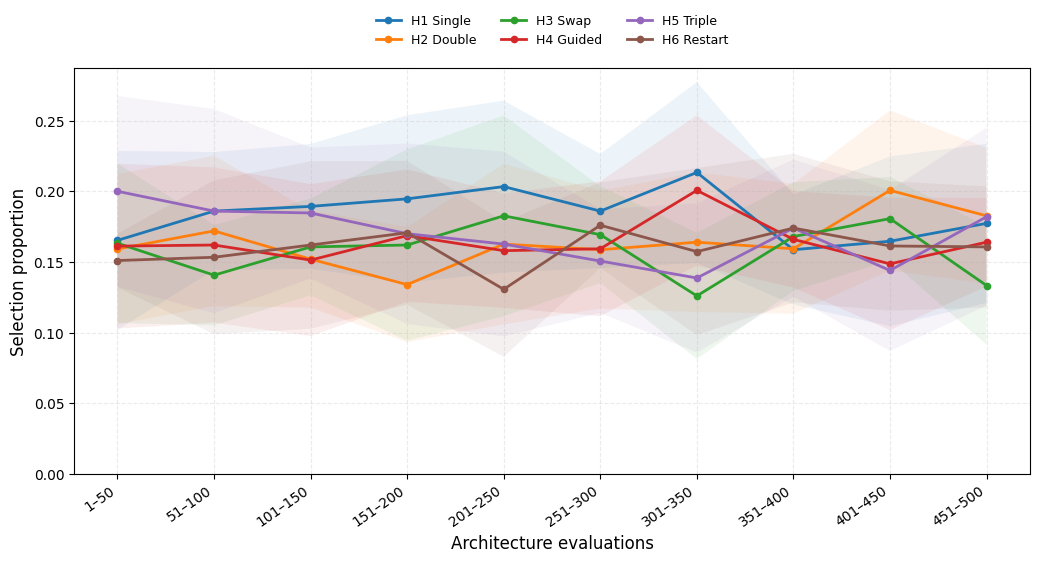


Saved:
/content/drive/MyDrive/SARL_HHNAS/figures/llh_selection_dynamics.png
/content/drive/MyDrive/SARL_HHNAS/figures/llh_selection_dynamics.pdf

✓ LLH behaviour figures and numerical summaries generated.


In [ ]:
# ============================================================
# LLH-SELECTION BEHAVIOUR FIGURES
# Generates:
#   1. fig_llh_stage_frequency.pdf/png
#   2. llh_selection_dynamics.pdf/png
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

PROJECT_DIR = Path("/content/drive/MyDrive/SARL_HHNAS")

DATA_FILE = (
    PROJECT_DIR
    / "results/final/llh_behavior/sarl_llh_behavior.csv"
)

FIG_DIR = PROJECT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("Reading:", DATA_FILE)

df = pd.read_csv(DATA_FILE)

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print(df.head())


# ============================================================
# BASIC CHECKS
# ============================================================

required = {"dataset", "seed", "evaluation", "llh"}

missing = required - set(df.columns)

if missing:
    raise ValueError(
        f"Missing required columns: {sorted(missing)}"
    )

df = df.copy()

df["evaluation"] = pd.to_numeric(
    df["evaluation"],
    errors="coerce"
)

df = df.dropna(
    subset=["dataset", "seed", "evaluation", "llh"]
)

df["evaluation"] = df["evaluation"].astype(int)


# ------------------------------------------------------------
# Standard LLH order
# ------------------------------------------------------------

LLH_ORDER = [
    "H1_single",
    "H2_double",
    "H3_swap",
    "H4_guided",
    "H5_triple",
    "H6_restart",
]

LLH_LABELS = {
    "H1_single": "H1 Single",
    "H2_double": "H2 Double",
    "H3_swap": "H3 Swap",
    "H4_guided": "H4 Guided",
    "H5_triple": "H5 Triple",
    "H6_restart": "H6 Restart",
}

print("\nDatasets:")
print(df["dataset"].value_counts())

print("\nLLHs:")
print(df["llh"].value_counts())

print("\nEvaluation range:")
print(
    df["evaluation"].min(),
    "to",
    df["evaluation"].max()
)


# ============================================================
# FIGURE 1
# LLH SELECTION FREQUENCY:
# EARLY / MIDDLE / LATE
# ============================================================

# For B = 500:
#
# Early  : 1--167
# Middle : 168--334
# Late   : 335--500
#
# This divides the search approximately into thirds.

def assign_stage(evaluation):

    if evaluation <= 167:
        return "Early"

    elif evaluation <= 334:
        return "Middle"

    else:
        return "Late"


df["stage"] = df["evaluation"].apply(assign_stage)

STAGE_ORDER = [
    "Early",
    "Middle",
    "Late"
]


# ------------------------------------------------------------
# Calculate proportion PER RUN first
#
# Important:
# We do not simply pool all actions.
# Each dataset × seed run contributes equally.
# ------------------------------------------------------------

stage_counts = (
    df.groupby(
        ["dataset", "seed", "stage", "llh"]
    )
    .size()
    .rename("count")
    .reset_index()
)


# Total actions in each run/stage
stage_totals = (
    stage_counts
    .groupby(
        ["dataset", "seed", "stage"]
    )["count"]
    .transform("sum")
)

stage_counts["proportion"] = (
    stage_counts["count"]
    / stage_totals
)


# ------------------------------------------------------------
# Ensure missing LLHs receive proportion = 0
# ------------------------------------------------------------

run_ids = (
    df[["dataset", "seed"]]
    .drop_duplicates()
)

full_index = pd.MultiIndex.from_product(
    [
        sorted(df["dataset"].unique()),
        sorted(df["seed"].unique()),
        STAGE_ORDER,
        LLH_ORDER,
    ],
    names=[
        "dataset",
        "seed",
        "stage",
        "llh"
    ]
)

stage_full = (
    stage_counts
    .set_index(
        ["dataset", "seed", "stage", "llh"]
    )
    .reindex(full_index)
    .reset_index()
)

# Remove dataset-seed combinations that do not actually exist
valid_runs = set(
    zip(
        run_ids["dataset"],
        run_ids["seed"]
    )
)

stage_full = stage_full[
    stage_full.apply(
        lambda r:
        (r["dataset"], r["seed"])
        in valid_runs,
        axis=1
    )
].copy()

stage_full["proportion"] = (
    stage_full["proportion"]
    .fillna(0.0)
)


# ------------------------------------------------------------
# Mean and SD across independent runs
# ------------------------------------------------------------

stage_summary = (
    stage_full
    .groupby(
        ["stage", "llh"],
        as_index=False
    )
    .agg(
        mean=("proportion", "mean"),
        std=("proportion", "std"),
        n=("proportion", "count"),
    )
)

stage_summary["stage"] = pd.Categorical(
    stage_summary["stage"],
    categories=STAGE_ORDER,
    ordered=True
)

stage_summary["llh"] = pd.Categorical(
    stage_summary["llh"],
    categories=LLH_ORDER,
    ordered=True
)

stage_summary = stage_summary.sort_values(
    ["stage", "llh"]
)


# ------------------------------------------------------------
# Plot grouped bars
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(10.5, 5.8)
)

x = np.arange(
    len(STAGE_ORDER)
)

n_llh = len(LLH_ORDER)

width = 0.12

offsets = (
    np.arange(n_llh)
    - (n_llh - 1) / 2
) * width


for i, llh in enumerate(LLH_ORDER):

    temp = (
        stage_summary[
            stage_summary["llh"] == llh
        ]
        .set_index("stage")
        .reindex(STAGE_ORDER)
    )

    ax.bar(
        x + offsets[i],
        temp["mean"],
        width=width,
        yerr=temp["std"],
        capsize=2.5,
        label=LLH_LABELS[llh],
        alpha=0.88,
        edgecolor="black",
        linewidth=0.5,
    )


ax.set_xticks(x)

ax.set_xticklabels(
    STAGE_ORDER,
    fontsize=11
)

ax.set_xlabel(
    "Search stage",
    fontsize=12
)

ax.set_ylabel(
    "Selection proportion",
    fontsize=12
)

ax.set_ylim(
    bottom=0
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

ax.legend(
    ncol=3,
    frameon=False,
    fontsize=9,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.16)
)

fig.tight_layout()


# Save
stage_png = (
    FIG_DIR /
    "fig_llh_stage_frequency.png"
)

stage_pdf = (
    FIG_DIR /
    "fig_llh_stage_frequency.pdf"
)

fig.savefig(
    stage_png,
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    stage_pdf,
    bbox_inches="tight"
)

plt.show()

print("\nSaved:")
print(stage_png)
print(stage_pdf)


# ============================================================
# FIGURE 2
# LLH SELECTION DYNAMICS
# 10 INTERVALS × 50 EVALUATIONS
# ============================================================

# 1--50, 51--100, ..., 451--500

df["interval"] = (
    ((df["evaluation"] - 1) // 50) + 1
)

df["interval"] = df["interval"].clip(
    1,
    10
)

INTERVALS = list(
    range(1, 11)
)


# ------------------------------------------------------------
# Per-run LLH proportions
# ------------------------------------------------------------

dynamic_counts = (
    df.groupby(
        [
            "dataset",
            "seed",
            "interval",
            "llh"
        ]
    )
    .size()
    .rename("count")
    .reset_index()
)


dynamic_totals = (
    dynamic_counts
    .groupby(
        [
            "dataset",
            "seed",
            "interval"
        ]
    )["count"]
    .transform("sum")
)

dynamic_counts["proportion"] = (
    dynamic_counts["count"]
    / dynamic_totals
)


# ------------------------------------------------------------
# Complete missing LLHs with zero
# ------------------------------------------------------------

dynamic_index = pd.MultiIndex.from_product(
    [
        sorted(df["dataset"].unique()),
        sorted(df["seed"].unique()),
        INTERVALS,
        LLH_ORDER,
    ],
    names=[
        "dataset",
        "seed",
        "interval",
        "llh"
    ]
)

dynamic_full = (
    dynamic_counts
    .set_index(
        [
            "dataset",
            "seed",
            "interval",
            "llh"
        ]
    )
    .reindex(dynamic_index)
    .reset_index()
)

dynamic_full = dynamic_full[
    dynamic_full.apply(
        lambda r:
        (r["dataset"], r["seed"])
        in valid_runs,
        axis=1
    )
].copy()

dynamic_full["proportion"] = (
    dynamic_full["proportion"]
    .fillna(0.0)
)


# ------------------------------------------------------------
# Mean and SD across runs
# ------------------------------------------------------------

dynamic_summary = (
    dynamic_full
    .groupby(
        ["interval", "llh"],
        as_index=False
    )
    .agg(
        mean=("proportion", "mean"),
        std=("proportion", "std"),
        n=("proportion", "count"),
    )
)


# ============================================================
# Plot
# ============================================================

fig, ax = plt.subplots(
    figsize=(10.5, 5.8)
)


for llh in LLH_ORDER:

    temp = (
        dynamic_summary[
            dynamic_summary["llh"] == llh
        ]
        .sort_values("interval")
    )

    xvals = temp["interval"].to_numpy()

    means = temp["mean"].to_numpy()

    stds = (
        temp["std"]
        .fillna(0)
        .to_numpy()
    )

    ax.plot(
        xvals,
        means,
        marker="o",
        linewidth=2.0,
        markersize=4.5,
        label=LLH_LABELS[llh],
    )

    lower = np.maximum(
        0,
        means - stds
    )

    upper = np.minimum(
        1,
        means + stds
    )

    ax.fill_between(
        xvals,
        lower,
        upper,
        alpha=0.08
    )


ax.set_xticks(
    INTERVALS
)

ax.set_xticklabels(
    [
        "1–50",
        "51–100",
        "101–150",
        "151–200",
        "201–250",
        "251–300",
        "301–350",
        "351–400",
        "401–450",
        "451–500",
    ],
    rotation=35,
    ha="right"
)

ax.set_xlabel(
    "Architecture evaluations",
    fontsize=12
)

ax.set_ylabel(
    "Selection proportion",
    fontsize=12
)

ax.set_ylim(
    bottom=0
)

ax.grid(
    linestyle="--",
    alpha=0.25
)

ax.legend(
    ncol=3,
    frameon=False,
    fontsize=9,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.16)
)

fig.tight_layout()


# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

dynamic_png = (
    FIG_DIR /
    "llh_selection_dynamics.png"
)

dynamic_pdf = (
    FIG_DIR /
    "llh_selection_dynamics.pdf"
)

fig.savefig(
    dynamic_png,
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    dynamic_pdf,
    bbox_inches="tight"
)

plt.show()

print("\nSaved:")
print(dynamic_png)
print(dynamic_pdf)


# ============================================================
# SAVE NUMERICAL DATA USED IN FIGURES
# ============================================================

stage_summary.to_csv(
    FIG_DIR /
    "llh_stage_frequency_summary.csv",
    index=False
)

dynamic_summary.to_csv(
    FIG_DIR /
    "llh_selection_dynamics_summary.csv",
    index=False
)

print(
    "\n✓ LLH behaviour figures and numerical summaries generated."
)

In [ ]:
%cd /content/drive/MyDrive/SARL_HHNAS

import json
import time
from pathlib import Path

from benchmark.nats import NATSBenchTSS

ROOT = Path("/content/drive/MyDrive/SARL_HHNAS")

NATS_PATH = (
    "/content/drive/MyDrive/NATS_Bench/"
    "TSS_FAST/NATS-tss-v1_0-3ffb9-simple"
)

OUT = ROOT / "results/final/statistics"
OUT.mkdir(parents=True, exist_ok=True)

OPT_FILE = OUT / "reference_best_validation.json"

bench = NATSBenchTSS(
    NATS_PATH,
    hp="200",
    fast_mode=True,
    verbose=False,
    trial_seed=False
)

datasets = [
    "cifar10",
    "cifar100",
    "ImageNet16-120"
]

# Resume/cache
if OPT_FILE.exists():
    with open(OPT_FILE, "r") as f:
        optima = json.load(f)
else:
    optima = {}

for dataset in datasets:

    if dataset in optima:
        print(
            f"[CACHED] {dataset}: "
            f"{optima[dataset]:.6f}"
        )
        continue

    print(f"\nComputing exact validation reference: {dataset}")

    start = time.perf_counter()

    optimum = bench.reference_best_validation(dataset)

    elapsed = time.perf_counter() - start

    optima[dataset] = float(optimum)

    with open(OPT_FILE, "w") as f:
        json.dump(
            optima,
            f,
            indent=2
        )

    print(
        f"{dataset}: "
        f"{optimum:.6f}% "
        f"({elapsed:.2f}s)"
    )

print("\nExact validation references:")
print(optima)

In [ ]:
%cd /content/drive/MyDrive/SARL_HHNAS

import numpy as np
import pandas as pd
from pathlib import Path
from scipy.stats import friedmanchisquare, wilcoxon

ROOT = Path("/content/drive/MyDrive/SARL_HHNAS")

MAIN = ROOT / "results/final/raw/main_results.csv"

STAT_DIR = ROOT / "results/final/statistics"
STAT_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(MAIN)

print("Rows:", len(df))
print("Columns:")
print(df.columns.tolist())

RQ1_METHODS = [
    "random",
    "rea",
    "reinforce",
    "random-hh",
    "greedy-hh",
    "cf-hh",
    "sarl"
]

METHOD_NAMES = {
    "random": "Random Search",
    "rea": "REA",
    "reinforce": "REINFORCE",
    "random-hh": "Random-HH",
    "greedy-hh": "Greedy-HH",
    "cf-hh": "CF-HH",
    "sarl": "SARL-Online"
}

rq1 = df[
    df["method"].isin(RQ1_METHODS)
].copy()

print("\nRQ1 runs:")
print(
    rq1.groupby(
        ["dataset", "budget", "method"]
    ).size()
)

In [ ]:
!mkdir -p /content/NATS_TSS_FAST

!cp -r \
"/content/drive/MyDrive/NATS_Bench/TSS_FAST/NATS-tss-v1_0-3ffb9-simple" \
"/content/NATS_TSS_FAST/"

In [ ]:
# ============================================================
# LOAD LOCAL NATS-BENCH
# ============================================================

%cd /content/drive/MyDrive/SARL_HHNAS

import sys
from pathlib import Path

# Make sure project can be imported
PROJECT_ROOT = Path("/content/drive/MyDrive/SARL_HHNAS")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Import our NATS-Bench adapter
from benchmark.nats import NATSBenchTSS


# ============================================================
# LOCAL NATS-BENCH PATH
# ============================================================

LOCAL_NATS_PATH = (
    "/content/NATS_TSS_FAST/"
    "NATS-tss-v1_0-3ffb9-simple"
)

print("Checking:")
print(LOCAL_NATS_PATH)

if not Path(LOCAL_NATS_PATH).exists():
    raise FileNotFoundError(
        "Local NATS-Bench copy was not found.\n"
        "Run the copy cell first."
    )


# ============================================================
# INITIALIZE BENCHMARK
# ============================================================

bench_local = NATSBenchTSS(
    LOCAL_NATS_PATH,
    hp="200",
    fast_mode=True,
    verbose=False,
    trial_seed=False
)

print("\n✓ NATSBenchTSS imported")
print("✓ Local benchmark found")
print("✓ bench_local initialized successfully")

In [ ]:
import json
import time
from pathlib import Path

STAT_DIR = Path(
    "/content/drive/MyDrive/SARL_HHNAS/"
    "results/final/statistics"
)

STAT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

OPT_FILE = (
    STAT_DIR /
    "reference_best_validation.json"
)


# Resume previous completed datasets
if OPT_FILE.exists():
    with open(OPT_FILE, "r") as f:
        optima = json.load(f)
else:
    optima = {}


datasets = [
    "cifar10",
    "cifar100",
    "ImageNet16-120"
]


for dataset in datasets:

    # Skip already completed dataset
    if dataset in optima:

        print(
            f"[CACHED] {dataset}: "
            f"{optima[dataset]:.6f}%"
        )

        continue


    print("\n" + "=" * 60)
    print(
        f"Computing exact validation reference: "
        f"{dataset}"
    )
    print("=" * 60)

    start = time.perf_counter()

    optimum = (
        bench_local
        .reference_best_validation(dataset)
    )

    elapsed = (
        time.perf_counter() - start
    )

    optima[dataset] = float(optimum)


    # Save immediately
    with open(OPT_FILE, "w") as f:

        json.dump(
            optima,
            f,
            indent=2
        )


    print(
        f"✓ {dataset}: "
        f"{optimum:.6f}%"
    )

    print(
        f"Time: {elapsed:.2f} seconds"
    )

    print(
        "✓ Saved immediately to:",
        OPT_FILE
    )


print("\n" + "=" * 60)
print("EXACT VALIDATION REFERENCES")
print("=" * 60)

for dataset, value in optima.items():

    print(
        f"{dataset:18s}: "
        f"{value:.6f}%"
    )

In [ ]:
import json
import time
from pathlib import Path

STAT_DIR = Path(
    "/content/drive/MyDrive/SARL_HHNAS/"
    "results/final/statistics"
)

STAT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

OPT_FILE = (
    STAT_DIR /
    "reference_best_validation.json"
)


# Resume previous completed datasets
if OPT_FILE.exists():
    with open(OPT_FILE, "r") as f:
        optima = json.load(f)
else:
    optima = {}


datasets = [
    "cifar10",
    "cifar100",
    "ImageNet16-120"
]


for dataset in datasets:

    # Skip already completed dataset
    if dataset in optima:

        print(
            f"[CACHED] {dataset}: "
            f"{optima[dataset]:.6f}%"
        )

        continue


    print("\n" + "=" * 60)
    print(
        f"Computing exact validation reference: "
        f"{dataset}"
    )
    print("=" * 60)

    start = time.perf_counter()

    optimum = (
        bench_local
        .reference_best_validation(dataset)
    )

    elapsed = (
        time.perf_counter() - start
    )

    optima[dataset] = float(optimum)


    # Save immediately
    with open(OPT_FILE, "w") as f:

        json.dump(
            optima,
            f,
            indent=2
        )


    print(
        f"✓ {dataset}: "
        f"{optimum:.6f}%"
    )

    print(
        f"Time: {elapsed:.2f} seconds"
    )

    print(
        "✓ Saved immediately to:",
        OPT_FILE
    )


print("\n" + "=" * 60)
print("EXACT VALIDATION REFERENCES")
print("=" * 60)

for dataset, value in optima.items():

    print(
        f"{dataset:18s}: "
        f"{value:.6f}%"
    )

In [ ]:
%cd /content/drive/MyDrive/SARL_HHNAS

import numpy as np
import pandas as pd
from pathlib import Path
from scipy.stats import friedmanchisquare, wilcoxon, rankdata

ROOT = Path("/content/drive/MyDrive/SARL_HHNAS")
MAIN = ROOT / "results/final/raw/main_results.csv"

STAT_DIR = ROOT / "results/final/statistics"
STAT_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(MAIN)

print("Columns:")
print(df.columns.tolist())

# ============================================================
# Detect search-seed column automatically
# ============================================================

SEED_CANDIDATES = [
    "seed",
    "search_seed",
    "run_seed",
    "random_seed",
    "searchseed",
    "run",
    "trial",
    "trial_seed"
]

seed_col = None

for c in SEED_CANDIDATES:
    if c in df.columns:
        seed_col = c
        break

if seed_col is None:
    # Try case-insensitive detection
    lower_map = {
        str(c).lower(): c
        for c in df.columns
    }

    for c in SEED_CANDIDATES:
        if c.lower() in lower_map:
            seed_col = lower_map[c.lower()]
            break

if seed_col is None:
    raise ValueError(
        "Cannot find the search-seed column.\n"
        f"Available columns are:\n{df.columns.tolist()}"
    )

print("\n✓ Detected seed column:", seed_col)

# Standardize name for statistical analysis
df["stat_seed"] = df[seed_col]

RQ1_METHODS = [
    "random",
    "rea",
    "reinforce",
    "random-hh",
    "greedy-hh",
    "cf-hh",
    "sarl"
]

METHOD_NAMES = {
    "random": "Random Search",
    "rea": "REA",
    "reinforce": "REINFORCE",
    "random-hh": "Random-HH",
    "greedy-hh": "Greedy-HH",
    "cf-hh": "CF-HH",
    "sarl": "SARL-Online"
}

rq1 = df[
    df["method"].isin(RQ1_METHODS)
].copy()

print("\nRQ1 rows:", len(rq1))

check = (
    rq1.groupby(
        ["dataset", "budget", "method"]
    )
    .size()
    .unstack(fill_value=0)
)

display(check)

print("\nUnique statistical seeds:")
print(sorted(rq1["stat_seed"].unique()))

In [ ]:
print(df.columns.tolist())

display(df.head(10))

In [ ]:
friedman_results = []

for (dataset, budget), g in rq1.groupby(
    ["dataset", "budget"]
):

    pivot = (
        g.pivot_table(
            index="stat_seed",
            columns="method",
            values="search_auc",
            aggfunc="mean"
        )
        .reindex(columns=RQ1_METHODS)
        .dropna()
        .sort_index()
    )

    print(
        f"{dataset}, B={budget}: "
        f"{len(pivot)} matched runs"
    )

    if len(pivot) < 2:
        print("  SKIPPED: insufficient matched runs")
        continue

    stat, p = friedmanchisquare(
        *[
            pivot[m].to_numpy()
            for m in RQ1_METHODS
        ]
    )

    n = len(pivot)
    k = len(RQ1_METHODS)

    kendall_w = (
        stat /
        (n * (k - 1))
    )

    friedman_results.append({
        "dataset": dataset,
        "budget": int(budget),
        "n_matched_runs": n,
        "friedman_chi2": stat,
        "df": k - 1,
        "p_value": p,
        "kendall_W": kendall_w,
        "significant_0.05": p < 0.05
    })


friedman_df = pd.DataFrame(
    friedman_results
)

display(
    friedman_df.round(6)
)

friedman_df.to_csv(
    STAT_DIR /
    "friedman_by_dataset_budget.csv",
    index=False
)

print("✓ Saved.")

In [ ]:
import pandas as pd
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/SARL_HHNAS")

MAIN = ROOT / "results/final/raw/main_results.csv"

df = pd.read_csv(MAIN)

print("=" * 70)
print("ALL METHOD NAMES IN main_results.csv")
print("=" * 70)

print(
    df["method"]
    .value_counts(dropna=False)
    .to_string()
)

print("\nUnique method names:")
for x in df["method"].unique():
    print(repr(x))

print("\nTotal rows:", len(df))


# ------------------------------------------------------------
# Look for anything containing SARL / RL / online
# ------------------------------------------------------------

mask = (
    df["method"]
    .astype(str)
    .str.lower()
    .str.contains(
        "sarl|online",
        regex=True,
        na=False
    )
)

possible_sarl = df[mask]

print("\n" + "=" * 70)
print("POSSIBLE SARL ROWS")
print("=" * 70)

print("Rows found:", len(possible_sarl))

if len(possible_sarl):

    print(
        possible_sarl["method"]
        .value_counts()
    )

    display(
        possible_sarl.head(20)
    )

else:
    print(
        "No SARL-like rows exist in main_results.csv"
    )

In [ ]:
from pathlib import Path
import pandas as pd

RESULT_ROOT = Path(
    "/content/drive/MyDrive/SARL_HHNAS/results"
)

print("Searching CSV files...\n")

for f in RESULT_ROOT.rglob("*.csv"):

    try:
        temp = pd.read_csv(f)

        # Search method column
        if "method" in temp.columns:

            methods = (
                temp["method"]
                .astype(str)
                .unique()
            )

            has_sarl = any(
                "sarl" in x.lower()
                for x in methods
            )

            if has_sarl:

                print("=" * 70)
                print("FOUND SARL:")
                print(f)
                print("Rows:", len(temp))
                print("Methods:", methods)

    except Exception:
        pass

In [ ]:
# ============================================================
# CELL 1 — LOAD RQ1 DATA CORRECTLY
# ============================================================

%cd /content/drive/MyDrive/SARL_HHNAS

import numpy as np
import pandas as pd
from pathlib import Path
from scipy.stats import friedmanchisquare, wilcoxon, rankdata

ROOT = Path(
    "/content/drive/MyDrive/SARL_HHNAS"
)

MAIN = (
    ROOT /
    "results/final/raw/main_results.csv"
)

STAT_DIR = (
    ROOT /
    "results/final/statistics"
)

STAT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

df = pd.read_csv(MAIN)

print("Total rows in main_results.csv:", len(df))

print("\nAll methods:")
print(
    df["method"]
    .value_counts()
)


# ============================================================
# RQ1 METHODS
# IMPORTANT:
# SARL is stored as "sarl-online" in main_results.csv
# ============================================================

RQ1_METHODS = [
    "random",
    "rea",
    "reinforce",
    "random-hh",
    "greedy-hh",
    "cf-hh",
    "sarl-online"
]


METHOD_NAMES = {
    "random": "Random Search",
    "rea": "REA",
    "reinforce": "REINFORCE",
    "random-hh": "Random-HH",
    "greedy-hh": "Greedy-HH",
    "cf-hh": "CF-HH",
    "sarl-online": "SARL-Online"
}


# ============================================================
# SELECT ONLY RQ1
# ============================================================

rq1 = df[
    df["method"].isin(
        RQ1_METHODS
    )
].copy()


# Actual matched search seed
rq1["stat_seed"] = rq1["search_seed"]


print("\n" + "=" * 70)
print("RQ1 DATA")
print("=" * 70)

print(
    "RQ1 rows:",
    len(rq1)
)

print("\nRows per method:")

print(
    rq1["method"]
    .value_counts()
    .reindex(RQ1_METHODS)
)


print("\nRows per dataset × budget × method:")

check = (
    rq1.groupby(
        [
            "dataset",
            "budget",
            "method"
        ]
    )
    .size()
    .unstack(fill_value=0)
    .reindex(
        columns=RQ1_METHODS
    )
)

display(check)


print("\nSearch seeds:")
print(
    sorted(
        rq1[
            "stat_seed"
        ].unique()
    )
)

In [ ]:
# ============================================================
# CELL 2 — FRIEDMAN PER DATASET × BUDGET
# ============================================================

friedman_results = []

for (dataset, budget), g in rq1.groupby(
    ["dataset", "budget"]
):

    pivot = (
        g.pivot_table(
            index="stat_seed",
            columns="method",
            values="search_auc",
            aggfunc="mean"
        )
        .reindex(columns=RQ1_METHODS)
        .dropna()
        .sort_index()
    )

    print(
        f"{dataset}, B={budget}: "
        f"{len(pivot)} matched runs"
    )

    if len(pivot) < 2:
        continue

    stat, p = friedmanchisquare(
        *[
            pivot[m].to_numpy()
            for m in RQ1_METHODS
        ]
    )

    n = len(pivot)
    k = len(RQ1_METHODS)

    kendall_w = (
        stat /
        (n * (k - 1))
    )

    friedman_results.append({
        "dataset": dataset,
        "budget": int(budget),
        "n_matched_runs": n,
        "friedman_chi2": stat,
        "df": k - 1,
        "p_value": p,
        "kendall_W": kendall_w,
        "significant_0.05": p < 0.05
    })


friedman_df = pd.DataFrame(
    friedman_results
)

display(
    friedman_df.round(6)
)

friedman_df.to_csv(
    STAT_DIR /
    "friedman_by_dataset_budget.csv",
    index=False
)

print("\n✓ Cell 2 completed.")

In [ ]:
# ============================================================
# CELL 3 — WILCOXON SIGNED-RANK TEST
# SARL-Online vs. each baseline
# ============================================================

import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

BASELINES = [
    "random",
    "rea",
    "reinforce",
    "random-hh",
    "greedy-hh",
    "cf-hh"
]

wilcoxon_results = []

for (dataset, budget), g in rq1.groupby(
    ["dataset", "budget"]
):

    print("\n" + "=" * 65)
    print(f"{dataset} | B={budget}")
    print("=" * 65)

    # --------------------------------------------------------
    # Create matched-seed matrix
    # --------------------------------------------------------

    pivot = (
        g.pivot_table(
            index="stat_seed",
            columns="method",
            values="search_auc",
            aggfunc="mean"
        )
        .reindex(columns=RQ1_METHODS)
        .sort_index()
    )

    matched = pivot.dropna()

    print(
        "Matched seeds:",
        matched.index.tolist()
    )

    print(
        "Number of matched runs:",
        len(matched)
    )

    # --------------------------------------------------------
    # Require matched runs
    # --------------------------------------------------------

    if len(matched) < 2:

        print(
            "WARNING: insufficient matched runs."
        )

        continue

    # --------------------------------------------------------
    # SARL-Online values
    # IMPORTANT: outside the IF block
    # --------------------------------------------------------

    sarl = (
        matched[
            "sarl-online"
        ]
        .to_numpy()
    )

    # --------------------------------------------------------
    # SARL vs. each baseline
    # --------------------------------------------------------

    for baseline in BASELINES:

        base = (
            matched[
                baseline
            ]
            .to_numpy()
        )

        diff = (
            sarl - base
        )

        if np.allclose(
            diff,
            0
        ):

            W = 0.0
            p = 1.0

        else:

            W, p = wilcoxon(
                sarl,
                base,
                alternative="two-sided",
                zero_method="wilcox",
                method="auto"
            )

        wilcoxon_results.append({

            "dataset":
                dataset,

            "budget":
                int(budget),

            "n_matched_runs":
                len(matched),

            "baseline":
                baseline,

            "comparison":
                f"SARL-Online vs "
                f"{METHOD_NAMES[baseline]}",

            "sarl_auc_mean":
                float(
                    np.mean(sarl)
                ),

            "baseline_auc_mean":
                float(
                    np.mean(base)
                ),

            "mean_difference":
                float(
                    np.mean(diff)
                ),

            "median_difference":
                float(
                    np.median(diff)
                ),

            "wilcoxon_W":
                float(W),

            "p_raw":
                float(p)
        })


# ============================================================
# CREATE RESULT DATAFRAME
# ============================================================

WILCOX_COLUMNS = [
    "dataset",
    "budget",
    "n_matched_runs",
    "baseline",
    "comparison",
    "sarl_auc_mean",
    "baseline_auc_mean",
    "mean_difference",
    "median_difference",
    "wilcoxon_W",
    "p_raw"
]


wilcox_df = pd.DataFrame(
    wilcoxon_results,
    columns=WILCOX_COLUMNS
)


# ============================================================
# VERIFY
# ============================================================

print("\n" + "=" * 65)
print("WILCOXON RESULTS")
print("=" * 65)

print(
    "Number of comparisons:",
    len(wilcox_df)
)

print(
    "Expected comparisons: 54"
)


if len(wilcox_df) != 54:

    print(
        "\nWARNING: Expected 54 comparisons "
        "but obtained",
        len(wilcox_df)
    )

else:

    print(
        "\n✓ All 54 paired comparisons "
        "were successfully created."
    )


display(
    wilcox_df.round(6)
)


# ============================================================
# SAVE
# ============================================================

wilcox_df.to_csv(
    STAT_DIR /
    "wilcoxon_raw_search_auc.csv",
    index=False
)

print(
    "\n✓ Saved:"
)

print(
    STAT_DIR /
    "wilcoxon_raw_search_auc.csv"
)

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd

STAT_DIR = Path(
    "/content/drive/MyDrive/SARL_HHNAS/results/final/statistics"
)

results = pd.read_csv(
    STAT_DIR / "wilcoxon_raw_search_auc.csv"
)

if len(results) != 54:
    raise ValueError(f"Expected 54 comparisons; found {len(results)}.")

if results.duplicated(["dataset", "budget", "baseline"]).any():
    raise ValueError("Duplicate comparison rows found.")

if not results["p_raw"].between(0, 1).all():
    raise ValueError("Missing or invalid raw p-values.")

results["p_holm"] = np.nan

for (dataset, budget), group in results.groupby(
    ["dataset", "budget"]
):

    if len(group) != 6:
        raise ValueError(
            f"Expected six comparisons for {dataset}, B={budget}."
        )

    # Holm adjustment in ascending order of raw p-values.
    ordered = group.sort_values("p_raw")
    raw_p = ordered["p_raw"].to_numpy()

    adjusted_p = np.minimum(
        1.0,
        np.maximum.accumulate(
            raw_p * np.arange(len(raw_p), 0, -1)
        )
    )

    results.loc[ordered.index, "p_holm"] = adjusted_p

results["significant_holm"] = results["p_holm"] < 0.05

results["direction"] = np.select(
    [
        results["mean_difference"] > 0,
        results["mean_difference"] < 0
    ],
    [
        "Higher mean AUC for SARL-Online",
        "Higher mean AUC for baseline"
    ],
    default="Equal mean AUC"
)

significant = results.loc[
    results["significant_holm"]
].copy()

columns = [
    "dataset",
    "budget",
    "baseline",
    "n_matched_runs",
    "mean_difference",
    "p_raw",
    "p_holm",
    "direction"
]

print(f"Total comparisons: {len(results)}")
print(f"Holm-significant comparisons: {len(significant)}")
display(significant[columns].reset_index(drop=True))

results.to_csv(
    STAT_DIR / "wilcoxon_holm_search_auc.csv",
    index=False
)

significant.to_csv(
    STAT_DIR / "wilcoxon_holm_significant_search_auc.csv",
    index=False
)

print("Saved corrected results.")

In [ ]:
# ============================================================
# CELL 4
# HOLM CORRECTION
# ============================================================

def holm_adjust(pvalues):

    pvalues = np.asarray(
        pvalues,
        dtype=float
    )

    m = len(pvalues)

    order = np.argsort(
        pvalues
    )

    adjusted = np.empty(
        m,
        dtype=float
    )

    previous = 0.0

    for rank, idx in enumerate(order):

        value = (
            (m - rank)
            * pvalues[idx]
        )

        value = max(
            value,
            previous
        )

        adjusted[idx] = min(
            value,
            1.0
        )

        previous = adjusted[idx]

    return adjusted


wilcox_df["p_holm"] = np.nan


for (dataset, budget), indices in (
    wilcox_df
    .groupby(
        ["dataset", "budget"]
    )
    .groups.items()
):

    indices = list(
        indices
    )

    raw_p = (
        wilcox_df.loc[
            indices,
            "p_raw"
        ]
        .to_numpy()
    )

    adjusted_p = holm_adjust(
        raw_p
    )

    wilcox_df.loc[
        indices,
        "p_holm"
    ] = adjusted_p


wilcox_df[
    "significant_holm_0.05"
] = (
    wilcox_df["p_holm"] < 0.05
)


display(
    wilcox_df[
        [
            "dataset",
            "budget",
            "comparison",
            "mean_difference",
            "p_raw",
            "p_holm",
            "significant_holm_0.05"
        ]
    ].round(6)
)


wilcox_df.to_csv(
    STAT_DIR /
    "wilcoxon_holm_search_auc.csv",
    index=False
)

print(
    "\n✓ Holm-corrected results saved."
)

In [ ]:
# ============================================================
# CELL 5 — PAIRED RANK-BISERIAL EFFECT SIZE
# ============================================================

import numpy as np
import pandas as pd
from scipy.stats import rankdata


def paired_rank_biserial(x, y):
    """
    Paired rank-biserial correlation.

    Positive value:
        paired Search AUC tends to favor SARL-Online.

    Negative value:
        paired Search AUC tends to favor the baseline.

    Zero:
        no directional rank advantage.
    """

    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    d = x - y

    # Remove zero paired differences
    d = d[~np.isclose(d, 0)]

    if len(d) == 0:
        return 0.0

    ranks = rankdata(np.abs(d))

    w_positive = ranks[d > 0].sum()
    w_negative = ranks[d < 0].sum()

    denominator = w_positive + w_negative

    if denominator == 0:
        return 0.0

    return float(
        (w_positive - w_negative)
        / denominator
    )


# ============================================================
# COMPUTE EFFECT SIZE FOR ALL 54 COMPARISONS
# ============================================================

effect_sizes = []

for _, row in wilcox_df.iterrows():

    dataset = row["dataset"]
    budget = row["budget"]
    baseline = row["baseline"]

    g = rq1[
        (rq1["dataset"] == dataset) &
        (rq1["budget"] == budget)
    ]

    pivot = (
        g.pivot_table(
            index="stat_seed",
            columns="method",
            values="search_auc",
            aggfunc="mean"
        )
        .reindex(columns=RQ1_METHODS)
        .dropna()
        .sort_index()
    )

    # IMPORTANT:
    # Actual method name in main_results.csv is sarl-online
    rbc = paired_rank_biserial(
        pivot["sarl-online"].to_numpy(),
        pivot[baseline].to_numpy()
    )

    effect_sizes.append(rbc)


wilcox_df["rank_biserial"] = effect_sizes


# ============================================================
# DIRECTION
# ============================================================

def effect_direction(r):

    if np.isclose(r, 0):
        return "Tie"

    elif r > 0:
        return "SARL-Online"

    else:
        return "Baseline"


wilcox_df["effect_direction"] = (
    wilcox_df["rank_biserial"]
    .apply(effect_direction)
)


# ============================================================
# FINAL TABLE
# ============================================================

FINAL_COLUMNS = [
    "dataset",
    "budget",
    "n_matched_runs",
    "comparison",
    "sarl_auc_mean",
    "baseline_auc_mean",
    "mean_difference",
    "median_difference",
    "wilcoxon_W",
    "p_raw",
    "p_holm",
    "rank_biserial",
    "effect_direction",
    "significant_holm_0.05"
]


final_effect_df = (
    wilcox_df[
        FINAL_COLUMNS
    ]
    .copy()
)


display(
    final_effect_df.round(6)
)


# ============================================================
# SAVE
# ============================================================

output_file = (
    STAT_DIR /
    "wilcoxon_holm_effect_sizes.csv"
)

final_effect_df.to_csv(
    output_file,
    index=False
)


print("\n✓ Cell 5 completed successfully.")
print("✓ Number of comparisons:", len(final_effect_df))
print("✓ Saved to:")
print(output_file)

In [ ]:
# ============================================================
# CELL 6 — AVERAGE SEARCH-AUC RANKS
# Across 3 datasets × 3 budgets = 9 blocks
# ============================================================

# Mean Search AUC for each method within each dataset-budget block
block_means = (
    rq1.groupby(
        [
            "dataset",
            "budget",
            "method"
        ],
        as_index=False
    )["search_auc"]
    .mean()
)


# ------------------------------------------------------------
# Rank methods within each block
# Higher Search AUC = better
# Rank 1 = best
# ------------------------------------------------------------

block_means["rank"] = (
    block_means
    .groupby(
        ["dataset", "budget"]
    )["search_auc"]
    .rank(
        ascending=False,
        method="average"
    )
)


# ------------------------------------------------------------
# Average rank over all 9 blocks
# ------------------------------------------------------------

average_ranks = (
    block_means
    .groupby(
        "method",
        as_index=False
    )
    .agg(
        average_rank=("rank", "mean"),
        median_rank=("rank", "median"),
        best_rank=("rank", "min"),
        worst_rank=("rank", "max"),
        n_blocks=("rank", "count")
    )
)


average_ranks["method_name"] = (
    average_ranks["method"]
    .map(METHOD_NAMES)
)


average_ranks = (
    average_ranks
    .sort_values(
        "average_rank",
        ascending=True
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# Display block-level ranks
# ------------------------------------------------------------

print("=" * 70)
print("SEARCH-AUC RANKS BY DATASET × BUDGET")
print("=" * 70)

block_rank_table = (
    block_means.pivot_table(
        index=["dataset", "budget"],
        columns="method",
        values="rank"
    )
    .reindex(columns=RQ1_METHODS)
)

display(
    block_rank_table.round(3)
)


# ------------------------------------------------------------
# Display average ranks
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("AVERAGE SEARCH-AUC RANKS")
print("=" * 70)

display(
    average_ranks[
        [
            "method_name",
            "average_rank",
            "median_rank",
            "best_rank",
            "worst_rank",
            "n_blocks"
        ]
    ].round(4)
)


# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

block_means.to_csv(
    STAT_DIR /
    "search_auc_block_ranks.csv",
    index=False
)

average_ranks.to_csv(
    STAT_DIR /
    "average_ranks_search_auc.csv",
    index=False
)

print("\n✓ Cell 6 completed successfully.")
print("✓ Number of blocks:", block_rank_table.shape[0])
print("✓ Number of methods:", block_rank_table.shape[1])

In [ ]:
# ============================================================
# CELL 7 — GLOBAL FRIEDMAN TEST
# 9 dataset-budget blocks × 7 methods
# Primary metric: Search AUC
# ============================================================

from scipy.stats import friedmanchisquare
import pandas as pd


# ------------------------------------------------------------
# Build global matrix
# Rows    = dataset × budget blocks
# Columns = methods
# Values  = mean Search AUC over 10 runs
# ------------------------------------------------------------

global_matrix = (
    block_means
    .pivot(
        index=[
            "dataset",
            "budget"
        ],
        columns="method",
        values="search_auc"
    )
    .reindex(
        columns=RQ1_METHODS
    )
)


print("=" * 70)
print("GLOBAL SEARCH-AUC MATRIX")
print("=" * 70)

display(
    global_matrix.round(6)
)


# ------------------------------------------------------------
# Verify matrix
# ------------------------------------------------------------

if global_matrix.isna().any().any():

    print("\nMissing values detected:")

    display(
        global_matrix[
            global_matrix
            .isna()
            .any(axis=1)
        ]
    )

    raise ValueError(
        "Global matrix contains missing values."
    )


N_BLOCKS = global_matrix.shape[0]
N_METHODS = global_matrix.shape[1]


if N_BLOCKS != 9:
    raise ValueError(
        f"Expected 9 blocks, found {N_BLOCKS}."
    )

if N_METHODS != 7:
    raise ValueError(
        f"Expected 7 methods, found {N_METHODS}."
    )


# ------------------------------------------------------------
# Friedman test
# ------------------------------------------------------------

global_chi2, global_p = friedmanchisquare(
    *[
        global_matrix[
            method
        ].to_numpy()
        for method in RQ1_METHODS
    ]
)


# ------------------------------------------------------------
# Kendall's W
#
# W = chi-square / [N × (k - 1)]
# ------------------------------------------------------------

global_kendall_w = (
    global_chi2 /
    (
        N_BLOCKS *
        (N_METHODS - 1)
    )
)


# ------------------------------------------------------------
# Store result
# ------------------------------------------------------------

global_result = pd.DataFrame([
    {
        "metric": "Search AUC",
        "n_blocks": N_BLOCKS,
        "n_methods": N_METHODS,
        "friedman_chi2": global_chi2,
        "df": N_METHODS - 1,
        "p_value": global_p,
        "kendall_W": global_kendall_w,
        "significant_0.05": global_p < 0.05
    }
])


# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("GLOBAL FRIEDMAN RESULT")
print("=" * 70)

print(
    f"Dataset-budget blocks : {N_BLOCKS}"
)

print(
    f"Methods               : {N_METHODS}"
)

print(
    f"Friedman chi-square   : {global_chi2:.6f}"
)

print(
    f"Degrees of freedom    : {N_METHODS - 1}"
)

print(
    f"p-value               : {global_p:.10f}"
)

print(
    f"Kendall's W           : {global_kendall_w:.6f}"
)

print(
    f"Significant at 0.05   : {global_p < 0.05}"
)


# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

global_result.to_csv(
    STAT_DIR /
    "global_friedman_search_auc.csv",
    index=False
)

global_matrix.to_csv(
    STAT_DIR /
    "global_search_auc_matrix.csv"
)

print("\n✓ Cell 7 completed successfully.")
print("✓ Global Friedman result saved.")
print("✓ Global Search-AUC matrix saved.")

In [ ]:
# ============================================================
# CELL 8 — PUBLICATION-READY RQ1 STATISTICAL TABLES
# ============================================================

import numpy as np
import pandas as pd

# ============================================================
# TABLE A — FRIEDMAN BY DATASET × BUDGET
# ============================================================

table_friedman = friedman_df[
    [
        "dataset",
        "budget",
        "n_matched_runs",
        "friedman_chi2",
        "df",
        "p_value",
        "kendall_W"
    ]
].copy()

table_friedman.columns = [
    "Dataset",
    "Budget",
    "N",
    "Friedman_chi2",
    "df",
    "p_value",
    "Kendall_W"
]

table_friedman = table_friedman.sort_values(
    ["Dataset", "Budget"]
)

print("=" * 80)
print("TABLE A — FRIEDMAN TESTS BY DATASET AND BUDGET")
print("=" * 80)

display(
    table_friedman.round(6)
)


# ============================================================
# TABLE B — ONLY HOLM-SIGNIFICANT PAIRWISE COMPARISONS
# ============================================================

table_pairwise_sig = wilcox_df[
    wilcox_df["significant_holm_0.05"]
].copy()

table_pairwise_sig = table_pairwise_sig[
    [
        "dataset",
        "budget",
        "comparison",
        "mean_difference",
        "p_raw",
        "p_holm",
        "rank_biserial"
    ]
]

table_pairwise_sig.columns = [
    "Dataset",
    "Budget",
    "Comparison",
    "Mean_AUC_Difference",
    "Raw_p",
    "Holm_p",
    "Rank_Biserial"
]

table_pairwise_sig = table_pairwise_sig.sort_values(
    ["Dataset", "Budget", "Holm_p"]
)

print("\n" + "=" * 80)
print("TABLE B — HOLM-SIGNIFICANT SARL PAIRWISE COMPARISONS")
print("=" * 80)

display(
    table_pairwise_sig.round(6)
)

print(
    "\nNumber of significant comparisons:",
    len(table_pairwise_sig),
    "/",
    len(wilcox_df)
)


# ============================================================
# TABLE C — AVERAGE RANKS
# ============================================================

table_ranks = average_ranks[
    [
        "method_name",
        "average_rank",
        "median_rank",
        "best_rank",
        "worst_rank",
        "n_blocks"
    ]
].copy()

table_ranks.columns = [
    "Method",
    "Average_Rank",
    "Median_Rank",
    "Best_Rank",
    "Worst_Rank",
    "Blocks"
]

table_ranks = table_ranks.sort_values(
    "Average_Rank"
)

print("\n" + "=" * 80)
print("TABLE C — SEARCH-AUC RANKS ACROSS 9 BLOCKS")
print("=" * 80)

display(
    table_ranks.round(4)
)


# ============================================================
# GLOBAL RESULT
# ============================================================

print("\n" + "=" * 80)
print("GLOBAL FRIEDMAN SUMMARY")
print("=" * 80)

display(
    global_result.round(6)
)


# ============================================================
# SAVE
# ============================================================

table_friedman.to_csv(
    STAT_DIR / "table_rq1_friedman.csv",
    index=False
)

table_pairwise_sig.to_csv(
    STAT_DIR / "table_rq1_significant_pairwise.csv",
    index=False
)

table_ranks.to_csv(
    STAT_DIR / "table_rq1_average_ranks.csv",
    index=False
)

print("\n✓ Publication statistical tables saved.")

In [ ]:
# ============================================================
# CELL 9 — SAVE RQ1 STATISTICAL REPORT
# ============================================================

REPORT_FILE = (
    STAT_DIR /
    "rq1_statistical_report.txt"
)

lines = []

lines.append(
    "RQ1 STATISTICAL ANALYSIS — SEARCH AUC"
)

lines.append("=" * 70)

lines.append(
    "\nExperimental design:"
)

lines.append(
    "7 methods × 3 datasets × 3 budgets × 10 matched search seeds."
)

lines.append(
    "Total RQ1 runs: 630."
)

lines.append(
    "\nPrimary statistical metric: Search AUC."
)


# ------------------------------------------------------------
# Global Friedman
# ------------------------------------------------------------

lines.append(
    "\nGLOBAL FRIEDMAN TEST"
)

lines.append("-" * 70)

lines.append(
    f"chi-square = {global_chi2:.6f}"
)

lines.append(
    f"df = {N_METHODS - 1}"
)

lines.append(
    f"p = {global_p:.10f}"
)

lines.append(
    f"Kendall's W = {global_kendall_w:.6f}"
)


# ------------------------------------------------------------
# Block Friedman
# ------------------------------------------------------------

lines.append(
    "\nFRIEDMAN TESTS BY DATASET × BUDGET"
)

lines.append("-" * 70)

for _, r in friedman_df.iterrows():

    lines.append(
        f"{r['dataset']} | "
        f"B={int(r['budget'])} | "
        f"chi2={r['friedman_chi2']:.6f} | "
        f"p={r['p_value']:.6f} | "
        f"W={r['kendall_W']:.6f}"
    )


# ------------------------------------------------------------
# Significant pairwise comparisons
# ------------------------------------------------------------

sig = wilcox_df[
    wilcox_df[
        "significant_holm_0.05"
    ]
].copy()

lines.append(
    "\nHOLM-SIGNIFICANT SARL PAIRWISE COMPARISONS"
)

lines.append("-" * 70)

lines.append(
    f"Significant comparisons: "
    f"{len(sig)}/{len(wilcox_df)}"
)

for _, r in sig.iterrows():

    lines.append(
        f"{r['dataset']} | "
        f"B={int(r['budget'])} | "
        f"{r['comparison']} | "
        f"Delta AUC={r['mean_difference']:+.6f} | "
        f"p_Holm={r['p_holm']:.6f} | "
        f"r_rb={r['rank_biserial']:+.6f}"
    )


# ------------------------------------------------------------
# Average ranks
# ------------------------------------------------------------

lines.append(
    "\nAVERAGE SEARCH-AUC RANKS"
)

lines.append("-" * 70)

for _, r in average_ranks.iterrows():

    lines.append(
        f"{r['method_name']}: "
        f"{r['average_rank']:.4f}"
    )


# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

REPORT_FILE.write_text(
    "\n".join(lines)
)

print(
    "\n".join(lines)
)

print(
    "\n✓ Saved to:",
    REPORT_FILE
)

In [ ]:
from pathlib import Path
from itertools import product
import numpy as np
import pandas as pd

PROJECT = Path("/content/drive/MyDrive/SARL_HHNAS")

RQ2_RAW = (
    PROJECT /
    "results/final/raw/rq2_state_ablation.csv"
)

CHECK_DIR = PROJECT / "results/final/statistics"
CHECK_DIR.mkdir(parents=True, exist_ok=True)

VARIANTS = [
    "full",
    "minimal",
    "no-budget",
    "no-complexity",
    "no-diversity",
    "no-llh-utilities",
    "no-stagnation",
    "state-negative-control"
]

SEEDS = list(range(10))
BUDGET = 100

if not RQ2_RAW.exists():
    raise FileNotFoundError(f"Cannot find: {RQ2_RAW}")

rq2 = pd.read_csv(RQ2_RAW)

required = [
    "variant",
    "dataset",
    "budget",
    "seed",
    "best_val_acc",
    "test_acc",
    "search_auc",
    "search_queries",
    "test_queries"
]

missing_columns = set(required) - set(rq2.columns)

if missing_columns:
    raise ValueError(
        f"Missing columns: {sorted(missing_columns)}"
    )

keys = ["variant", "seed", "budget"]

if rq2.duplicated(keys).any():
    raise ValueError("Duplicate RQ2 run keys found.")

expected = set(product(VARIANTS, SEEDS, [BUDGET]))

actual = set(
    rq2[keys].itertuples(index=False, name=None)
)

missing_runs = expected - actual
unexpected_runs = actual - expected

if missing_runs or unexpected_runs:
    raise ValueError(
        f"Missing runs: {sorted(missing_runs)}\n"
        f"Unexpected runs: {sorted(unexpected_runs)}"
    )

if not rq2["dataset"].eq("cifar100").all():
    raise ValueError("Expected CIFAR-100 results only.")

if not rq2["search_queries"].eq(BUDGET).all():
    raise ValueError("Some runs did not use 100 search evaluations.")

if not rq2["test_queries"].eq(1).all():
    raise ValueError("Expected one final test query per run.")

metrics = ["best_val_acc", "test_acc", "search_auc"]

if not np.isfinite(
    rq2[metrics].to_numpy(dtype=float)
).all():
    raise ValueError("Missing or nonfinite performance values.")

summary = (
    rq2.groupby("variant")
    .agg(
        n_runs=("seed", "size"),
        validation_mean=("best_val_acc", "mean"),
        validation_std=("best_val_acc", "std"),
        test_mean=("test_acc", "mean"),
        test_std=("test_acc", "std"),
        auc_mean=("search_auc", "mean"),
        auc_std=("search_auc", "std")
    )
    .reindex(VARIANTS)
    .reset_index()
)

# Compare each variant against Full using matched search seeds.
full = (
    rq2.loc[rq2["variant"] == "full"]
    .set_index("seed")
    .reindex(SEEDS)
)

comparison_rows = []

for variant in VARIANTS:

    if variant == "full":
        continue

    other = (
        rq2.loc[rq2["variant"] == variant]
        .set_index("seed")
        .reindex(SEEDS)
    )

    record = {"variant": variant}

    for metric in metrics:

        differences = (
            other[metric].to_numpy() -
            full[metric].to_numpy()
        )

        record[f"{metric}_matches_full"] = bool(
            np.allclose(
                differences,
                0,
                rtol=0,
                atol=1e-12
            )
        )

        record[f"{metric}_max_abs_difference"] = float(
            np.abs(differences).max()
        )

    comparison_rows.append(record)

comparisons = pd.DataFrame(comparison_rows)

summary.to_csv(
    CHECK_DIR / "rq2_original_checked_summary.csv",
    index=False
)

comparisons.to_csv(
    CHECK_DIR / "rq2_original_matches_full.csv",
    index=False
)

print("ORIGINAL ONLINE RQ2: RECORD CHECKS PASSED")
print(f"Runs: {len(rq2)}/80")
print(
    "Search evaluations:",
    int(rq2["search_queries"].sum())
)
print(
    "Final test queries:",
    int(rq2["test_queries"].sum())
)

print("\nRQ2 SUMMARY")
display(summary)

print("\nMATCHED-SEED COMPARISON WITH FULL")
print("Differences are calculated as variant minus Full.")
display(comparisons)

print(
    "\nThese are online-ablation results. "
    "They do not contain separately trained policy replications "
    "or recorded controller-action counts."
)

In [ ]:
%cd /content/drive/MyDrive/SARL_HHNAS_RQ2_Trained/SARL_HHNAS

!pip -q install -r requirements.txt

!python -u run_rq2_trained_low_ram.py \
    --nats-path /content/drive/MyDrive/NATS_Bench/TSS_FAST/NATS-tss-v1_0-3ffb9-simple \
    --dataset cifar100 \
    --budgets 100 \
    --variants full minimal shuffled_state \
    --episodes 100 \
    --episode-budget 100 \
    --policy-seeds 1000 1001 1002 \
    --max-cached-architectures 2 \
    --cost-scan-cache /content/drive/MyDrive/SARL_HHNAS/results/rq3_cost_v2_cost_scan.json \
    --output results/rq2_trained_low_ram

In [ ]:
!python summarize_rq2_trained.py \
    --input results/rq2_trained_low_ram